# Settings

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# statistics tool
from scipy.stats import (
    kruskal,
    spearmanr
)




We have made dataset called **sold_residential** and **listing_residential** in CSV file from **Data_Setting** Python file. We will use **listing_residential** dataset to analyze the sold properties performance in the California real estate market from Januarary 2024 till May 2026. 

The listing dataset is used to analyze property listings, inventory in real estate market, asking prices, and listing activity across California. Our primary goal of this analysis is to understand listing price trends, inventory distribution, and market conditions acorss California real estate market. We will also examine how these patterns vary by property features.

# Listing Market Data

In [3]:
df_list = pd.read_csv("listing_residential.csv")

print(df_list.shape)
df_list.head()

C:\Users\junki\AppData\Local\Temp\ipykernel_44168\1573011601.py:1: DtypeWarning: Columns (32) have mixed types. Specify dtype option on import or set low_memory=False.
  df_list = pd.read_csv("listing_residential.csv")


(571232, 55)


,OriginalListPrice,ListingKey,CloseDate,ClosePrice,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,...,MiddleOrJuniorSchool,FireplaceYN,Stories,HighSchool,Levels,NewConstructionYN,GarageSpaces,HighSchoolDistrict,PostalCode,MiddleOrJuniorSchoolDistrict
0,1340000.0,1074973329,NaN,NaN,Haleh,Dowlatshahi,34.052207,-118.408445,2220 Avenue Of The Stars 2704,Residential,...,NaN,False,1.0,NaN,One,False,NaN,NaN,90067,NaN
1,2500000.0,1074954552,NaN,NaN,Renee,Chen,33.496363,-117.691677,16 Palisades,Residential,...,NaN,True,2.0,NaN,Two,False,3.0,Capistrano Unified,92677,NaN
2,3150000.0,1074936537,NaN,NaN,Margaret,Nader,34.119345,-118.111254,1615 Waverly Road,Residential,...,NaN,True,2.0,NaN,Two,NaN,2.0,NaN,91108,NaN
3,3090000.0,1074917818,NaN,NaN,QIANYU,GUAN,33.984057,-117.802819,2250 Indian Creek Road,Residential,...,Chaparral,True,NaN,Diamond Bar,ThreeOrMore,False,4.0,Walnut Valley Unified,91765,NaN
4,12725000.0,1074143166,NaN,NaN,Jeff,Williams,33.607583,-117.887743,317 E. Bayfront,Residential,...,Corona Del Mar,True,NaN,Corona Del Mar,ThreeOrMore,False,2.0,Newport Mesa Unified,92662,NaN


We have 571232 properties listed in market Califronia from 2024 to May 2026 with 55 features.

Let's check missing values in list dataset. First, we will identify a flag on features that have more than 90% of missing values.

In [4]:
# check all features for percentage of missing values
missing_ratio = df_list.isna().sum() / df_list.shape[0]
print(missing_ratio.sort_values(ascending=False))

# call features that contain more than 90% of missing values
missing_high = missing_ratio[missing_ratio>=0.9]
print()
print("Missing more than 90%")
print(missing_high.sort_values(ascending=False))

TaxAnnualAmount                 1.000000
FireplacesTotal                 1.000000
TaxYear                         1.000000
ElementarySchoolDistrict        1.000000
BusinessType                    1.000000
MiddleOrJuniorSchoolDistrict    1.000000
BuilderName                     0.953802
ElementarySchool                0.880282
MiddleOrJuniorSchool            0.880240
BuyerAgencyCompensation         0.861715
BuyerAgencyCompensationType     0.861680
HighSchool                      0.842964
ClosePrice                      0.751386
BuyerOfficeName                 0.728989
BuyerAgentFirstName             0.726386
BuyerAgentLastName              0.725126
CloseDate                       0.712521
SubdivisionName                 0.632410
PurchaseContractDate            0.523287
HighSchoolDistrict              0.300438
Stories                         0.176132
AttachedGarageYN                0.174642
Latitude                        0.140965
Longitude                       0.140965
MLSAreaMajor    

The missning values more than 90% are **FireplacesTotal**, **BusinessType**, **TaxAnnualAmount**, **ElementarySchoolDistrict**, **TaxYear**, **MiddleOrJuniorSchoolDistrict**, and **BuilderName**. We will drop those missing values and those are not strongly relevant from identifying housing market features.

In [5]:
df_list = df_list.drop(columns = missing_high.index)

(df_list.isna().sum() / df_list.shape[0]) >= 0.9

OriginalListPrice              False
ListingKey                     False
CloseDate                      False
ClosePrice                     False
ListAgentFirstName             False
ListAgentLastName              False
Latitude                       False
Longitude                      False
UnparsedAddress                False
PropertyType                   False
LivingArea                     False
ListPrice                      False
DaysOnMarket                   False
ListOfficeName                 False
BuyerOfficeName                False
ListAgentFullName              False
BuyerAgentFirstName            False
BuyerAgentLastName             False
ListingKeyNumeric              False
MLSAreaMajor                   False
CountyOrParish                 False
MlsStatus                      False
ElementarySchool               False
AttachedGarageYN               False
ParkingTotal                   False
PropertySubType                False
LotSizeAcres                   False
S

We double checked remove more than 90% missing features. Let's check other features that have explicit missing values between 60% ~ 90%.

In [6]:
# call features have missing values between 60% to 90%
missing_mid = missing_ratio[(missing_ratio>=0.6)&(missing_ratio<0.9)]
missing_mid.sort_values(ascending=False) * 100

ElementarySchool               88.028157
MiddleOrJuniorSchool           88.023955
BuyerAgencyCompensation        86.171468
BuyerAgencyCompensationType    86.167967
HighSchool                     84.296398
ClosePrice                     75.138648
BuyerOfficeName                72.898927
BuyerAgentFirstName            72.638613
BuyerAgentLastName             72.512569
CloseDate                      71.252136
SubdivisionName                63.241030
dtype: float64

These are the features that are not consistently reported across the dataset, because more than half of records are missing. For this analysis, we identified as high missing features 60% to 90% that we avoid using them for major conclusions unless we specifically focus on the subset of records.



- **BuyerAgencyCompensation** and **BuyerAgencyCompensationType** are missing high because buyers agent compensation became more complicated after 2024 National Association of Realtors (NAR) settlement changes. The real estate primer says buyer agent compensation is not negociated separetly rather than automatically offered through the Multiple Listing Service (MLS).

- The **Buyer Agent first, last name and its office** are missing about 73% that it is usually associated with buyer side transaction, so it is often unavailable for listing that hae not resulted in a sale yet.

- NAR  refers to major 2024 rule changes after lawsuits about real estate commissions. Before the settlement, many MLS systems showed how much compensation the seller/listing broker was offering to the buyer’s agent. After the settlement changes, offers of compensation are no longer allowed on MLS platforms, although sellers can still offer compensation outside the MLS through negotiation.

- The **school** information is highly missing probably because is often optional, inconsistent, or location-dependent in MLS data. A property can be near one school but assigned to another school district or boundary.

- **SubdivisionName** is also often optional. It is more common in planned communities, newer developments, HOA neighborhoods, or tract housing. But many older homes, rural properties, or urban properties may not have a formal subdivision name.

- **Close price** is missing approximately 71.25% that it exists only after property successfully closes, and lot required in listed dataset.


Now, lets check the features that are explicitly missing between 30% ~ 60%.

In [7]:
# call features have missing values between 30% to 60%
missing_mid_low = missing_ratio[(missing_ratio>=0.3)&(missing_ratio<0.6)]
missing_mid_low.sort_values(ascending=False)

PurchaseContractDate    0.523287
HighSchoolDistrict      0.300438
dtype: float64

- The **purchase contract** datae is only requires when a listing actually recieves an accepted purchase contract. Active listing without an accepted offer or listing that expire or canceled may never have this value.



In [8]:
# drop features that had over 30% missing values
df_list = (
    df_list.drop(
        columns = list(missing_mid.index) + list(missing_mid_low.index)
    )
)



After we check the features that have missing values over 30%, those features are not important from this analysis and reasonable to remove it.

## 1. Explicit & Implicit Missing Values

Rows with missing values with less than 10% and only a small percentage of observations were affected, dropping these rows was unlikely to substantially reduce the dataset size or distort the overall distribution.

We will also identify if there is invalid values with marking in original dataset and make a copy **df_list_cleaned** for handling missing and invalid values.

For dealing with outlliers, we will flag the suspicious outliers or reasonable outliers from **df_list_cleaned** data, then we will drop it in **df_list_eda** later on.

Let's check what features and its data types are listed in this data.

In [9]:
# Listing data types
df_list.dtypes

OriginalListPrice           float64
ListingKey                    int64
ListAgentFirstName           object
ListAgentLastName            object
Latitude                    float64
Longitude                   float64
UnparsedAddress              object
PropertyType                 object
LivingArea                  float64
ListPrice                   float64
DaysOnMarket                  int64
ListOfficeName               object
ListAgentFullName            object
ListingKeyNumeric             int64
MLSAreaMajor                 object
CountyOrParish               object
MlsStatus                    object
AttachedGarageYN             object
ParkingTotal                float64
PropertySubType              object
LotSizeAcres                float64
YearBuilt                   float64
ListingId                    object
BathroomsTotalInteger       float64
City                         object
BedroomsTotal               float64
ContractStatusChangeDate     object
ListingContractDate         

Let's divide features into each data types.

In [10]:
# Continuous numeric features
numeric = [
    'OriginalListPrice',
    'Latitude',
    'Longitude',
    'LivingArea',
    'ListPrice',
    'LotSizeAcres'
]

# Discrete numeric features
discrete = [
    'DaysOnMarket',
    'ParkingTotal',
    'YearBuilt',
    'BathroomsTotalInteger',
    'Stories',
    'GarageSpaces',
    'BedroomsTotal'
]

# Categorical features
categorical = [
    'ListAgentFirstName',
    'ListAgentLastName',
    'UnparsedAddress',
    'PropertyType',
    'ListOfficeName',
    'ListAgentFullName',
    'MLSAreaMajor',
    'CountyOrParish',
    'MlsStatus',
    'ElementarySchool',
    'PropertySubType',
    'SubdivisionName',
    'City',
    'StateOrProvince',
    'MiddleOrJuniorSchool',
    'HighSchool',
    'Levels',
    'HighSchoolDistrict',
    'PostalCode',
    'BuyerAgencyCompensationType',
    'AttachedGarageYN',
    'FireplaceYN',
    'NewConstructionYN'
]


# Date features
date_feature = [
    'ContractStatusChangeDate',
    'ListingContractDate'

]

# ID features
id_feature = [
    'ListingKey',
    'ListingKeyNumeric',
    'ListingId'
]

### a) Numeric & Discrete
Let's identify the numeric explicit and implicit missing values.

In [11]:
# numeric data types
df_list[numeric+discrete].dtypes

OriginalListPrice        float64
Latitude                 float64
Longitude                float64
LivingArea               float64
ListPrice                float64
LotSizeAcres             float64
DaysOnMarket               int64
ParkingTotal             float64
YearBuilt                float64
BathroomsTotalInteger    float64
Stories                  float64
GarageSpaces             float64
BedroomsTotal            float64
dtype: object

All numeric features show float64 or int64 that there is no implicit missing value.


In [12]:
# percentage of explicit missing values
df_list[numeric+discrete].isna().sum() * 100 / df_list.shape[0]

OriginalListPrice         0.143724
Latitude                 14.096549
Longitude                14.096549
LivingArea                0.100660
ListPrice                 0.000000
LotSizeAcres              8.202797
DaysOnMarket              0.000000
ParkingTotal              0.003501
YearBuilt                 0.168933
BathroomsTotalInteger     0.009628
Stories                  17.613159
GarageSpaces              5.529802
BedroomsTotal             0.024683
dtype: float64

Numeric features have minimal percentage of explicit missing values.

Let's identify the missing and invalid values of important features from close price, longitude/latitude, living area, list price/original list price, years built, bathroom, bedroom, and lot size. 

### 1) List Price

We will explore the close price considering mainstream of the close price in California. Let's check if there is invalid sold price and exclude the explicit missing values of $0.14\%$ of original list price.

In [13]:
# make a copy of dataset 
df_list_cleaned = df_list.copy()

df_list_cleaned = df_list_cleaned.dropna(subset=["OriginalListPrice"])

df_list_cleaned["OriginalListPrice"].isna().sum()

np.int64(0)

In [14]:
# check if there is invalid or $0 of list price and original list price
print("0 dollars of listed price:", df_list_cleaned[df_list_cleaned["ListPrice"]==0].shape[0])
print("invalid of list price:", df_list_cleaned[df_list_cleaned["ListPrice"]<0].shape[0] )
print()
print("0 dollars of orginal listed price:", df_list_cleaned[df_list_cleaned["OriginalListPrice"]==0].shape[0])
print("invalid of original list price:", df_list_cleaned[df_list_cleaned["OriginalListPrice"]<0].shape[0] )


0 dollars of listed price: 0
invalid of list price: 0

0 dollars of orginal listed price: 4
invalid of original list price: 0


There is 4 properties were original list price $\$0$. Let's identify what is happening.

In [15]:
# charts of close price and listing price from $0 of Original listing price
df_list_cleaned[["ListPrice", "OriginalListPrice"]][df_list_cleaned["OriginalListPrice"]==0]

,ListPrice,OriginalListPrice
233574,1475000.0,0.0
357075,700000.0,0.0
415038,262900.0,0.0
531599,254900.0,0.0


The original price contain two records with value 0 dollars. Because property cannot have an original asking price 0 dollars with list price was listed, it would be considered as invalid values.

We will drop those two properties with previously missing values of oringal listing price of 0.18%.

In [16]:
# drop properties that are $0 original list price
df_list_cleaned= df_list_cleaned[df_list_cleaned["OriginalListPrice"]>0]

#### 1-a) Listing Price Outliers

Unlike close price, list price detecting outliers leveraging IQR is not necessary because it is useful for unecessary wrong values, however, list price with very high price can be legitmate. Instead of using IQR, we will use the ratio of close price per list price understanding relationships between listing and sold price.

In [17]:
# summary of close price
df_list_cleaned["ListPrice"].describe()

count    5.704070e+05
mean     1.314628e+06
std      2.395425e+06
min      1.000000e+00
25%      5.819900e+05
50%      8.488000e+05
75%      1.380000e+06
max      4.000000e+08
Name: ListPrice, dtype: float64

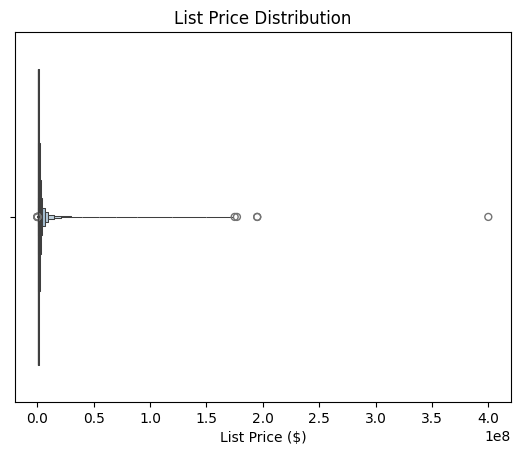

In [18]:
# boxplot for listing price distribution
sns.boxenplot(x=df_list_cleaned["ListPrice"])
plt.title("List Price Distribution")
plt.xlabel("List Price ($)")
plt.show()



There is highly expensive property listed $\$ \, 400,000,000$ and lowest price listed in $\$ \,1$. The lowest cost seem suspicious. Let's identify thsoe properties from lowest price listed in market.

In [19]:
df_list_cleaned["ListPrice"].nsmallest(20)

558070       1.0
281375     100.0
281446     100.0
363176     100.0
95         695.0
293155    1000.0
436590    1500.0
230280    2000.0
557913    2000.0
563612    2200.0
349036    2850.0
401528    2875.0
465117    2975.0
160315    3000.0
569478    3000.0
190132    3500.0
32627     4000.0
301801    5000.0
380042    5000.0
466190    5000.0
Name: ListPrice, dtype: float64

In [20]:
df_list_cleaned[df_list_cleaned["ListPrice"] < 10000][
    [
        "ListPrice",
        "OriginalListPrice",
        "LivingArea",
        "LotSizeAcres",
        "BedroomsTotal",
        "BathroomsTotalInteger",
        "CountyOrParish",
        "PropertySubType",

    ]
]

,ListPrice,OriginalListPrice,LivingArea,LotSizeAcres,BedroomsTotal,BathroomsTotalInteger,CountyOrParish,PropertySubType
95,695.0,695.0,1170.0,0.1846,3.0,2.0,Orange,SingleFamilyResidence
32627,4000.0,4000.0,1395.0,NaN,2.0,2.0,San Diego,Condominium
129416,9900.0,9900.0,600.0,NaN,1.0,1.0,San Diego,Timeshare
160315,3000.0,3000.0,990.0,NaN,1.0,1.0,San Diego,Condominium
190132,3500.0,3500.0,1349.0,NaN,2.0,2.0,San Mateo,Condominium
229323,9900.0,9900.0,2045.0,NaN,3.0,3.0,San Bernardino,Timeshare
230280,2000.0,2000.0,800.0,NaN,2.0,2.0,Riverside,Timeshare
235747,7500.0,7500.0,200.0,1.0000,1.0,1.0,San Diego,ManufacturedOnLand
281375,100.0,1.0,3479.0,1.9800,5.0,3.0,San Bernardino,SingleFamilyResidence
281446,100.0,100.0,2866.0,1.2500,3.0,3.0,San Bernardino,SingleFamilyResidence


Several listings were flagged as suspicious because their ListPrice values were extremely low relative to the property's size, bedroom count, and California residential market context. Examples included single-family residences listed for $1, $100, or a few thousand dollars despite having normal residential living areas. These records may represent placeholder prices, rental/lease amounts, auction-style listings, unusual ownership interests, or data-entry errors rather than standard residential sale listings.

Let's drop those suspicious low priced properties.

In [21]:
df_list_cleaned = df_list_cleaned[df_list_cleaned["ListPrice"] >= 10000]

We will produce the function of measurement outliers identifying upper and lower bound for statistical measure.

In [22]:
# function to measure the outliers of upper and lower bound
def function_calculation_outlier(df, col_num):
    q1 = df[col_num].quantile(0.25)

    q3 = df[col_num].quantile(0.75)

    IQR = q3 - q1

    lower = q1 - 1.5 * IQR

    upper = q3 + 1.5 * IQR     

    print(f"0.25 quantile is {q1}, and 0.75 quantile is {q3}")
    print()
    print(f"lower bound is {lower}, and upper bound is {upper}")

The close price depends on the location and property types. Insted of identifying outliers directly using only close price, we will group the location of counties and property subtypes to distinguish the outliers using IQR rule.


In [23]:
function_calculation_outlier(df_list_cleaned, "ListPrice")

0.25 quantile is 582000.0, and 0.75 quantile is 1380000.0

lower bound is -615000.0, and upper bound is 2577000.0


The overall outlier upper bound of list price records is $\$2,577,000$. However, the listed price are depend on the  location, and property construction type. Let's group it by property subtyes and county location with measuring each outlier of list price.

In [24]:
# function for boolean detecting outliers
def outliers_function(df, group_col, value_col):

    q1 = df.groupby(group_col)[value_col].transform(
        lambda x: x.quantile(0.25)
    )

    q3 = df.groupby(group_col)[value_col].transform(
        lambda x: x.quantile(0.75)
    )

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    df_outlier = (
        (df[value_col] < lower) |
        (df[value_col] > upper)
    )

    return df_outlier

In [25]:

# mark boolean that are outliers
outlier_listprice = outliers_function(df_list_cleaned, ["CountyOrParish", "PropertySubType"], "ListPrice") 

print("Proprotion of potential outliers of list price in each group of county and property subtype", outlier_listprice.sum()*100 / df_list_cleaned.shape[0]) 

# show number of properties outliers of close price
df_list_cleaned[outlier_listprice].shape

Proprotion of potential outliers of list price in each group of county and property subtype 7.772416791730367


(44332, 35)

There are potential outliers of $44,332$ properties of list price and it is about $7.8\%$ out of all listed in market. 

We will flag those outliers and drop it later on.

#### 1-b) Original List Price Outliers

There are couple properties that are outliers of listing price. We will not identify the original list price of outliers itself, because it is closely related to list price and not necessary to flag original list price after identifying outliers of list price.

 Let's identify the ratio of close price per listing price in sold properties.

Let's screen if there is suspicious outliers that listed accidently higher or lower for improving data quality. 

We can make a new feature that are ratio of list price per original list price, checking if how properties were listed above or below than original list price. **RatioOriginalList** will help us to check if there is suspicious ratio.

**Original list price is closely related to list price that we don't need to measure original list price outliers indivisually.**


In [26]:
# new feature of ratio list price / original list price
df_list_cleaned["RatioOriginalList"] = (
    df_list_cleaned["ListPrice"] /
    df_list_cleaned["OriginalListPrice"]
)

In [27]:
# summary of distribution
df_list_cleaned["RatioOriginalList"].describe()

count    5.703760e+05
mean     6.187462e+01
std      1.989381e+04
min      7.680484e-04
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.190000e+07
Name: RatioOriginalList, dtype: float64

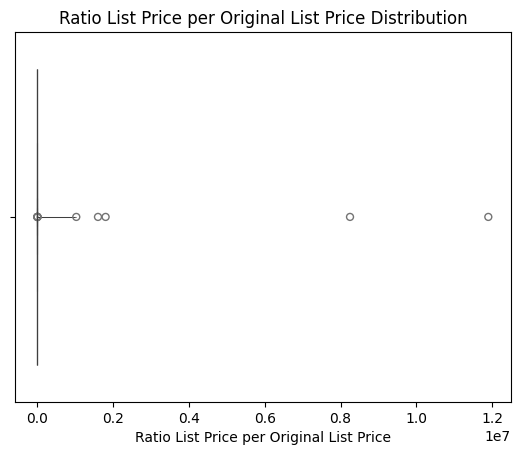

In [28]:
# boxplot for listing price distribution
sns.boxenplot(x=df_list_cleaned["RatioOriginalList"])
plt.title("Ratio List Price per Original List Price Distribution")
plt.xlabel("Ratio List Price per Original List Price")
plt.show()



There are high ratio of list price per original list price that the properties listed prices were way higher than orignal price. It is suspicious that ratio is less than 0.5 and over than 2 as broad data quality validity range.

In [29]:
## extract suspicious ratio greater than 2, less than 0.5
suspicious_ratio_originallist_price = (df_list_cleaned["RatioOriginalList"] < 0.5) | (df_list_cleaned["RatioOriginalList"] > 2)

# count suspicious properties
print("Total properties of suspicious ratio list / original list price:", df_list_cleaned[suspicious_ratio_originallist_price].shape[0])

# distribution of ratio by county and subtype
df_list_cleaned[suspicious_ratio_originallist_price][["CountyOrParish","PropertySubType"]].value_counts()

Total properties of suspicious ratio list / original list price: 1350


CountyOrParish  PropertySubType      
Los Angeles     SingleFamilyResidence    309
Riverside       SingleFamilyResidence    188
San Bernardino  SingleFamilyResidence    165
Orange          SingleFamilyResidence    121
San Diego       SingleFamilyResidence     60
                                        ... 
Siskiyou        SingleFamilyResidence      1
Stanislaus      Triplex                    1
Tehama          ManufacturedOnLand         1
Sutter          SingleFamilyResidence      1
Tuolumne        SingleFamilyResidence      1
Name: count, Length: 91, dtype: int64

There are many suspicious properties of single family residence in **Los Angeles, Riverside, and San Bernardino** that have been either 2 times more expensive listed than original price, or less than half times listed than original price.

The total $1,350$ properties were suspicious in sold properties California over half years. We will flag those suspicious properties due to data quality issue.

We will flag those outliers first, then we will drop it later on.

### 2) Living Area

There is explicit missing values of living area about 0.1% and we will exclude those minor properties. 

In [30]:
df_list_cleaned = df_list_cleaned.dropna(subset=["LivingArea"])
df_list_cleaned["LivingArea"].isna().sum() 

np.int64(0)

Let's check if there is invalid values.

In [31]:
# identify rows of properties that has 0 or negative living area size (invalid)
print("invalid living area size:", df_list_cleaned[df_list_cleaned["LivingArea"]<0].shape[0])
print("0 living area size:", df_list_cleaned[df_list_cleaned["LivingArea"]==0].shape[0])

invalid living area size: 0
0 living area size: 374


There is $374$ rows that are living area size is 0 and there is no negative, and it usually means the value is missing, unknown, or incorrectly recoreded rather than having no living space. Let's identify if it is invalid.

In [32]:
livingarea_property = df_list_cleaned[df_list_cleaned["LivingArea"]==0]["PropertySubType"].value_counts()

livingarea_property

PropertySubType
SingleFamilyResidence    262
MobileHome                88
Condominium               16
OwnYourOwn                 3
Duplex                     2
Triplex                    1
ManufacturedOnLand         1
Name: count, dtype: int64

For resident type of resident unit, those are most likely invalid or a missing value place holder. We will drop and mark those invalid properties.

In [33]:
# exclude invalid values
df_list_cleaned = df_list_cleaned[df_list_cleaned['LivingArea']>0]



#### 2-a) Living Area Outliers

Let's explore the outliers of living area properties checking its distribution.

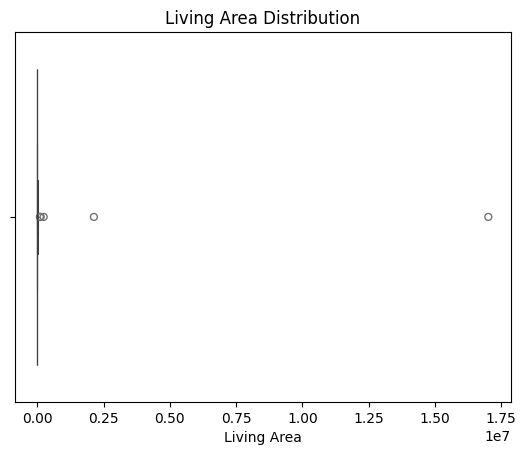

In [34]:
# show the distribution of living area
sns.boxenplot(x=df_list_cleaned["LivingArea"])
plt.title("Living Area Distribution")
plt.xlabel("Living Area")
plt.show()


There are extreme living area size. Those large extreme living area can affect living area distribution summaries and any analysis of the relationship between other features.

In [35]:
# function measuring upper outliers 
def outliers_calculation(df, value_col):
    q1 = df[value_col].quantile(0.25)
    q3 = df[value_col].quantile(0.75)

    iqr = q3 - q1

    upper = q3 + 1.5 * iqr

    return upper

In [36]:
outliers_calculation(df_list_cleaned, "LivingArea")

np.float64(3880.5)

The overall living area upper bound is $3,880.5 \,sqft$ size. 

Let's define the outliers of living area. We identified there were minimum properties that were containing extreme living area size over $250000 \,sqft$ in previous boxplot. Let's identify what features they have.


In [37]:
max_livingarea = df_list_cleaned[df_list_cleaned["LivingArea"] > 2500000]

print("Dimension of extreme living area properties:", max_livingarea.shape)
max_livingarea[
    [
        "PropertySubType", 
        "ListPrice", 
        "OriginalListPrice", 
        "LivingArea", 
        "LotSizeAcres", 
        "BathroomsTotalInteger",
        "BedroomsTotal",
        "CountyOrParish"
    ]
]



Dimension of extreme living area properties: (1, 36)


,PropertySubType,ListPrice,OriginalListPrice,LivingArea,LotSizeAcres,BathroomsTotalInteger,BedroomsTotal,CountyOrParish
310344,Townhouse,616000.0,616000.0,17021321.0,0.0,3.0,2.0,San Diego


There was only one property that were extreme living area size in San Diego living area $17,021,321 \,sqft$ with $3$ bathrooms and $2$ bedrooms. It is suspicious property if we consider the living size and other features. We will treat this as invalid value.


The living area sizes are depends on property subtypes considering building designs. We will group living area sizes by property subtyes and calculate the outlier boundaries.

Later on, we will do feature engineer of producing **ListPerSqft = ListPrice / LivingArea** that it matters calculating price per sqft filtering out unusual living area and close price.


In [38]:
outlier_livingarea = outliers_function(df_list_cleaned, ["PropertySubType"], "LivingArea")

df_list_cleaned["Outlier_livingarea"] = outlier_livingarea

print("Proprotion of potential outliers of living area in each group of county and property subtype", outlier_livingarea.sum()*100 / df_list_cleaned.shape[0]) 

# show number of properties outliers of close price
df_list_cleaned["Outlier_livingarea"].sum()

Proprotion of potential outliers of living area in each group of county and property subtype 4.277984710946267


np.int64(24360)

There are about $4.28\%$ of outliers living area, which $24,360$ properties. We will flag those outlier of living area. 

Let's screen if there is suspicous outliers using ratio of list price per living area.

In [39]:

df_list_cleaned["ListPerSqft"] = df_list_cleaned["ListPrice"] / df_list_cleaned["LivingArea"]

df_list_cleaned["ListPerSqft"].describe()


count    5.694270e+05
mean     7.018904e+02
std      3.435109e+04
min      3.618991e-02
25%      3.752134e+02
50%      5.482456e+02
75%      7.550101e+02
max      2.495000e+07
Name: ListPerSqft, dtype: float64

Text(0.5, 0, 'List Price per Living Area ($ / sqft)')

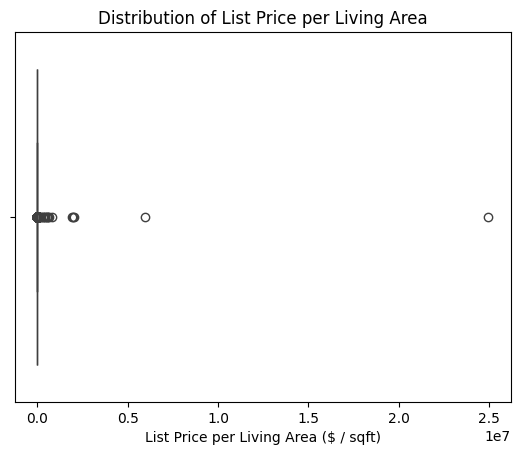

In [40]:
sns.boxplot(x = df_list_cleaned["ListPerSqft"])
plt.title("Distribution of List Price per Living Area")
plt.xlabel("List Price per Living Area ($ / sqft)")

We can identify that the maximum value is $24,950,000 \, \$/sqft$ and it must be either invalid value of extreme small living area. Let's identify those extreme ratio properties.

The extreme ratio remained similar in both before and after handling outliers of close price grouped by county and property subtypes and living area grouped by property subtypes, which means that there are some properties that are expensive in small or mild living area size. Let's identify those properties using important features of close price, living area, price per sqft, county, property subtypes, bathroom, and bedrooms.

Let's identify the properties over than 10,000 ratio value.

In [41]:
# outlier ratio over than 100,000 ratio
outlier_pricesqft = df_list_cleaned[df_list_cleaned["ListPerSqft"] > 10000]

# extract features from outlier points
outlier_pricesqft = outlier_pricesqft[
    [
        "ListPrice",
        "OriginalListPrice",
        "LivingArea",
        "ListPerSqft",
        "CountyOrParish",
        "PropertySubType",
        "BathroomsTotalInteger",
        "BedroomsTotal"
    ]
].sort_values("ListPerSqft", ascending = False)

print("Number of properties with suspicious ratio:", outlier_pricesqft.shape[0])
outlier_pricesqft.head()

Number of properties with suspicious ratio: 71


,ListPrice,OriginalListPrice,LivingArea,ListPerSqft,CountyOrParish,PropertySubType,BathroomsTotalInteger,BedroomsTotal
309977,24950000.0,24950000.0,1.0,24950000.0,Marin,Farm,1.0,2.0
303576,5950000.0,5950000.0,1.0,5950000.0,Santa Clara,NaN,0.0,0.0
255985,3995000.0,3995000.0,2.0,1997500.0,Ventura,SingleFamilyResidence,5.0,2.0
564783,1950000.0,3950000.0,1.0,1950000.0,San Mateo,SingleFamilyResidence,1.0,1.0
139493,1900000.0,220000.0,1.0,1900000.0,Santa Barbara,SingleFamilyResidence,1.0,2.0


There there are $71$ properties that has less living area that are suspicious This is unusual properties that has less living area size containing bedrooms and bathrooms, which is suspicious properties.

Text(0.5, 0, 'Close Price per Living Area ($ / sqft)')

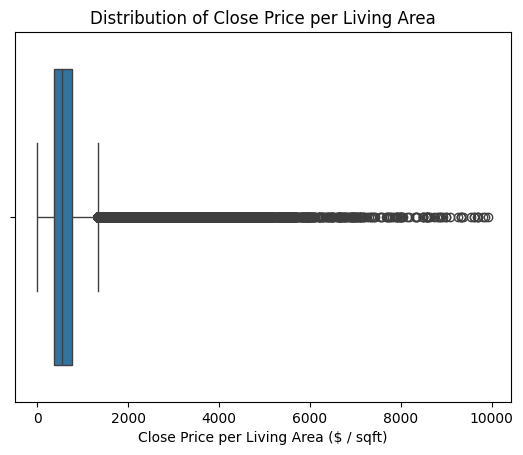

In [42]:
# take out two invalid properties
df_list_cleaned = df_list_cleaned[df_list_cleaned["ListPerSqft"] < 10000]

# show distribution of boxplot for price per sqft
sns.boxplot(x = df_list_cleaned["ListPerSqft"])
plt.title("Distribution of Close Price per Living Area")
plt.xlabel("Close Price per Living Area ($ / sqft)")

Let's check other values of ratio threshold that are greater than 2,500 ratio.

In [43]:
outlier_pricesqft = df_list_cleaned[df_list_cleaned["ListPerSqft"] > 2500]

outlier_pricesqft = outlier_pricesqft[
    [
        "ListPrice",
        "OriginalListPrice",
        "LivingArea",
        "ListPerSqft",
        "CountyOrParish",
        "PropertySubType",
        "BathroomsTotalInteger",
        "BedroomsTotal"
    ]
].sort_values("ListPerSqft", ascending = False)

print("Number of properties with suspicious ratio:", outlier_pricesqft.shape[0])
outlier_pricesqft.head()

Number of properties with suspicious ratio: 3314


,ListPrice,OriginalListPrice,LivingArea,ListPerSqft,CountyOrParish,PropertySubType,BathroomsTotalInteger,BedroomsTotal
74631,7999999.0,7999999.0,806.0,9925.557072,Los Angeles,SingleFamilyResidence,1.0,1.0
159127,39995000.0,39995000.0,4061.0,9848.559468,Orange,SingleFamilyResidence,7.0,4.0
368084,32000000.0,32000000.0,3261.0,9812.940816,Monterey,SingleFamilyResidence,4.0,4.0
16960,39000000.0,53000000.0,4021.0,9699.079831,Los Angeles,SingleFamilyResidence,5.0,4.0
294121,39000000.0,39000000.0,4021.0,9699.079831,Los Angeles,SingleFamilyResidence,5.0,4.0


These $3,314$ properties seem valid that has enough living area containing bathroom and bedrooms. Let's identify the properties that are containing $2$ bathrooms and bedrooms with less than $300 \, sqft$ living area that are unuausal sold price.

In [44]:
# properties less than 300 livinga area with containing 2 bedrooms and 2 bedrooms
suspicous_small_area = (
    (df_list_cleaned["LivingArea"] < 300) 
    &
    (
        (df_list_cleaned["BedroomsTotal"] >= 2) 
        |
        (df_list_cleaned["BathroomsTotalInteger"] >= 2)
    )
)


print("Number of suspicious properties considering living area:", suspicous_small_area.sum())
df_list_cleaned[suspicous_small_area][
    [
            "ListPrice",
            "OriginalListPrice",
            "LivingArea",
            "ListPerSqft",
            "CountyOrParish",
            "PropertySubType",
            "BathroomsTotalInteger",
            "BedroomsTotal"
        ]
]

Number of suspicious properties considering living area: 21


,ListPrice,OriginalListPrice,LivingArea,ListPerSqft,CountyOrParish,PropertySubType,BathroomsTotalInteger,BedroomsTotal
56375,1800000.0,1800000.0,261.0,6896.551724,Ventura,Duplex,3.0,4.0
62458,80000.0,80000.0,294.0,272.108844,Lake,ManufacturedOnLand,2.0,1.0
87374,425000.0,425000.0,137.0,3102.189781,Kern,SingleFamilyResidence,2.0,4.0
132530,275000.0,275000.0,100.0,2750.000000,Kern,Duplex,1.0,2.0
132818,325000.0,325000.0,100.0,3250.000000,Kern,SingleFamilyResidence,2.0,4.0
157046,175000.0,175000.0,242.0,723.140496,Other County,SingleFamilyResidence,3.0,4.0
168791,649000.0,649000.0,100.0,6490.000000,Trinity,ManufacturedOnLand,1.0,2.0
169213,275000.0,275000.0,100.0,2750.000000,Kern,SingleFamilyResidence,2.0,4.0
170244,859900.0,859900.0,100.0,8599.000000,Los Angeles,SingleFamilyResidence,1.0,2.0
178909,120000.0,120000.0,250.0,480.000000,Lake,ManufacturedOnLand,2.0,1.0


There are suspicious $21$ properties that were containing 2 beds or 2 bathrooms with small living space. We will flag those suspicious properties of small living area.

#### 3) Lot Size

Let's check if there is invalid value and exclude previous 8.2% of explicit missing values as well.

In [45]:
# drop the missing values of lot size
df_list_cleaned = df_list_cleaned.dropna(subset=["LotSizeAcres"])
df_list_cleaned["LotSizeAcres"].isna().sum()

np.int64(0)

In [46]:
# show negative and 0 lot size
print("invalid lot size:", df_list_cleaned[df_list_cleaned["LotSizeAcres"]<0].shape[0])
print("0 lot size:", df_list_cleaned[df_list_cleaned["LotSizeAcres"]==0].shape[0])

invalid lot size: 0
0 lot size: 12477


There is 0 invalid properties, but $12,477$ properties that has no lot area. Let's identify those properties that has no lot size if those are valid.

In [47]:
# show property subtypes that are no lot size
lot_property = df_list_cleaned[df_list_cleaned["LotSizeAcres"]==0]["PropertySubType"].value_counts()

lot_property

PropertySubType
Condominium              10573
Townhouse                 1108
SingleFamilyResidence      618
ManufacturedOnLand          93
ManufacturedHome            14
Duplex                      13
Cabin                        8
StockCooperative             6
Loft                         5
MixedUse                     1
Triplex                      1
Name: count, dtype: int64

The patterns here that condominium and town house zero is often understandable because the land may be shared by development rather than assigned to each unit. Also, some town house structured more like condominiums.

However, other subtypes are more suspicious as missing MLS data, data entry issues, or lot size field was not supplied. Let's mark those as invalid values and drop.

In [48]:
# extract subtypes that has less than 700 counts
invalid_lot_idx = lot_property[lot_property < 700].index

invalid_lot_idx

Index(['SingleFamilyResidence', 'ManufacturedOnLand', 'ManufacturedHome',
       'Duplex', 'Cabin', 'StockCooperative', 'Loft', 'MixedUse', 'Triplex'],
      dtype='object', name='PropertySubType')

In [49]:
# extract invalid lot that has 0 lot
invalid_lot = (
    df_list_cleaned["LotSizeAcres"].eq(0)
    & df_list_cleaned["PropertySubType"].isin(invalid_lot_idx)
)

# point out rows that are not invalid lot size
df_sold_cleaned = df_list_cleaned.loc[~invalid_lot]


#### 3-a) Lot Size Outliers

Let's identify the properties if those contain outliers in terms of lot size. 

In [50]:
df_list_cleaned["LotSizeAcres"].describe()

count    5.227250e+05
mean     6.279142e+01
std      1.181940e+04
min      0.000000e+00
25%      1.200000e-01
50%      1.700000e-01
75%      3.136000e-01
max      4.187292e+06
Name: LotSizeAcres, dtype: float64

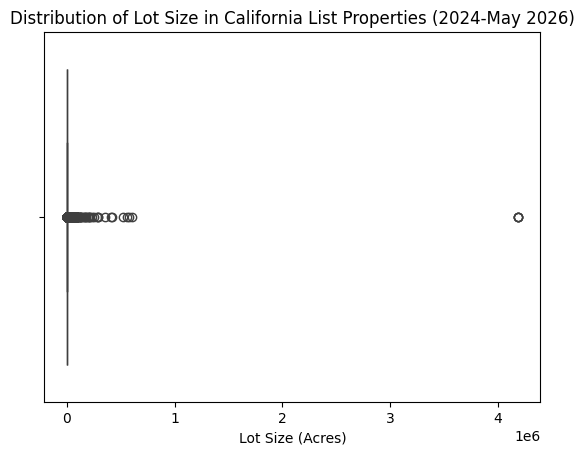

In [51]:
sns.boxplot(x=df_list_cleaned["LotSizeAcres"])
plt.title("Distribution of Lot Size in California List Properties (2024-May 2026)")
plt.xlabel("Lot Size (Acres)")
plt.show()

There are properties that contains extreme lot sizes. It might be the properties for farm or any rural area that contains large lot compare to other city residence.

In [52]:
outliers_calculation(df_list_cleaned, "LotSizeAcres")

np.float64(0.604)

The overall upper bound of lot size is approximately $0.604$ acres.

In [53]:
# mark boolean that are outliers
outlier_lotsize = outliers_function(df_list_cleaned, ["CountyOrParish", "PropertySubType"], "LotSizeAcres")

print("Proprotion of potential outliers of lot size in each group of county and property subtype", outlier_lotsize.sum()*100 / df_list_cleaned.shape[0]) 

# show number of properties outliers of lot size
df_list_cleaned[outlier_lotsize].shape

Proprotion of potential outliers of lot size in each group of county and property subtype 12.073652494141278


(63112, 38)

There are $12.08 \, \%$ of $63,112$ properties that are considered as potential outliers. Lot size is vary too much between property features and location. We will flag out using statistical outliers above **outlier_lotsize**.

### 4) Bedrooms

There was about $0.025 \, \%$ missing values in bedrooms total. We will drop those values.

In [54]:
# drop missing values from bedrooms total
df_list_cleaned = df_list_cleaned.dropna(subset = ["BedroomsTotal"])

Let's check if there is invalid and $0$ bedrooms.

In [55]:
# show number of bedrooms less than 0
print("Invalid number of bedroom:", (df_list_cleaned["BedroomsTotal"]<0).sum())
print("0 bedrooms:", (df_list_cleaned["BedroomsTotal"]==0).sum())

Invalid number of bedroom: 0
0 bedrooms: 1672


There are $1,672$ properties that are 0 bedrooms. Let's inspect what are those properties.

In [56]:
# list of property types that have 0 bedroom
df_list_cleaned[df_list_cleaned["BedroomsTotal"]==0]["PropertySubType"].value_counts()

PropertySubType
Condominium              962
SingleFamilyResidence    300
Cabin                    165
BoatSlip                  70
MixedUse                  42
Studio                    35
OwnYourOwn                20
MobileHome                19
ManufacturedOnLand        13
StockCooperative           7
Townhouse                  4
Duplex                     3
Triplex                    3
Loft                       2
CoOwnership                2
ManufacturedHome           1
Farm                       1
Quadruplex                 1
Name: count, dtype: int64

- The zero bedrooms property subtypes that are **Studio, Loft, StockCooperative, OwnYourOwn, and CoOwnership** can legitimately be studio-style units. BoatSlip can reasonably have 0 bedrooms, although it may not belong in a residential-home analysis. MixedUse may also legitimately have 0 bedrooms depending on what was sold.

- However, **Condominium, SingleFamilyResidence, Cabin,  Farm, MobileHome, ManufacturedOnLand, Townhouse, MixedUse, Duplex, Triplex, and Quadruplex** are more suspicious that properties were sold, $0$ may mean the bedroom value was never reported correctly rather than the entire transaction being invalid.

In [57]:
# list of valid property types 
likely_valid_zero_bed = [
    "Studio",
    "Loft",
    "StockCooperative",
    "OwnYourOwn",
    "CoOwnership",
    "BoatSlip"
]

# call out suspicious properties with 0 beds
invalid_bedrooms = (
    (
        df_list_cleaned["BedroomsTotal"]==0)
        & (~df_list_cleaned["PropertySubType"].isin(likely_valid_zero_bed)
    )
)

# drop suspicious properties
df_list_cleaned = df_list_cleaned.loc[~invalid_bedrooms]

##### 4-a) Bedroom Outliers

Let's inspect if there is outliers of bedrooms across sold Californaia properties.

In [58]:
# show the list of propoortions in each number of bedrooms
prob_bed = df_list_cleaned["BedroomsTotal"].value_counts(normalize=True).sort_values(ascending=False)*100

prob_bed

BedroomsTotal
3.0     38.332355
4.0     27.358570
2.0     18.966616
5.0      9.146260
1.0      3.351102
6.0      1.964532
7.0      0.516750
8.0      0.179989
9.0      0.066393
10.0     0.038569
0.0      0.026097
11.0     0.015159
12.0     0.011321
13.0     0.004797
14.0     0.003646
15.0     0.003454
16.0     0.003454
18.0     0.001535
17.0     0.001343
20.0     0.001151
26.0     0.000959
34.0     0.000768
45.0     0.000576
23.0     0.000576
32.0     0.000384
24.0     0.000384
37.0     0.000384
21.0     0.000384
19.0     0.000384
72.0     0.000192
33.0     0.000192
94.0     0.000192
40.0     0.000192
25.0     0.000192
31.0     0.000192
71.0     0.000192
36.0     0.000192
22.0     0.000192
57.0     0.000192
39.0     0.000192
Name: proportion, dtype: float64

We already inspected 0 bedrooms. There are sparse properties over than 7 bedrooms and 0 beds that have less then 1 percent from sold properties that has less observations. For reliable analysis, we would need to handle those sparse properties.

In [59]:
# show bedrooms largest 20th with other features
df_list_cleaned.nlargest(
    20, "BedroomsTotal"
)[
    ["PropertySubType", "BedroomsTotal",
     "BathroomsTotalInteger", "LivingArea",
     "ListPrice", "OriginalListPrice", "CountyOrParish"]
]

,PropertySubType,BedroomsTotal,BathroomsTotalInteger,LivingArea,ListPrice,OriginalListPrice,CountyOrParish
47462,MixedUse,94.0,0.0,54356.0,1960000.0,1960000.0,Los Angeles
112763,Condominium,72.0,48.0,28800.0,8750000.0,8750000.0,Kern
337813,Condominium,71.0,67.0,37778.0,16000000.0,16000000.0,Los Angeles
502045,SingleFamilyResidence,57.0,40.0,50000.0,58000000.0,78000000.0,Ventura
189857,SingleFamilyResidence,45.0,45.0,10248.0,1500000.0,1500000.0,Los Angeles
263001,SingleFamilyResidence,45.0,45.0,10248.0,1680000.0,1680000.0,Los Angeles
333740,SingleFamilyResidence,45.0,45.0,10248.0,1600000.0,1600000.0,Los Angeles
208855,SingleFamilyResidence,40.0,4.0,2862.0,884438.0,884438.0,Kern
524874,SingleFamilyResidence,39.0,59.0,70000.0,400000000.0,400000000.0,Los Angeles
250393,SingleFamilyResidence,37.0,22.0,24062.0,29800000.0,29800000.0,Santa Clara


There are suspicious properties that has over 10 bedrooms with less living area size less then 2000 sqft. Usually high bedrooms counts should come with enough living space to make those counts plausible, such as Single Family Residence of $32$ bedrooms and $2$ bathroom with $1,287 \, sqft$ of living space. 

In [60]:
# extract more than equal to 6 bedrooms
high_bed = df_list_cleaned[
    df_list_cleaned["BedroomsTotal"] >= 6
][
    [
        "BedroomsTotal",
        "BathroomsTotalInteger",
        "LivingArea",
        "PropertySubType",
        "ListPrice",
        "OriginalListPrice",
        "CountyOrParish"
    ]
].sort_values("BedroomsTotal", ascending=False)


high_bed.shape

(14691, 7)

There are $14,691$ properties that contain more than 5 bedrooms. We cannot inspect every single property that seems suspicious in terms of number of beds. We will use brief screening usins ratio of living area / bedrooms that if ratio is small, it might be suspicious of data entry errors. Usually the constructions build 1000 sqft with 2 beds and 2 bathrooms. 

A general U.S. housing guide notes that a 1,000-square-foot apartment typically contains one or two bedrooms and one or two bathrooms, providing a practical reference for identifying unusually dense bedroom-to-living-area combinations (CORT, 2026). Based on this general reference and the observed distribution in the dataset, properties with unusually high bedroom counts and less than 200 square feet of total living area per reported bedroom were flagged for further review. The 200-square-foot threshold was used as a conservative screening criterion rather than as an official housing or MLS validity standard.

source : https://blog.cort.com/moving/1000-sq-ft/ 


So, we will use brief screening if the ratio is less then $200$ sqft / per beds.

In [61]:
# inspect suspicious ratio of living area / beds
suspicious_bedroom = (
    (df_list_cleaned["BedroomsTotal"] >= 6)
    &
    (df_list_cleaned["LivingArea"] /
     df_list_cleaned["BedroomsTotal"] < 200)
)

print("Suspicous properties with number of beds", suspicious_bedroom.sum())
df_list_cleaned[suspicious_bedroom][
    [
        "BedroomsTotal",
        "BathroomsTotalInteger",
        "LivingArea",
        "LotSizeAcres",
        "PropertySubType",
        "ListPrice",
        "OriginalListPrice",
        "CountyOrParish"
    ]
]

Suspicous properties with number of beds 50


,BedroomsTotal,BathroomsTotalInteger,LivingArea,LotSizeAcres,PropertySubType,ListPrice,OriginalListPrice,CountyOrParish
12710,6.0,2.0,960.0,0.5550,SingleFamilyResidence,449900.0,449900.0,Lake
43479,12.0,3.0,2392.0,0.0545,NaN,850000.0,850000.0,San Francisco
55916,33.0,2.0,1393.0,0.1800,SingleFamilyResidence,488000.0,488000.0,Los Angeles
76116,7.0,4.0,1072.0,0.2200,SingleFamilyResidence,999000.0,1049000.0,Santa Barbara
81454,7.0,3.0,928.0,2.7200,Triplex,2200000.0,2200000.0,Riverside
92168,7.0,2.0,1250.0,0.0900,SingleFamilyResidence,699000.0,699000.0,Santa Clara
115630,6.0,4.0,1060.0,0.2100,SingleFamilyResidence,1080000.0,1080000.0,Santa Clara
118401,8.0,5.0,1172.0,0.2200,SingleFamilyResidence,1249000.0,1288880.0,Santa Clara
118487,8.0,6.0,1596.0,0.2600,SingleFamilyResidence,1249000.0,1249000.0,Santa Clara
126548,34.0,5.0,4060.0,0.1646,SingleFamilyResidence,2050000.0,2050000.0,Orange


We flag $50$ properties that were suspicious number of beds considering living area size. 

### 5) Bathrooms

First, we will drop explicit missing values that were $0.001\%$ in the sold dataset.

In [62]:
# drop explicit missing value of bathroom
df_list_cleaned = df_list_cleaned.dropna(subset=["BathroomsTotalInteger"])

Then we will check if there is invalid or 0 bathrooms.

In [63]:
# show invalid and 0 bathroom
print("Number of properties with number of invalid bathroom", (df_list_cleaned["BathroomsTotalInteger"]<0).sum())
print("Number of properties with number of no bathroom", (df_list_cleaned["BathroomsTotalInteger"]==0).sum())


Number of properties with number of invalid bathroom 0
Number of properties with number of no bathroom 153


There are no negative bathrooms. However, there are $153$ properties that have 0 bathrooms. Let's inspect what are those property types are.

In [64]:
# list of property types that has 0 bathroom
df_list_cleaned[df_list_cleaned["BathroomsTotalInteger"]==0]["PropertySubType"].value_counts()

PropertySubType
BoatSlip                 70
SingleFamilyResidence    53
Cabin                    18
ManufacturedOnLand        3
Condominium               2
OwnYourOwn                1
MixedUse                  1
Townhouse                 1
Duplex                    1
Farm                      1
Quadruplex                1
Name: count, dtype: int64

The properties are listed above, are suspicious that should have at least one bathrooms.

We will drop those suspicious properties that has no bathrooms.

In [65]:
# list of valid property types 
likely_valid_zero_bath = ["BoatSlip"]

# call out suspicious properties with 0 bathroom
invalid_bathrooms = (
    (
        df_list_cleaned["BedroomsTotal"]==0)
        & (~df_list_cleaned["PropertySubType"].isin(likely_valid_zero_bath)
    )
)

# drop suspicious properties
df_list_cleaned = df_list_cleaned.loc[~invalid_bathrooms]

#### 5-a) Bathroom Outliers

Let's identify the outliers of bathrooms.

In [66]:
# show the list of propoortions in each number of bedrooms
prob_bath = df_list_cleaned["BathroomsTotalInteger"].value_counts(normalize=True).sort_values(ascending=False)*100

prob_bath

BathroomsTotalInteger
2.0       41.476391
3.0       32.648486
1.0       10.681693
4.0        8.579939
5.0        3.622939
6.0        1.591046
7.0        0.659641
8.0        0.313987
9.0        0.171004
10.0       0.081184
11.0       0.051052
0.0        0.029364
12.0       0.029172
13.0       0.019576
14.0       0.014394
15.0       0.007293
16.0       0.004990
20.0       0.002879
17.0       0.002687
22.0       0.001727
18.0       0.001535
21.0       0.001535
25.0       0.001343
32.0       0.000960
19.0       0.000768
26.0       0.000768
45.0       0.000576
27.0       0.000384
23.0       0.000384
24.0       0.000384
48.0       0.000192
153.0      0.000192
33.0       0.000192
2208.0     0.000192
67.0       0.000192
35.0       0.000192
36.0       0.000192
40.0       0.000192
59.0       0.000192
46.0       0.000192
Name: proportion, dtype: float64

There are couple properties that has extreme number of bathrooms over 20. Let's briefly check what features of those properties contain .

In [67]:
# show bathrooms largest 20th with other features
df_list_cleaned.nlargest(
    20, "BathroomsTotalInteger"
)[
    [
        "PropertySubType",
        "BedroomsTotal",
        "BathroomsTotalInteger", 
        "LivingArea",
        "ListPrice",
        "OriginalListPrice", 
        "CountyOrParish"
    ]
]

,PropertySubType,BedroomsTotal,BathroomsTotalInteger,LivingArea,ListPrice,OriginalListPrice,CountyOrParish
312182,SingleFamilyResidence,4.0,2208.0,2209.0,759000.0,759000.0,Riverside
238098,SingleFamilyResidence,3.0,153.0,1289.0,821000.0,821000.0,Los Angeles
337813,Condominium,71.0,67.0,37778.0,16000000.0,16000000.0,Los Angeles
524874,SingleFamilyResidence,39.0,59.0,70000.0,400000000.0,400000000.0,Los Angeles
112763,Condominium,72.0,48.0,28800.0,8750000.0,8750000.0,Kern
544826,SingleFamilyResidence,37.0,46.0,42243.0,105000000.0,105000000.0,Los Angeles
189857,SingleFamilyResidence,45.0,45.0,10248.0,1500000.0,1500000.0,Los Angeles
263001,SingleFamilyResidence,45.0,45.0,10248.0,1680000.0,1680000.0,Los Angeles
333740,SingleFamilyResidence,45.0,45.0,10248.0,1600000.0,1600000.0,Los Angeles
502045,SingleFamilyResidence,57.0,40.0,50000.0,58000000.0,78000000.0,Ventura


There are suspicious properties that has extreme bathrooms are more than number of bedrooms such as 3 beds with 153 bathrooms in second index above. We will consider this unusual outliers as invalid. 

We will use the living area per bathrooms ratio just like previous process in detecting suspicious living area outliers. This time, we will use less than 300 sqft per bathrooms, because in 1000 sqft, at most 3 bathrooms are reasonably acceptable case to be constructed in usual case. 

In [68]:
# inspect suspicious ratio of living area / beds
suspicious_bathroom = (
    (df_list_cleaned["BathroomsTotalInteger"] >= 6)
    &
    (df_list_cleaned["LivingArea"] /
     df_list_cleaned["BathroomsTotalInteger"] < 300)
)

# show the results of less than 300 ratio 

print("Suspicious outliers properties with number of bathroom considering living area", suspicious_bathroom.sum())
df_list_cleaned[suspicious_bathroom][
    [
        "BedroomsTotal",
        "BathroomsTotalInteger",
        "LivingArea",
        "LotSizeAcres",
        "PropertySubType",
        "ListPrice",
        "OriginalListPrice",
        "CountyOrParish"
    ]
]

Suspicious outliers properties with number of bathroom considering living area 71


,BedroomsTotal,BathroomsTotalInteger,LivingArea,LotSizeAcres,PropertySubType,ListPrice,OriginalListPrice,CountyOrParish
11204,4.0,21.0,2382.0,0.0800,SingleFamilyResidence,899000.0,899000.0,Alameda
24277,3.0,12.0,1536.0,0.2000,SingleFamilyResidence,329000.0,329000.0,Riverside
24742,8.0,8.0,1937.0,0.1700,Duplex,1499000.0,1590000.0,Orange
33327,6.0,6.0,1682.0,349.0100,SingleFamilyResidence,5900000.0,4780000.0,Riverside
39161,4.0,6.0,1548.0,0.1751,Triplex,1250000.0,1250000.0,Los Angeles
...,...,...,...,...,...,...,...,...
512965,16.0,16.0,4448.0,0.1722,SingleFamilyResidence,1850000.0,1850000.0,Los Angeles
518906,8.0,14.0,3345.0,13.6500,SingleFamilyResidence,9950000.0,9950000.0,Riverside
545246,6.0,6.0,1364.0,0.3824,SingleFamilyResidence,789000.0,789000.0,San Bernardino
554522,4.0,8.0,2000.0,0.5739,SingleFamilyResidence,888000.0,910800.0,San Bernardino


These are the $71$ properties that has suspicious number of bathrooms. We will flag those suspicious outliers.

#### 6) Days On Market

There is no explicit and implicit missing values for days on market feature. Let's identify if there is invalid value.

In [69]:
# show invalid and 0 days of market
print("invalid days on market:", df_list_cleaned[df_list_cleaned["DaysOnMarket"]<0].shape[0])
print("0 days in market:", df_list_cleaned[df_list_cleaned["DaysOnMarket"]==0].shape[0])

invalid days on market: 28
0 days in market: 26137


There is $28$ properties that were listed and sold that went pending or closed on the same day. However, the negative days on market are impossible entries for sold markets. We will drop those $26$ invalid listed market days.

Additionally, there are many properties of $26,137$ that were listed only a day and sold right away.

In [70]:
# drop negative days of market
df_list_cleaned = df_list_cleaned[df_list_cleaned["DaysOnMarket"]>=0]
(df_list_cleaned["DaysOnMarket"]<0).sum()

np.int64(0)

We want to identify the general market performance and removing outlliers of days on market would likely harm analyzing overall picture of it. We will pass on this flagging for days on market.

#### 7) Year Built

There was about $0.17\%$ of explicit missing values for years built, and we will drop those minimal values.

In [71]:
# drop explicit missing values of years built
df_list_cleaned = df_list_cleaned.dropna(subset=['YearBuilt'])

df_list_cleaned["YearBuilt"].isna().sum()

np.int64(0)

Let's check its distribution.

In [72]:
df_list_cleaned["YearBuilt"].value_counts()

YearBuilt
2024.0    11105
1989.0    10683
1979.0     9663
2005.0     9464
1990.0     9361
          ...  
1776.0        1
1854.0        1
1855.0        1
1873.0        1
1792.0        1
Name: count, Length: 174, dtype: int64



Let's transfer the built years into age based on the year of $2026$ for more easier picture to understand the distribution of properties years built.

In [73]:
# transfer the age from 2026
df_list_cleaned["PropertyAge"] = 2026 - df_list_cleaned["YearBuilt"]

df_list_cleaned["PropertyAge"].value_counts(normalize=True).sort_values(ascending=False) *100

PropertyAge
2.0      2.133755
37.0     2.052670
47.0     1.856684
21.0     1.818447
36.0     1.798657
           ...   
250.0    0.000192
172.0    0.000192
171.0    0.000192
153.0    0.000192
234.0    0.000192
Name: proportion, Length: 174, dtype: float64

- The highest frequency of sold properties were 2 years old about $2.13\%$ across California.

- Also, properties built in 37 years old properties were sold most of 2nd about $2.05\%$. 

Let's check if there is invalid age of properties.

In [74]:
print("invalid age of properties:", df_list_cleaned[df_list_cleaned["PropertyAge"]<0].shape[0])
print("Brand new properties:", df_list_cleaned[df_list_cleaned["PropertyAge"]==0].shape[0])

invalid age of properties: 25
Brand new properties: 2935


There was $25$ invalid properties that were negative age, and there are $2,935$ brand new properties that were built in this year of 2026. We will drop those invalid negative age properties.

In [75]:
df_list_cleaned = df_list_cleaned[df_list_cleaned["PropertyAge"] >= 0]

#### 7-a) Property Age Outlier

Now, let's identify if there is potential outliers using statistical distribution of property age instead of built years.

In [76]:
# summary of distribution of property age
df_list_cleaned["PropertyAge"].describe()

count    520419.000000
mean         47.406861
std          27.115537
min           0.000000
25%          26.000000
50%          47.000000
75%          66.000000
max         250.000000
Name: PropertyAge, dtype: float64

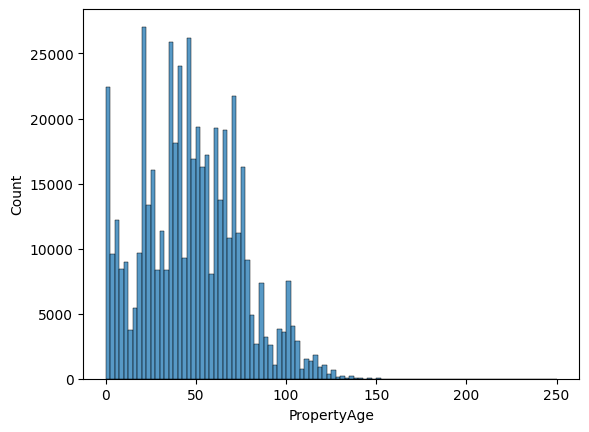

In [77]:
sns.histplot(x = df_list_cleaned["PropertyAge"], bins = 100)
plt.show()

Most of the properties was aound $47$ years sold. The maximum age was 250 years old and minimum age is of course, built this year 2026.

The property ages depends on location and property subtypes, and we will detect potential outliers using IQR statistical measurement using those two features.

In [78]:
# calculate the property age outliers
outlier_age = outliers_function(df_list_cleaned, ["CountyOrParish", "PropertySubType"], "PropertyAge")

outlier_age.sum()

np.int64(6756)

There are $6,756$ properties that were potential outliers in listed records. We will flag $6,756$ properties.

### 8) Story

There was about $15\%$ of explicit missing values for story. We will impute those values using mean or median values.

In [79]:
# summary of story distribution
df_list_cleaned["Stories"].describe()

count    437224.000000
mean          1.370053
std           0.482819
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max           2.000000
Name: Stories, dtype: float64

In [80]:
# imputting missing values filling with median
df_list_cleaned["Stories"] = df_list_cleaned["Stories"].fillna(df_list_cleaned["Stories"].median().astype("int64"))

df_list_cleaned["Stories"].isna().sum()

np.int64(0)

### 10) Longitude & Latitude

There were explicit missing values about $14.1\%$ of both longitude and latitude. Let's drop those minor properties and it does not impact on overall housing distribution.


In [81]:
df_sold_cleaned = df_sold_cleaned.dropna(subset=['Longitude', 'Latitude'])
df_sold_cleaned[['Longitude', 'Latitude']].isna().sum()

Longitude    0
Latitude     0
dtype: int64

In [82]:
print("Dropping missing and suspicious properties:", df_list.shape[0] - df_list_cleaned.shape[0])

row_df_cleaned = df_list_cleaned.shape[0]

Dropping missing and suspicious properties: 50813


So far, we dropped missing and invalid of $50,813$ properties based on continuous features that explored previously.

Let's identify invalid longitude and latitude considering California actual location. 

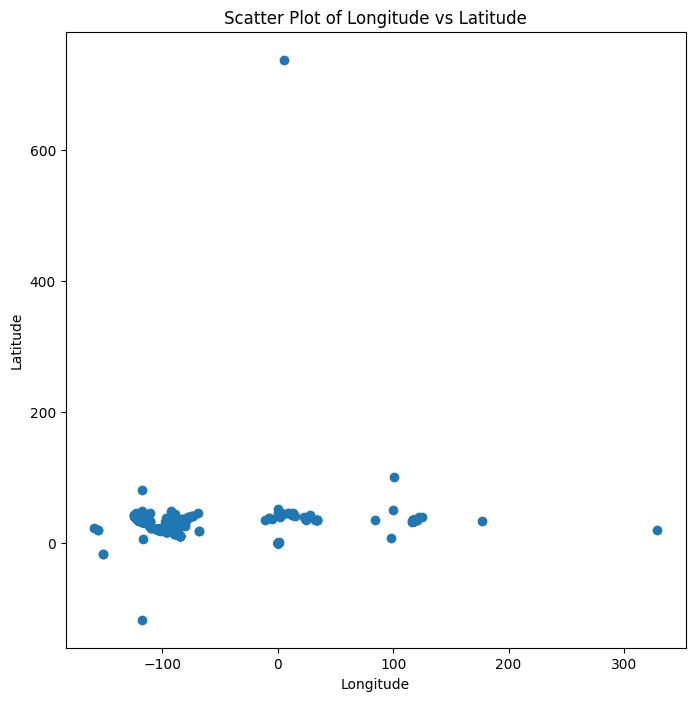

In [83]:
#check the isolated area of California
plt.figure(figsize=(8, 8))
plt.scatter(df_list['Longitude'], df_list['Latitude'])
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Scatter Plot of Longitude vs Latitude')
plt.show()

From the information about approximate location of California, latitude from $32.3\degree$ to $42.2\degree$ and longitude from $-124.7\degree$ to $-113.9 \degree$.

There are couple data points of location showing out if range from California area based on actual longitude and latitude. 

Let's identify the number of properties were out of range in geographical location of California from original dataset of **df_list**.

In [84]:
# count properties that were out of range location of California
invalid_geo= df_list[
    (
        (~df_list['Latitude'].between(32.3, 42.2))
        |(~df_list['Longitude'].between(-124.7, -113.9))
    )
]
print("Number of invalid location properties:",invalid_geo.shape[0])

Number of invalid location properties: 80833


There was orginally $80,833$ properties that were out of location from California. Now, let's filter the location for properties that are inside of Califoria region, then let's count how many properties 

In [85]:
#Drop the isloated area of California
df_list_cleaned = df_list_cleaned[
    (
        df_list_cleaned['Latitude'].between(32.3, 42.2))
        &(df_list_cleaned['Longitude'].between(-124.7, -113.9)
    )
]

print('Number of properties dropped invalid longitude & latitude :', row_df_cleaned - df_list_cleaned.shape[0])

row_df_cleaned = df_list_cleaned.shape[0]

Number of properties dropped invalid longitude & latitude : 69916


The $69,916$ properties dropped were after filtered missing and invalid properties previously. Let's check if the properties that were listed looks alike California region using scatter plot location.


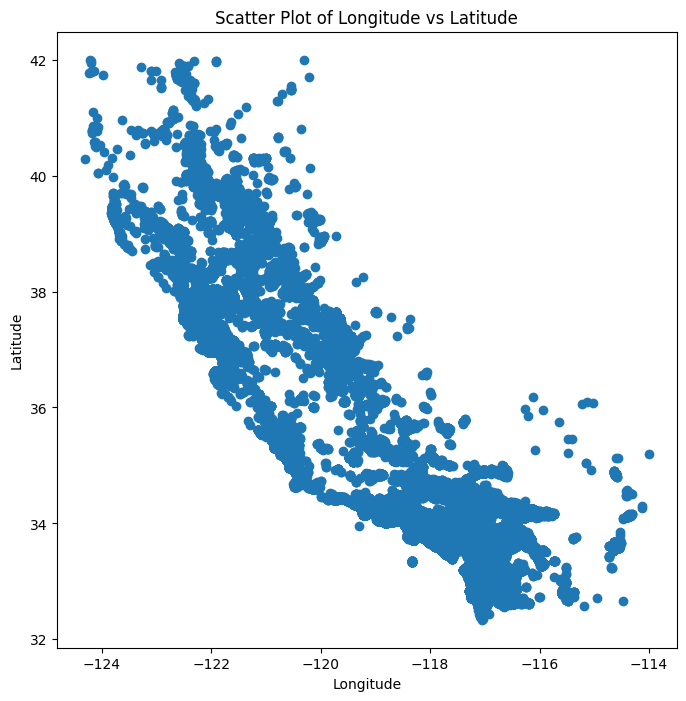

In [86]:
# Distribution longitude and latitude 
plt.figure(figsize=(8, 8))
plt.scatter(df_list_cleaned['Longitude'], df_list_cleaned['Latitude'])
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Scatter Plot of Longitude vs Latitude')
plt.show()

### b) Date

Now let's identify the date features of missing or invalid values. First, we have to check if the data types are date types for convinent later analyst.

In [87]:
# date feature data type
df_list_cleaned[date_feature].dtypes

ContractStatusChangeDate    object
ListingContractDate         object
dtype: object

The each contract date has meaning :

- Contract Status Change Date: The date the listing contract changed in the MLS system. 

- Listing Contract Date: The date of property was officially listed under the listing agreement and entered the market.

The data types are object, and we will convert into date type.

In [88]:
# convert date time data types for date features
for col in date_feature:
    df_list_cleaned[col] = pd.to_datetime(
        df_list_cleaned[col], errors="coerce"
    )

df_list_cleaned[date_feature].dtypes

ContractStatusChangeDate    datetime64[ns]
ListingContractDate         datetime64[ns]
dtype: object

Let's check if there is implicit missing values. We will construct the common missing values to suspect matched common implicit missing values. 

In [89]:
# list of implicit missing values
implicit_missing_values = [
    '',
    ' ',
    'Unknown',
    'unknown',
    'UNKNOWN',
    'N/A',
    'NA',
    'na',
    'None',
    'none',
    'NULL',
    'null',
    '--',
    '-',
    'Missing',
    'missing'
]

# scan implicit missing values match with date features
for i in date_feature:
    col = df_list_cleaned[i]
    implicit = col[col.isin(implicit_missing_values)].unique().tolist()
    print(f"{i} feature of values")
    print(implicit)
    print()

ContractStatusChangeDate feature of values
[]

ListingContractDate feature of values
[]



There is no implicit missing values. Let's check if there is explicit missing values.

In [90]:
# percentage of expllicit missing value for date features.
df_list_cleaned[date_feature].isna().sum() * 100 / df_list_cleaned.shape[0]

ContractStatusChangeDate    1.327405
ListingContractDate         0.000000
dtype: float64

The contract status change date has about 1.33% of missing.  

In [91]:
df_list_cleaned.loc[df_list_cleaned["ContractStatusChangeDate"].isna()][["MlsStatus", "PropertySubType", "YearBuilt", "DaysOnMarket"]].value_counts()

MlsStatus            PropertySubType        YearBuilt  DaysOnMarket
ActiveUnderContract  SingleFamilyResidence  1964.0     7               21
                                                       9               11
                                            1961.0     6               10
                                            1979.0     8               10
                                            1980.0     7               10
                                                                       ..
ComingSoon           SingleFamilyResidence  1989.0     1                1
                                            1986.0     4                1
ActiveUnderContract  Condominium            1983.0     30               1
ComingSoon           SingleFamilyResidence  1986.0     1                1
Pending              SingleFamilyResidence  1977.0     14               1
Name: count, Length: 3452, dtype: int64

The contract status change date can be missing following reason:

- The listing may have been imported without the historical status change timestamp

- The MLS system may not listed consistently or current status may exist even though specific date of transition was not recorded.

In [92]:
# drop missing values for date features
df_list_cleaned = df_list_cleaned.dropna(subset= date_feature)
df_list_cleaned[date_feature].isna().sum()

ContractStatusChangeDate    0
ListingContractDate         0
dtype: int64

#### 1) Invalid Contract Date

Let's check if there is invalid values in contract dates, first convert string into date time data types.


We will use listing contract date in main analysis instead of contract status change date. It is only good for studying status transitions, but for the main market story, it is harder to interpret because the date can represent different events depending on MLS status. 

Let's break it down the listed date into year and month for further analysis.

In [93]:
# split year and month
df_list_cleaned["ListYear"] = df_list_cleaned["ListingContractDate"].dt.year
df_list_cleaned["ListMonth"] = df_list_cleaned["ListingContractDate"].dt.month


df_list_cleaned["ListYearMonth"] = (
    df_list_cleaned["ListingContractDate"].dt.to_period("M")
)

Let's calculate the days from listing contract to sold date that has been listed in market. We will check if there is the date faster than May 2026.

In [94]:
# 2. Future dates
future_listing = (
    df_list_cleaned["ListingContractDate"] > pd.Timestamp("2026-06-01")
)

future_listing.sum()

np.int64(0)

There is no invalid listed contract date.

In [95]:
invalid_date = df_list_cleaned["ListingContractDate"] > df_list_cleaned["ContractStatusChangeDate"]

invalid_date.sum()

np.int64(98)

There are invalid properties that contract status date is faster timeline than listing contract date. We will drop those properties.

In [96]:
df_list_cleaned = df_list_cleaned[~invalid_date]

### c) Property Key

Now, let's check the property key features of missing values.

In [97]:
# show listing key features
df_list_cleaned[id_feature].dtypes

ListingKey            int64
ListingKeyNumeric     int64
ListingId            object
dtype: object

In [98]:
# scan implicit missing value in listing features
for i in id_feature:
    col = df_list_cleaned[i]
    implicit = col[col.isin(implicit_missing_values)].unique().tolist()
    print(f"{i} feature of values")
    print(implicit)
    print()

ListingKey feature of values
[]

ListingKeyNumeric feature of values
[]

ListingId feature of values
[]



There is no implicit missing values. Now let's check if there is explicit missing values.

In [99]:
# percentage explicit missing values
df_list[id_feature].isna().sum()/df_list.shape[0]

ListingKey           0.0
ListingKeyNumeric    0.0
ListingId            0.0
dtype: float64

There is no explicit missing values as well.

In [100]:
df_list_cleaned["ListingKey"].duplicated().sum()

np.int64(66)

In [101]:
dup_keys = df_list_cleaned[
    df_list_cleaned["ListingKey"].duplicated(keep=False)
].sort_values("ListingKey")

dup_keys

,OriginalListPrice,ListingKey,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,...,NewConstructionYN,GarageSpaces,PostalCode,RatioOriginalList,Outlier_livingarea,ListPerSqft,PropertyAge,ListYear,ListMonth,ListYearMonth
7870,409000.0,1058408504,Marie,Arredondo,33.207200,-116.299900,3135 Club Circle East,Residential,1671.0,409000.0,...,NaN,2.0,92004,1.000000,False,244.763615,35.0,2024,1,2024-01
173012,409000.0,1058408504,Marie,Arredondo,33.207200,-116.299900,3135 Club Circle East,Residential,1671.0,465000.0,...,NaN,2.0,92004,1.136919,False,278.276481,35.0,2024,8,2024-08
195268,749000.0,1061668014,Brian,Sullivan,33.152998,-117.288508,3480 Don Lorenzo Drive,Residential,2130.0,669000.0,...,NaN,0.0,92010,0.893191,False,314.084507,51.0,2024,9,2024-09
21434,749000.0,1061668014,Brian,Sullivan,33.152998,-117.288508,3480 Don Lorenzo Drive,Residential,2130.0,749000.0,...,NaN,0.0,92010,1.000000,False,351.643192,51.0,2024,2,2024-02
60929,395000.0,1072076666,Anastasia,Schmoll,33.704383,-117.185580,27256 Capilano Drive,Residential,1404.0,395000.0,...,NaN,0.0,92586,1.000000,False,281.339031,62.0,2024,4,2024-04
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
495438,2900000.0,1156512530,Nogol,Zdrilic,33.727187,-116.339523,75653 Camino De Paco,Residential,5100.0,2900000.0,...,False,4.0,92210,1.000000,True,568.627451,38.0,2026,3,2026-03
527466,1250000.0,1158406910,Jay,Rostami,33.026758,-117.085514,11417 Poblado Road,Residential,1632.0,1100000.0,...,NaN,2.0,92127,0.880000,False,674.019608,56.0,2026,4,2026-04
571162,1250000.0,1158406910,Jay,Rostami,33.026758,-117.085514,11417 Poblado Road,Residential,1632.0,1079000.0,...,NaN,2.0,92127,0.863200,False,661.151961,56.0,2026,5,2026-05
567759,445000.0,1159552222,Jorge,Mendez,32.871635,-116.971846,10388 Alphonse St Street D5,Residential,1149.0,545000.0,...,NaN,0.0,92071,1.224719,False,474.325500,43.0,2026,5,2026-05


There are 66 duplicates properties because repeated listings key may represent updated MLS reords or listings appearing. We will drop those duplicates and keep the lastest records.

In [102]:
df_list_cleaned = df_list_cleaned.drop_duplicates("ListingKey", keep="last")


In [103]:
df_list_cleaned["ListingKey"].duplicated().sum()

np.int64(0)

### d) Categorical 

Let's identify the categorical features. Since we dropped couple categorical features that had missing values over 30% we will reconstruct the categorical features gourp.

In [104]:
categorical = [
    'ListAgentFirstName',
    'ListAgentLastName',
    'UnparsedAddress',
    'PropertyType',
    'ListOfficeName',
    'ListAgentFullName',
    'MLSAreaMajor',
    'CountyOrParish',
    'MlsStatus',
    'PropertySubType',
    'City',
    'StateOrProvince',
    'Levels',
    'PostalCode',
    'AttachedGarageYN',
    'FireplaceYN',
    'NewConstructionYN'
]

# list data types for categorical
df_list[categorical].dtypes

ListAgentFirstName    object
ListAgentLastName     object
UnparsedAddress       object
PropertyType          object
ListOfficeName        object
ListAgentFullName     object
MLSAreaMajor          object
CountyOrParish        object
MlsStatus             object
PropertySubType       object
City                  object
StateOrProvince       object
Levels                object
PostalCode            object
AttachedGarageYN      object
FireplaceYN           object
NewConstructionYN     object
dtype: object

The data type shows object as categorical variables.

In [105]:
# scan implicit missing values for categorical

for i in categorical:
    col = df_list[i]
    implicit = col[col.isin(implicit_missing_values)].unique().tolist()
    print(f"{i} feature of values")
    print(implicit)
    print()

ListAgentFirstName feature of values
[]

ListAgentLastName feature of values
[]

UnparsedAddress feature of values
[]

PropertyType feature of values
[]

ListOfficeName feature of values
[]

ListAgentFullName feature of values
[]

MLSAreaMajor feature of values
[]

CountyOrParish feature of values
[]

MlsStatus feature of values
[]

PropertySubType feature of values
[]

City feature of values
['Unknown']

StateOrProvince feature of values
[]

Levels feature of values
[]

PostalCode feature of values
[]

AttachedGarageYN feature of values
[]

FireplaceYN feature of values
[]

NewConstructionYN feature of values
[]



There are couple implicit missing values in **City** with the value of 'Unknown'. 


In [106]:
# check proportion of explicit missing values
df_list[categorical].isna().sum() * 100 / df_list.shape[0]

ListAgentFirstName     0.791097
ListAgentLastName      0.007353
UnparsedAddress        0.144775
PropertyType           0.000000
ListOfficeName         0.000000
ListAgentFullName      0.017156
MLSAreaMajor          13.626688
CountyOrParish         0.000000
MlsStatus              0.000000
PropertySubType        0.228979
City                   0.102760
StateOrProvince        0.009803
Levels                10.935137
PostalCode             0.003676
AttachedGarageYN      17.464183
FireplaceYN            0.104161
NewConstructionYN      6.884593
dtype: float64

There are couple explicit missing values less than 18%. It does not highly affect on the data quality, and we will exclude those explicit missing values if there is categorical features that we will leverage for analysis.

#### 1) Property Subtypes

There are explicit missing values on property subtypes about 0.23%. We will drop those values.

In [107]:
df_list_cleaned = df_list_cleaned.dropna(subset = ["PropertySubType"])

df_list_cleaned["PropertySubType"].isna().sum()

np.int64(0)

In [108]:
df_list_cleaned["PropertySubType"].value_counts()

PropertySubType
SingleFamilyResidence    346033
Condominium               63540
Townhouse                 20467
ManufacturedOnLand         6861
Duplex                     3057
StockCooperative            948
Cabin                       815
Triplex                     652
MixedUse                    441
Quadruplex                  255
OwnYourOwn                   71
BoatSlip                     70
CoOwnership                  54
ManufacturedHome             52
Loft                         46
Farm                         33
Timeshare                    24
DeededParking                 4
MobileHome                    3
Apartment                     1
Name: count, dtype: int64

#### 2) Postal Code

There is explicit missing valeus about 0.0037% in postal code feature, and we will drop those values.

In [109]:
df_list_cleaned = df_list_cleaned.dropna(subset = ["PostalCode"])

df_list_cleaned["PostalCode"].isna().sum()

np.int64(0)

# Explanatory Data Analysis

We will explore features of housing market attributes flag invalid values and handling missing value values with filtering out those values into **df_list_cleaned**. Then, identified flagged potential outliers using business and statistical rule, and filter out into **df_list_eda**.

The final exploratory analysis used **df_list_eda**, which excludes missing values, invalid records, and observations flagged as outliers using the IQR rule. We considered the outliers of close price, living area, and lot size as numerical variables. This was done to better represent the general housing market and reduce the influence of extreme transactions, including some valid luxury-property sales.

In [110]:
all_outliers = (
    outlier_listprice
    | outlier_livingarea
    | outlier_age
    | outlier_lotsize
    | suspicious_bathroom
    | suspicious_bedroom
    | suspicious_ratio_originallist_price
    | suspicous_small_area
)

df_list_eda = df_list_cleaned.loc[~all_outliers].copy()

print("Total number of dropped outliers of properties:", df_list_cleaned.shape[0] - df_list_eda.shape[0])
print()
print("Present total number of properties after handling outliers:", df_list_eda.shape[0])

Total number of dropped outliers of properties: 84216

Present total number of properties after handling outliers: 359205


From original of total number of $571,232$ properties, we handled missing and invalid values, then filtered suspicious outliers with flagged potential outliers. Now we have $359,205$ properties left that were sold in California from 2024 to May 2026.

## 1. Multiple Listing Service (MLS) Status

In listing market data, there are five values that stand its own meaning:

- **Active**: Property is currently for sale and available to buyers

- **Active Under Contract**: Seller has accepted an contract, but the listing is still being in market, often because contingencies remain

- **Pending**: Seller has accepted an offer and transaction is moving to closing. It may treated as no longer available in market

- **Coming Soon**: Property is announced in MLS but is not yet avaliable for showing in market

- **Closed**: Transaction has completed and ownership transferred as closed for sale in market


***(In sold dataset, the MLS status only has closed)***

In [111]:
mls = df_list_eda["MlsStatus"].value_counts()
mls


MlsStatus
Active                 174303
Closed                  99125
Pending                 57909
ActiveUnderContract     26732
ComingSoon               1136
Name: count, dtype: int64

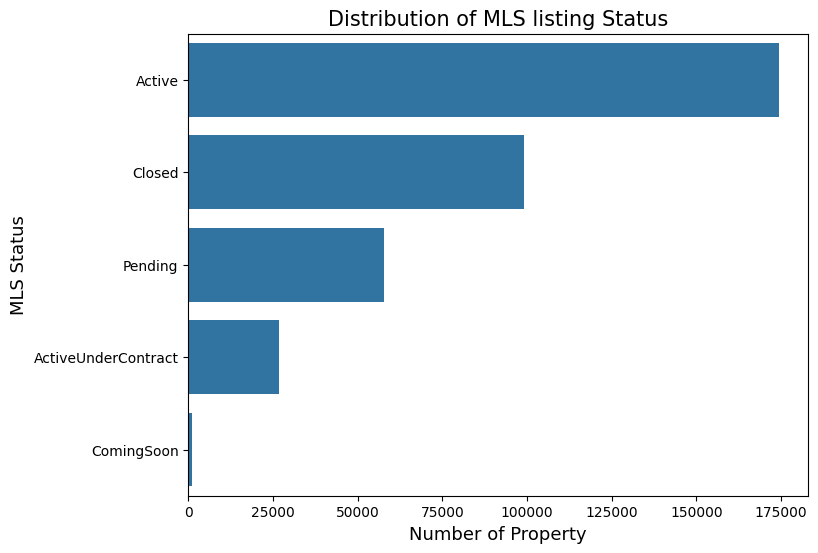

In [112]:
plt.figure(figsize= (8,6))
sns.countplot(y = df_list_eda["MlsStatus"], order = mls.index)
plt.title("Distribution of MLS listing Status", fontsize = 15)
plt.xlabel("Number of Property",fontsize = 13)
plt.ylabel("MLS Status", fontsize=13)
plt.show()


The MLS status in listing records shows:

- The **Active** listed properties are $174,303$ properties that are half of dominant in listing data.

- The **Closed** properties are listed $99,125$ that properties are closed in the market.  In the listing dataset as full listing life cycle, the closed properties are remained because it is still fundamentally a listing record that has progressed to close status.

- The **Pending** of $57,909$ properties and **Active Under Contract** of $26,928$ are both presents listing that ahve secured an accepted offer but have not yet closed. 
Above the EDA process, we went over combined MLS status listed in market to check the braod prerformance listed in the market. 


For our final report, we will use **Active** as the primary listing market becaust that represents current available inventory, while pending and active under contract is excluded from active supply. 

**Pending** and **Active Under Contract** listings have already secured an accepted offer, while **Closed** listings represent completed transactions and are analyzed separately in the sold dataset. This filtering provides a more accurate view of currently available inventory.

In [113]:
# create new dataset of active listing market
df_active = df_list_eda[
    df_list_eda["MlsStatus"] == "Active"
].copy()


In [114]:
# show number of properties of active listed and its dataset
print("Number of active properties:", df_active.shape[0])
df_active.head()

Number of active properties: 174303


,OriginalListPrice,ListingKey,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,...,NewConstructionYN,GarageSpaces,PostalCode,RatioOriginalList,Outlier_livingarea,ListPerSqft,PropertyAge,ListYear,ListMonth,ListYearMonth
1,2500000.0,1074954552,Renee,Chen,33.496363,-117.691677,16 Palisades,Residential,2788.0,2500000.0,...,False,3.0,92677,1.0,False,896.700143,32.0,2024,1,2024-01
2,3150000.0,1074936537,Margaret,Nader,34.119345,-118.111254,1615 Waverly Road,Residential,3250.0,3150000.0,...,NaN,2.0,91108,1.0,False,969.230769,61.0,2024,1,2024-01
5,665000.0,1073349180,Bryon,Thompson,32.929350,-116.945770,13281 Highway 67,Residential,1487.0,665000.0,...,False,0.0,92040,1.0,False,447.209146,22.0,2024,1,2024-01
6,1125000.0,1073322022,Timothy,Taylor,33.761176,-116.419871,39540 Kirkwood Court,Residential,1750.0,1125000.0,...,False,2.0,92270,1.0,False,642.857143,54.0,2024,1,2024-01
7,1849000.0,1073315828,Heather,Scherbert,34.206316,-118.221526,1994 Hilldale Drive,Residential,3152.0,1849000.0,...,NaN,2.0,91011,1.0,False,586.611675,77.0,2024,1,2024-01


## 2. List Price

We will explore the list price considering mainstream of the listed market in California. 

In [115]:
# summary of close price
df_active["ListPrice"].describe()

count    1.743030e+05
mean     9.573200e+05
std      6.344804e+05
min      1.500000e+04
25%      5.400000e+05
50%      7.700000e+05
75%      1.190000e+06
max      8.950000e+06
Name: ListPrice, dtype: float64

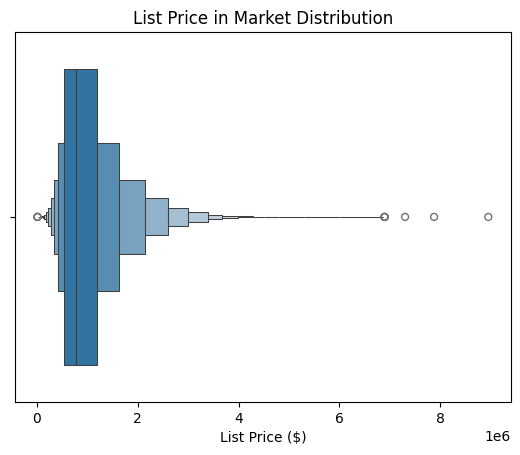

In [116]:
# boxplot for list price distribution
sns.boxenplot(x=df_active["ListPrice"])
plt.title("List Price in Market Distribution")
plt.xlabel("List Price ($)")
plt.show()

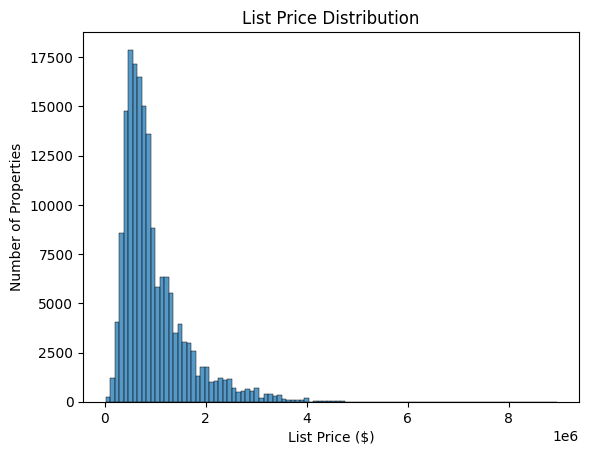

In [117]:
# historgram distribution of list price
sns.histplot(df_active["ListPrice"], bins=100)
plt.title("List Price Distribution")
plt.xlabel("List Price ($)")
plt.ylabel("Number of Properties")
plt.show()

In [118]:
# function for calculating IQR range
def function_calculation_IQR(df, numeric_col):
    q1 = df[numeric_col].quantile(0.25)
    q3 = df[numeric_col].quantile(0.75)

    IQR = q3 - q1

    print(f"0.25 qunatile: {q1}, and 0.75 quantile {q3}")
    print()
    print("IQR:", IQR)       
   

function_calculation_IQR(df_active, "ListPrice")

0.25 qunatile: 540000.0, and 0.75 quantile 1190000.0

IQR: 650000.0


- The typical housing close price as median is $\$ \, 770,000$ dollars within $\$ \, 650,000$ spread price from $\$ \, 540,000$ ~ $\$ \, 1,190,000$.

- The most expensive housing close price is $\$8,950,000$ dollars. This suggest that minor expensive properties presenting average to be pulling upward compare to typical properties. Additionally the minimum of sold price $\$15,000$.

### 3. Original List Price 

In [119]:
df_active["OriginalListPrice"].describe()


count    1.743030e+05
mean     9.647319e+05
std      6.396794e+05
min      1.500000e+04
25%      5.480000e+05
50%      7.750000e+05
75%      1.198000e+06
max      8.950000e+06
Name: OriginalListPrice, dtype: float64

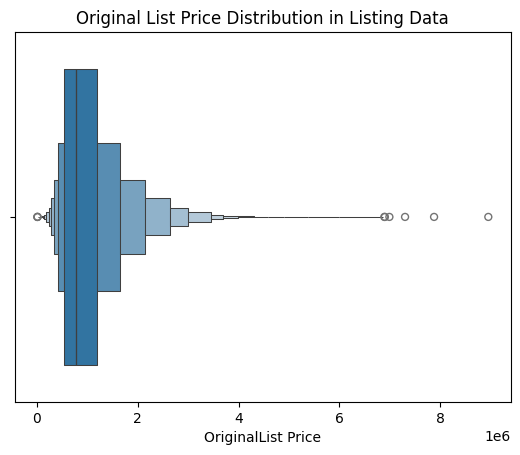

In [120]:
# boxplot for original list price distribution
sns.boxenplot(x=df_active["OriginalListPrice"])
plt.title("Original List Price Distribution in Listing Data")
plt.xlabel("OriginalList Price")
plt.show()

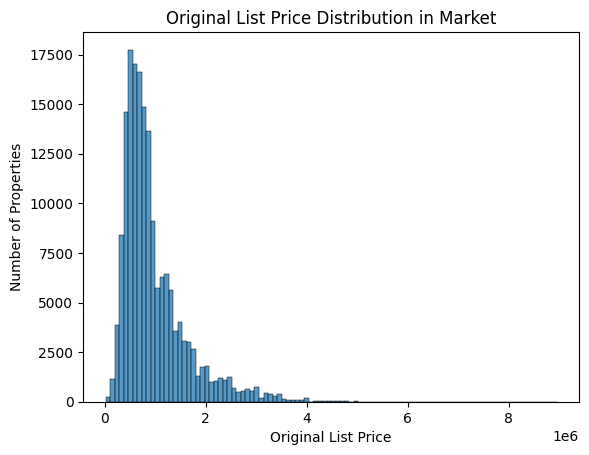

In [121]:
# histogram distribution of original list price
sns.histplot(df_active["OriginalListPrice"], bins=100)
plt.title("Original List Price Distribution in Market")
plt.xlabel("Original List Price")
plt.ylabel("Number of Properties")
plt.show()

In [122]:
function_calculation_IQR(df_active, "OriginalListPrice")

0.25 qunatile: 548000.0, and 0.75 quantile 1198000.0

IQR: 650000.0


The distribution of original list price across listed properties in California shows:

- The distribution is right skewed that mean is pulled upward due to minor expensive original listed price.

- Because of right skewed, the median measurement is more reliable than mean. The median original listed price is $\$775,000$ within $\$650,000$ spread price from $\$545,000$ to $\$1,195,000$. 

- The most expensive original listed price is $\$8,950,000$ and the cheapest original listed price is $\$15,000$. The minority of expensive properties listed were pulling mean upward producing right skewed distribution of original listed price.


## 2. Property Subtype

Now we will identify distribution of property subtype.

In [123]:
# list all proportion of values in property subtype
prob_subtype = df_active["PropertySubType"].value_counts(normalize=True)*100
prob_subtype

PropertySubType
SingleFamilyResidence    74.508184
Condominium              17.149447
Townhouse                 4.722237
ManufacturedOnLand        1.767038
Duplex                    0.823279
Cabin                     0.303494
Triplex                   0.197931
StockCooperative          0.183015
MixedUse                  0.160066
Quadruplex                0.079746
CoOwnership               0.017211
Loft                      0.017211
ManufacturedHome          0.016064
BoatSlip                  0.016064
OwnYourOwn                0.014343
Farm                      0.012048
Timeshare                 0.011474
Apartment                 0.000574
DeededParking             0.000574
Name: proportion, dtype: float64

In [124]:
subtype_count = df_active["PropertySubType"].value_counts()
subtype_count

PropertySubType
SingleFamilyResidence    129870
Condominium               29892
Townhouse                  8231
ManufacturedOnLand         3080
Duplex                     1435
Cabin                       529
Triplex                     345
StockCooperative            319
MixedUse                    279
Quadruplex                  139
CoOwnership                  30
Loft                         30
ManufacturedHome             28
BoatSlip                     28
OwnYourOwn                   25
Farm                         21
Timeshare                    20
Apartment                     1
DeededParking                 1
Name: count, dtype: int64

Most of the properties are single family residence with approximately $75\, \%$, and condominum about $17.1\,\%$, then town house with about 4.7%. 

Our purpose of analyist is general property market in California. The subtypes of rare counts such as farm, loft, triplex, or other less count properties are genuinely uncommon and it is not appropriate for comparing other subtypes drawing a general California market conclusion. 

Additionally, there are rare features of subtypes such as farm, boat slip, own your own, or deeded parking that it has unmeaningful living area or bedrooms. If we group into "Others" those are rare subtypes, it will be hard to interpret later on analysis while comparing with other subtypes. 

We will not consider for analyst out those rare subtypes that are less than 5000 properties in each subtypes in other dataset called **df_subtype_analysis**. 

When we explore the analysis overall active properties, we will use **df_active**, however, we will use **df_subtype_analysis** while we explore active properties regard to property subtype.

In [125]:
subtype_count_index = subtype_count[subtype_count >= 5000].index

subtype_count_index

Index(['SingleFamilyResidence', 'Condominium', 'Townhouse'], dtype='object', name='PropertySubType')

In [126]:
df_subtype_analysis = df_active[
    df_active["PropertySubType"].isin(subtype_count_index)
]

print(df_subtype_analysis.shape)
df_subtype_analysis.head()

(167993, 42)


,OriginalListPrice,ListingKey,ListAgentFirstName,ListAgentLastName,Latitude,Longitude,UnparsedAddress,PropertyType,LivingArea,ListPrice,...,NewConstructionYN,GarageSpaces,PostalCode,RatioOriginalList,Outlier_livingarea,ListPerSqft,PropertyAge,ListYear,ListMonth,ListYearMonth
1,2500000.0,1074954552,Renee,Chen,33.496363,-117.691677,16 Palisades,Residential,2788.0,2500000.0,...,False,3.0,92677,1.0,False,896.700143,32.0,2024,1,2024-01
2,3150000.0,1074936537,Margaret,Nader,34.119345,-118.111254,1615 Waverly Road,Residential,3250.0,3150000.0,...,NaN,2.0,91108,1.0,False,969.230769,61.0,2024,1,2024-01
6,1125000.0,1073322022,Timothy,Taylor,33.761176,-116.419871,39540 Kirkwood Court,Residential,1750.0,1125000.0,...,False,2.0,92270,1.0,False,642.857143,54.0,2024,1,2024-01
7,1849000.0,1073315828,Heather,Scherbert,34.206316,-118.221526,1994 Hilldale Drive,Residential,3152.0,1849000.0,...,NaN,2.0,91011,1.0,False,586.611675,77.0,2024,1,2024-01
11,950000.0,1073268210,Allison,Seiler,33.125319,-117.219430,1215 Westport Road,Residential,1871.0,950000.0,...,NaN,2.0,92078,1.0,False,507.749866,37.0,2024,1,2024-01


In [127]:
# summary of common property subtype
count_subtype_common = df_subtype_analysis["PropertySubType"].value_counts()

count_subtype_common

PropertySubType
SingleFamilyResidence    129870
Condominium               29892
Townhouse                  8231
Name: count, dtype: int64

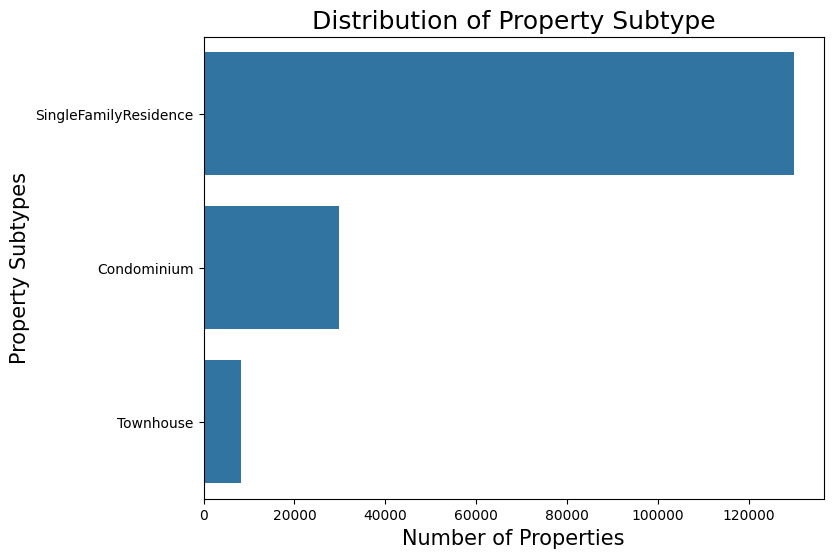

In [128]:
# boxplot distribution for common propety subtypes
plt.figure(figsize=(8,6))
sns.barplot(y=count_subtype_common.index, x = count_subtype_common)
plt.title("Distribution of Property Subtype", fontsize = 18)
plt.ylabel("Property Subtypes", fontsize = 15)
plt.xlabel("Number of Properties", fontsize = 15)
plt.show()

- The distribution of property subtypes is highly uneven. 

- Single family residences make up approximately three-quarters of the sold records, followed by condominiums and townhouses. 

- This imbalance means that overall price and market summaries will largely reflect the behavior of single-family homes rather than the entire residential market.

### 1) Property Subtype & List Price

We will identify the relationship between property subtypes and list price using median due to right skewed list price, sorting based on median price descending order.  

Let's make a function for summary grouped categorical variables measuring median numerical variable with IQR rule. 

In [129]:
# function for grouped categorical by measuring median numerical variable.
def function_grouped_summary(df, group_col, value_col):
    df_summary = (df.groupby(group_col)[value_col]
                      .agg(
                          count = "count",
                          min = "min",
                          q1 = lambda x : x.quantile(0.25),
                          median = "median",
                          q3 = lambda x : x.quantile(0.75),
                          IQR = lambda x : x.quantile(0.75) - x.quantile(0.25),
                          max = "max"

                      )
                      .sort_values("median", ascending=False))
    return df_summary

Here is the summary of relationship between property subtype and close price.

In [130]:
subtype_closeprice = function_grouped_summary(df_subtype_analysis, "PropertySubType", "ListPrice")
subtype_closeprice

,count,min,q1,median,q3,IQR,max
PropertySubType,,,,,,,
SingleFamilyResidence,129870,25000.0,578000.0,835000.0,1299000.0,721000.0,5298000.0
Townhouse,8231,160000.0,629999.0,778000.0,998800.0,368801.0,2375000.0
Condominium,29892,34500.0,469900.0,615000.0,808000.0,338100.0,2101096.0


C:\Users\junki\AppData\Local\Temp\ipykernel_44168\1712466582.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels)


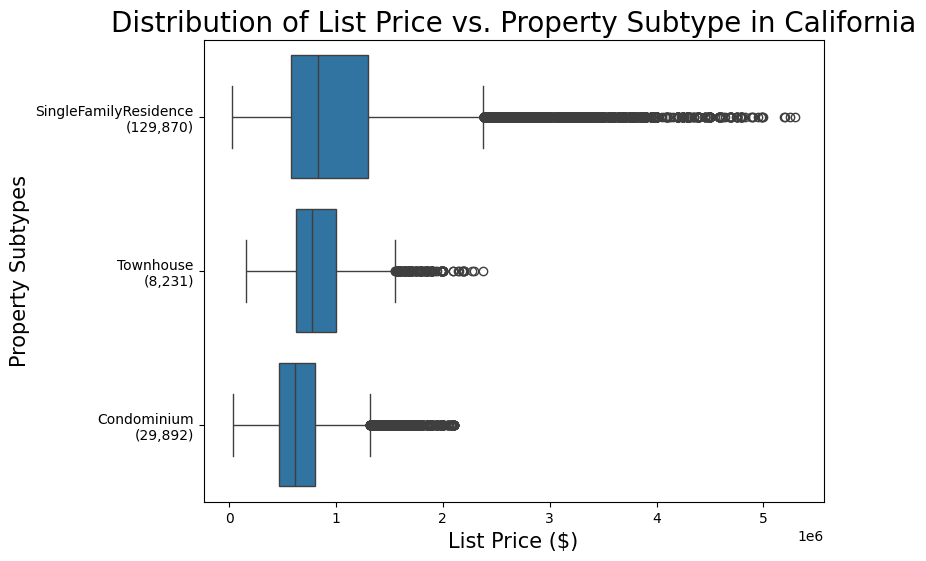

In [131]:
# boxplot distribution for close price vs. property subtypes
plt.figure(figsize=(8, 6))
ax =sns.boxplot(x="ListPrice", y="PropertySubType", data=df_subtype_analysis, order = subtype_closeprice.index)

# create labels with counts
labels = [
    f"{subtype}\n({count_subtype_common[subtype]:,})"
    for subtype in subtype_closeprice.index
]

ax.set_yticklabels(labels)

plt.title("Distribution of List Price vs. Property Subtype in California", fontsize = 20)
plt.ylabel("Property Subtypes", fontsize=15)
plt.xlabel("List Price ($)", fontsize= 15)
plt.show()

- The highest median of listed price was **Single Family Residence** active $129,870$ properties that shows median listed price $\$835,000$ within $\$721,000$ spread price from $\$578,000$ to $\$1,299,000$, 

- Then follow the active $8,290$ porperties of **Townhouse** shows median listed price $\$778,000$ within $\$368,801$ spread price from $\$629,999$ to $\$998,800$. 

- The distribution all right skewed due to minor expensive properties in each subtype that pulling mean upward.

- The more listed properties are in that subtypes, the more IQR range wide listed price in the mmarket.


- Among the largest amount of properties, **Single Family Residence** has a particularly large number of upper outliers. This does not necessarily mean the values are invalid. It likely reflects the wide diversity of single-family homes across California, including luxury properties and expensive coastal markets. **Townhouse** and **Condominium** have lower median prices and narrower central distributions than single-family residences. However, they still contain many high-price observations.

- The association between property subtypes and list price seems weak association due to overlap IQR range across major subtypes. 


Let's check statistical test of Kruskal Wallis test due to highely overlap across major property subtypes.

In [132]:
groups = [
    group["ListPrice"].dropna()
    for name, group in df_subtype_analysis.groupby("PropertySubType")
]

h, p = kruskal(*groups)

print("H statistic:", h)
print("p-value:", p)

H statistic: 8823.144623437096
p-value: 0.0


Our null hypothesis is "The list price distributions are the same across all major properties subtyeps", and alternative hypothesis is "At least one property subtype has a different list price distribution".

- The p-value of 0.0 is smaller then 0.05 significance level, we reject null hypothesis. 

- There are signficant evidence to suggest close price distributions across propery subtypes at least o- ne has different typical close price from the others. 

- **This indicates that close price has statistical association with property subtype due to statistical test. However, there is substantial overlap in the distribution that major subtype is not stong alone determinant of listing price in active market.**


## 3. Living Area

Let's explore living area of properties that were sold in California from 2024 to May 2026.

In [133]:
# summary of living area distribution
df_active["LivingArea"].describe()

count    174303.000000
mean       1769.470952
std         719.349426
min         100.000000
25%        1240.000000
50%        1640.000000
75%        2177.000000
max        6038.000000
Name: LivingArea, dtype: float64

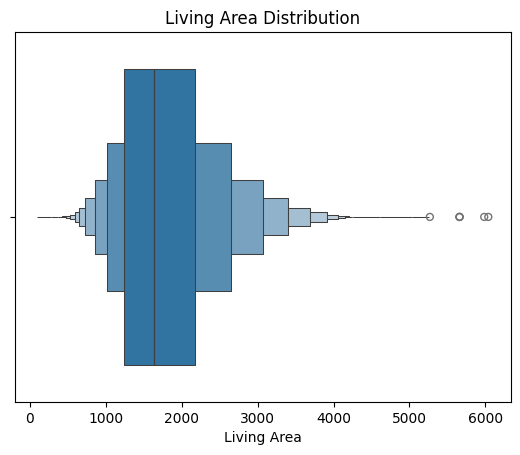

In [134]:
sns.boxenplot(x=df_active["LivingArea"])
plt.title("Living Area Distribution")
plt.xlabel("Living Area")
plt.show()

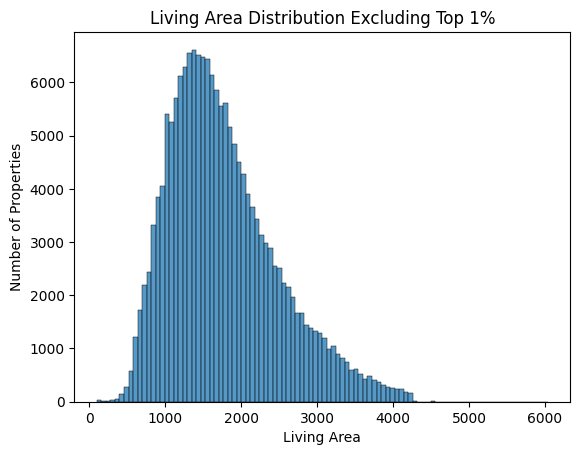

In [135]:
# histrogram distribution for living area
sns.histplot(df_active["LivingArea"], bins=100)
plt.title("Living Area Distribution Excluding Top 1%")
plt.xlabel("Living Area")
plt.ylabel("Number of Properties")
plt.show()

In [136]:
# measure IQR range of living area
function_calculation_IQR(df_active, "LivingArea")

0.25 qunatile: 1240.0, and 0.75 quantile 2177.0

IQR: 937.0



- The living area of median size is about $1,640 \, sqft$ across California sold houses within $937 sqft$ from $1,240 sqft$ to $2,177 sqft$. 

- The maximum size is $6,038 sqft$ and the minimum $100 \, sqft$ which is rare structured properties such as boat slip. 

- The distribution would be right skewed that mean value was pulling upward due to minor extreme outliers. 

### 2) Living Area vs. List Price

Let's check the relationship between living area and close price.

<Figure size 2000x2000 with 0 Axes>

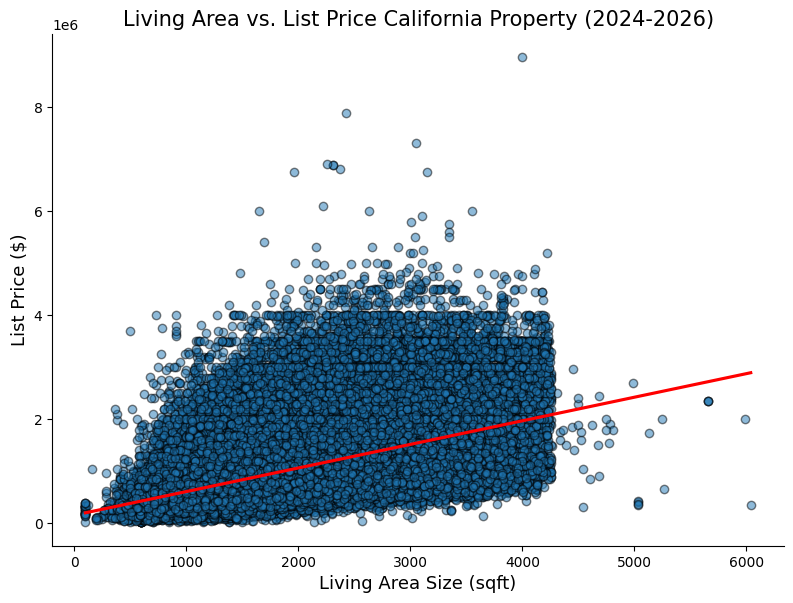

In [137]:
plt.figure(figsize = (20, 20))
sns.lmplot(
    x = "LivingArea",
    y="ListPrice",
    data = df_active,

    height = 6,
    aspect = 8/6,
    scatter_kws ={
        "alpha" : 0.5,
        "edgecolor" : "black"
    },

    line_kws = {
        "color" : "red"
    },

    ci = None
)

plt.xlabel("Living Area Size (sqft)", fontsize = 13)
plt.ylabel("List Price ($)", fontsize = 13)
plt.title("Living Area vs. List Price California Property (2024-2026)", fontsize = 15)
plt.show()

The scatter plot indicates :

- There is a positive association between living area and list price, with larger properties generally listed higher price. 


- The wide variation in price at similar living area levels, it suggests that living area alone does not fully explain sale price.

In [138]:
# statistically check correlation between price and living area
rho, p = spearmanr(df_active["ListPrice"], df_active["LivingArea"])
print(f"statistics rho test is {rho}")
print(f"p-value is {p}")

statistics rho test is 0.511904594399113
p-value is 0.0


- The statistics shows positive correlation about 0.51 as mild meaningful.

- Larger properties usually sell for more, but properties with similar living areas can still have very different prices because of location, county, subtype, condition, amenities, and other factors.

- The null hypothesis "There is no monotonic association between living area and list price.", and alternative hypothesis "There is a monotonic association between living area and list price.". Since the p-value of 0.0 is lower than 0.05, we reject null hypothesis.

- There is significant evidence to suggest that there is monotinic association between living area and list price.

### 3) List Price per Living Area

Price per square foot provides buyers understand how much they are paying for actual living space of a active property in listing market. It makes it easier to compare other properties of different sized and check whether one area or property type is relatively more expensive than another.

In [139]:
# summary distribution
df_active["ListPerSqft"].describe()

count    174303.000000
mean        558.311615
std         302.964195
min          10.845987
25%         334.177486
50%         501.626898
75%         702.819532
max        7400.000000
Name: ListPerSqft, dtype: float64

Text(0.5, 0, 'List Price per Living Area ($ / sqft)')

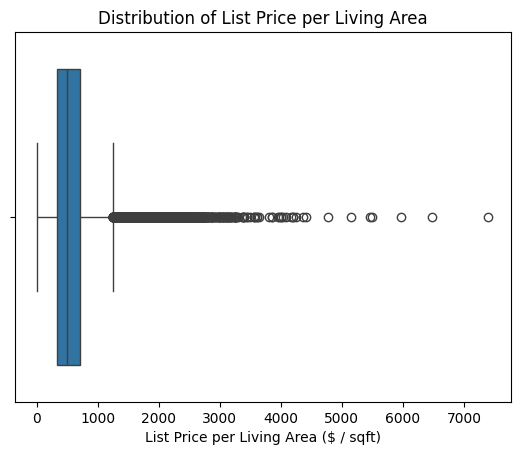

In [140]:
sns.boxplot(x = df_active["ListPerSqft"])
plt.title("Distribution of List Price per Living Area")
plt.xlabel("List Price per Living Area ($ / sqft)")

In [141]:
function_calculation_IQR(df_active, "ListPerSqft")

0.25 qunatile: 334.17748647056874, and 0.75 quantile 702.819531949373

IQR: 368.6420454788042


The distribution summary of ratio in sold properties in California:

- **The median ratio list price per 1 sqft is  about $502 \, \$/sqft$ within about $369 \, \$ \, /\, sqft$ spread ratio from $334 \, \$ \, / \, sqft$ ~ $703 \, \$ \, / \, sqft$** .

- The maximum ratio is $7,400 \, \$ \, / \, sqft$ and the minimum ratio is about $11 \, \$ \, / \, sqft$.

- **The distribution is right skewed** that mean ratio pulled upward due to expensive sold price per 1 sqft.


### 4) Ratio (Close Price/Living Area) vs. Property SubType

We will explore the relationship between ratio of list price per living area and property subtype. 

First, let's briefly check the typeical living area size and list price by property subtypes that has over 500 properties sold.

In [142]:
# summary of median of living area by property subtype
function_grouped_summary(df_subtype_analysis, "PropertySubType", "LivingArea")

,count,min,q1,median,q3,IQR,max
PropertySubType,,,,,,,
SingleFamilyResidence,129870,162.0,1393.0,1820.0,2372.0,979.0,4259.0
Townhouse,8231,576.0,1240.0,1458.0,1703.0,463.0,2479.0
Condominium,29892,266.0,899.0,1143.0,1447.0,548.0,2408.0


In major active market, the Single Family Residence has the highest typical living area, then Townhouse and Condominium.

Additionally, here is the previous chart of distribution list price by property subtype. 

In [143]:
# summary of median of close price by property subtype
function_grouped_summary(df_subtype_analysis, "PropertySubType", "ListPrice")

,count,min,q1,median,q3,IQR,max
PropertySubType,,,,,,,
SingleFamilyResidence,129870,25000.0,578000.0,835000.0,1299000.0,721000.0,5298000.0
Townhouse,8231,160000.0,629999.0,778000.0,998800.0,368801.0,2375000.0
Condominium,29892,34500.0,469900.0,615000.0,808000.0,338100.0,2101096.0


The order from highest median listed price is same as living area above. The Single Family Residence was the highest median listed price. 

Let's check the ratio distirbution by property subtypes.

In [144]:
# make new feature 
df_subtype_analysis["ListPerSqft"] = df_subtype_analysis["ListPrice"] / df_subtype_analysis["LivingArea"]

C:\Users\junki\AppData\Local\Temp\ipykernel_44168\4080005479.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_subtype_analysis["ListPerSqft"] = df_subtype_analysis["ListPrice"] / df_subtype_analysis["LivingArea"]


In [145]:
# summary of median chart of ratio by property subtype
group_ratio_propertysubtype = function_grouped_summary(df_subtype_analysis, "PropertySubType", "ListPerSqft")

group_ratio_propertysubtype

,count,min,q1,median,q3,IQR,max
PropertySubType,,,,,,,
Condominium,29892,55.200000,433.365585,560.155402,699.156546,265.790961,2864.583333
Townhouse,8231,124.309392,447.794118,543.103448,678.056058,230.261940,1771.390374
SingleFamilyResidence,129870,11.660448,316.108426,485.002343,714.797457,398.689031,7400.000000


C:\Users\junki\AppData\Local\Temp\ipykernel_44168\624772550.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels)


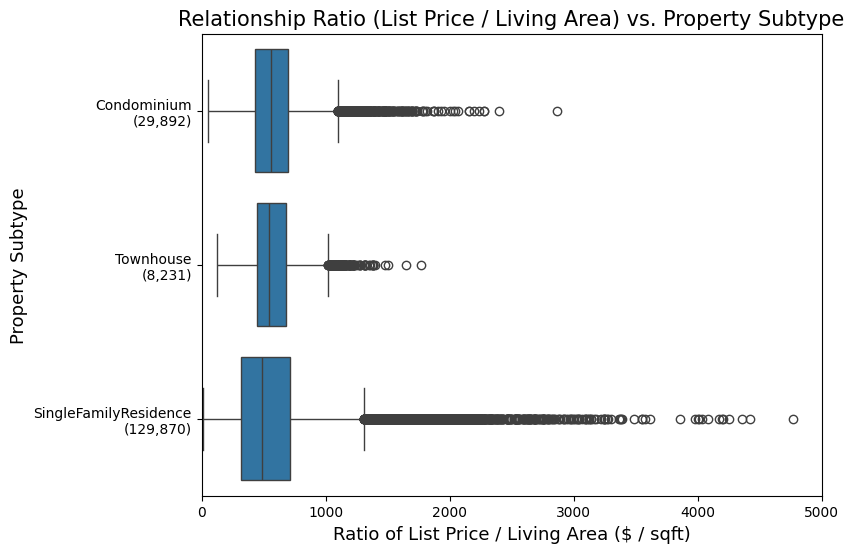

In [146]:
# boxplot distribution for county vs. close price
plt.figure(figsize=(8,6))
ax = sns.boxplot(x="ListPerSqft", y="PropertySubType", data=df_subtype_analysis, order = group_ratio_propertysubtype.index)

labels = [
    f"{subtype}\n({count_subtype_common[subtype]:,})"
    for subtype in group_ratio_propertysubtype.index
]

ax.set_yticklabels(labels)

plt.title("Relationship Ratio (List Price / Living Area) vs. Property Subtype", fontsize = 15)
plt.xlabel("Ratio of List Price / Living Area ($ / sqft)", fontsize=13)
plt.xlim(0, 5000)
plt.ylabel("Property Subtype", fontsize= 13)
plt.show()

- The highest typical ratio of sold price per 1 sqft is **Condominium** approximately $560  \, \$ \, / \, sqft$ within about $266 \, \$ \, / \, sqft$ from $433 \, \$ \, / \, sqft$ ~ $699 \, \$ \, / \, sqft$. 

- The lowest median ratio was **Single Family Residence** approximately $485 \, \$ \, / \, sqft$ within about $399 \, \$ \, / \, sqft$ from $316 \, \$ \, / \, sqft$ ~ $715 \, \$ \, / \, sqft$/.

- All of counties are right skewed in ratio distribution due to minor high ratio that pulling mean upward comparing to median.

- Although Single Family Residence show higher median total list prices and living area size, Town House and Condominiums present the highest median list price per sqft. **This suggests that smaller attached housing types may listed  relatively high prices for amount of living space they provide.**

- The large IQR follows on more listed of active properties, and it may suggest that ratio may reflect  substantial differences in location, property quality, or other features.

- This indicates that total property list price and price relative to living space do not necessarily follow the same pattern across property subtypes.

- Town House, Condominium, and Single Family Residence are clustered in a similar general IQR range. It may seems weak association between property subtype and list price per living area. 


Let's check statistical test of Kruskal Wallis.





In [147]:
groups = [
    group["ListPerSqft"].dropna()
    for name, group in df_subtype_analysis.groupby("PropertySubType")
]

h, p = kruskal(*groups)

print("H statistic:", h)
print("p-value:", p)

H statistic: 2140.9197876724766
p-value: 0.0


Our null hypothesis is "The list price distributions are the same across all major properties subtyeps", and alternative hypothesis is "At least one property subtype has a different list price distribution".

- The p-value of 0.0 is smaller then 0.05 significance level, we reject null hypothesis. 

- There are signficant evidence to suggest the ratio distributions across propery subtypes at least one has different from the others. 

- **This indicates that list price per living area has statistical association with property subtype due to statistical test. However, there is substantial overlap in the distribution that major subtype is not stong alone determinant of listing price in active market.**

## 4. Lot Size

Let's explore the lot size that were listed market in California.

In [148]:
# show IQR range and summary distribution of lot size
function_calculation_IQR(df_active, "LotSizeAcres")
print()
print("Summary distribution of lot size")

df_active["LotSizeAcres"].describe()

0.25 qunatile: 0.1138, and 0.75 quantile 0.2315

IQR: 0.11770000000000001

Summary distribution of lot size


count    174303.000000
mean          0.395277
std           1.410614
min           0.000000
25%           0.113800
50%           0.160000
75%           0.231500
max         159.930000
Name: LotSizeAcres, dtype: float64

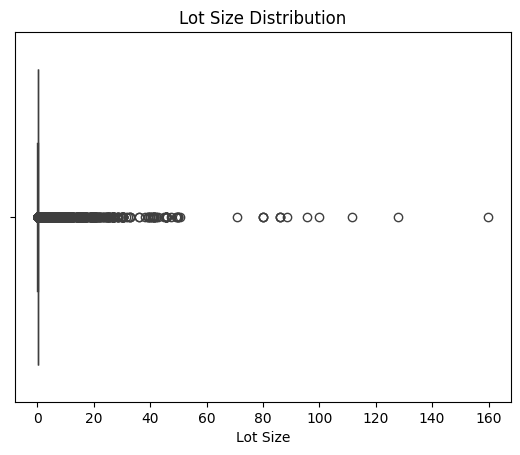

In [149]:
sns.boxplot(x=df_list_eda["LotSizeAcres"])
plt.title("Lot Size Distribution")
plt.xlabel("Lot Size")
plt.show()

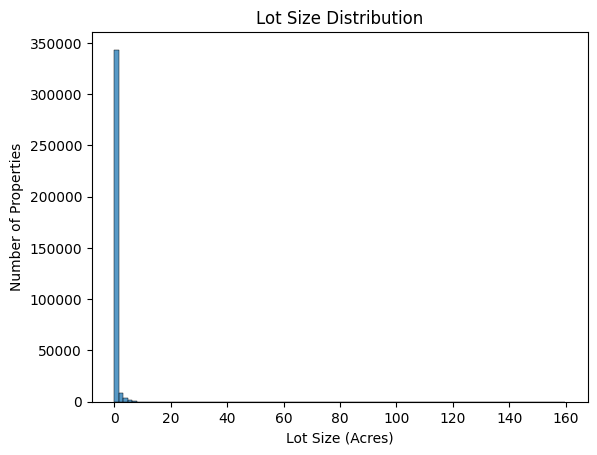

In [150]:
sns.histplot(x=df_list_eda["LotSizeAcres"], bins=100)
plt.title("Lot Size Distribution")
plt.xlabel("Lot Size (Acres)")
plt.ylabel("Number of Properties")
plt.show()

The overall lot size distribution of active properties listed in market California shows:

- The distribution is highly right skewed that minor properties with high lot sizes pulling the mean upward compared to median.

- The median lot size was about $0.16 \, acres$ listed within about $0.12 \, acres$ spread size from $0.11 \, acres$ ~ $0.23 \, acres$.

- The maximum of lot size was $159.93\, acres$ listed in market, and the minimum size was $0 \,  acres$.



### 1) Lot Size vs. List Price

<Figure size 2000x2000 with 0 Axes>

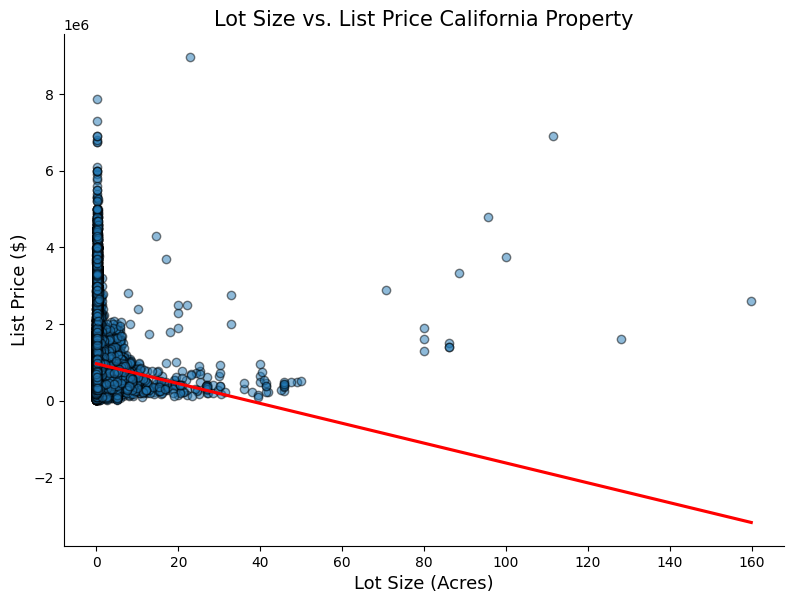

In [151]:
plt.figure(figsize = (20, 20))
sns.lmplot(
    x = "LotSizeAcres",
    y="ListPrice",
    data = df_active,

    height = 6,
    aspect = 8/6,
    scatter_kws ={
        "alpha" : 0.5,
        "edgecolor" : "black"
    },

    line_kws = {
        "color" : "red"
    },

    ci = None
)

plt.xlabel("Lot Size (Acres)", fontsize = 13)
plt.ylabel("List Price ($)", fontsize = 13)
plt.title("Lot Size vs. List Price California Property", fontsize = 15)
plt.show()

The scatter plot shows that :

- The Observations are concentrated at relatively small lot sizes, while a fiew very large size properties created extreme points.

- The red regression line is misleading because the distribution is highly skewed and those extreme lot size observations can strongly affect linear trend.


In [152]:
# statistically check correlation between price and living area
rho, p = spearmanr(df_active["ListPrice"], df_active["LotSizeAcres"])
print(f"statistics rho test is {rho}")
print(f"p-value is {p}")

statistics rho test is 0.005501953426158851
p-value is 0.021616199865965198


- The rho value about 0.0055 shows that lot size and list price have virtually no monotonic association in this dataset.

- Even the p-value is below 0.02 statistical level showing as statistically significant, a tiny effect can become statistically significant in large dataset. So we should not interpret this as important relationship.

## 5. Bedrooms

Let's explore bedroom distribution across listed properties in California.

In [153]:
prob_bed = df_active["BedroomsTotal"].value_counts(normalize=True).sort_values(ascending=False)*100

prob_bed

BedroomsTotal
3.0     38.202441
4.0     25.741955
2.0     22.208453
5.0      7.711284
1.0      4.380877
6.0      1.286840
7.0      0.277677
8.0      0.104990
9.0      0.041881
0.0      0.016064
10.0     0.014343
11.0     0.004590
12.0     0.003442
13.0     0.002869
14.0     0.001721
16.0     0.000574
Name: proportion, dtype: float64

In [154]:
count_bed = df_active["BedroomsTotal"].value_counts().sort_values(ascending=False)

count_bed


BedroomsTotal
3.0     66588
4.0     44869
2.0     38710
5.0     13441
1.0      7636
6.0      2243
7.0       484
8.0       183
9.0        73
0.0        28
10.0       25
11.0        8
12.0        6
13.0        5
14.0        3
16.0        1
Name: count, dtype: int64

There are $29$ properties that contain no bedrooms. This minor properties would interfere the analysis exploring the relationship with other features later on, as data sparse. We will exclude those properties.

There is still sparse categories of total number of bedrooms that have more than 4 beds. I will group into "5+" from more than equal to 5 beds.

In [155]:
# exclude bathrooms 0 properties
df_active = df_active[df_active["BedroomsTotal"] > 0]

# extract beds more than 6 using probability
df_active["BedroomGrouped"] = np.where(
    df_active["BedroomsTotal"] >=5,

    "5+",
    df_active["BedroomsTotal"].astype("Int64").astype(str)
)

# show the distribution of number of beds
df_active["BedroomGrouped"].value_counts()


BedroomGrouped
3     66588
4     44869
2     38710
5+    16472
1      7636
Name: count, dtype: int64

The total number of bedrooms of more than equal to 5 is $16,472$ properties. Instead of having sparse number of bedrooms, we grouped into more than or equal to 5 beds, which safe comparison and interpret with other number of bedrooms.

In [156]:
# measure summary of distribution and its IQR range
function_calculation_IQR(df_active, "BedroomsTotal")
print()
print("Summary of distribution")
df_active["BedroomsTotal"].describe()

0.25 qunatile: 2.0, and 0.75 quantile 4.0

IQR: 2.0

Summary of distribution


count    174275.000000
mean          3.161676
std           1.075868
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          16.000000
Name: BedroomsTotal, dtype: float64

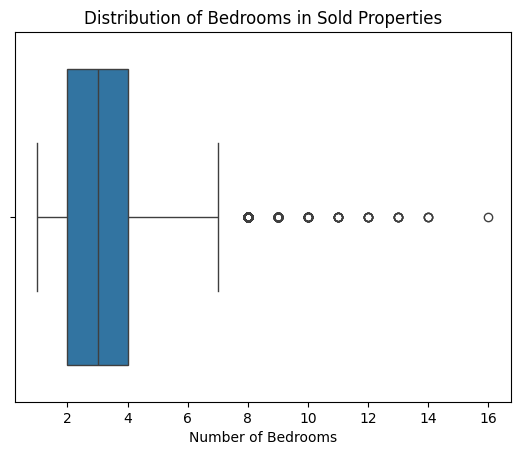

In [157]:
# show distribution boxplot of bedrooms overall
sns.boxplot(x = df_active["BedroomsTotal"])
plt.xlabel("Number of Bedrooms")
plt.title("Distribution of Bedrooms in Sold Properties")
plt.show()

The bedrooms distribuion across sold properties in California shows:

- The median number of bedrooms is $3$ beds within $2$ beds from $2$ to $4$ beds. 

- The maximum is $16$ beds such as luxury or rare properties  and minimum is $1$ beds.

- The distribution is right skewed that minor of properties that has many beds pulling mean upward, and median is reliable measurement in this stage.


We have made the new feature **BedroomsGrouped** in previous step from handling outlier bedrooms. Let's check the discrete feature of distribution specifically.

In [158]:
# show the list of propoortions in each number of bedrooms
prob_bed = df_active["BedroomGrouped"].value_counts().sort_values(ascending=False)

prob_bed

BedroomGrouped
3     66588
4     44869
2     38710
5+    16472
1      7636
Name: count, dtype: int64

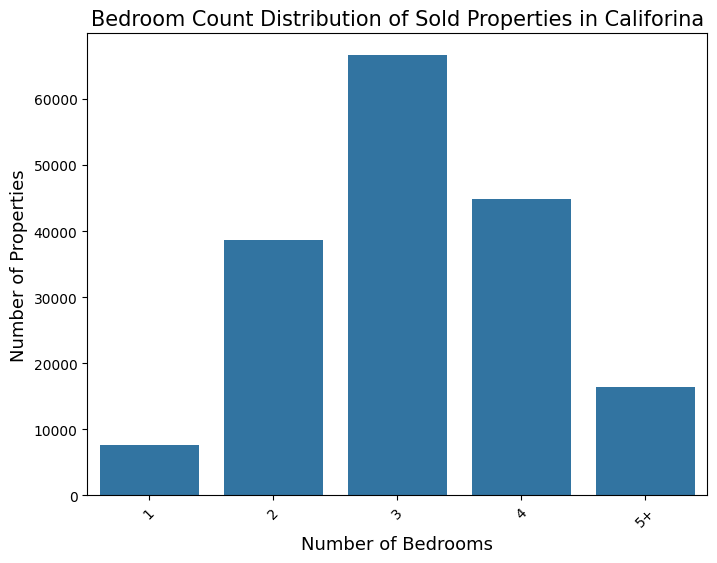

In [159]:
plt.figure(figsize=(8,6))
sns.countplot(x="BedroomGrouped", data = df_active, order=["1", "2", "3", "4", "5+"])
plt.xticks(rotation=45)
plt.title("Bedroom Count Distribution of Sold Properties in Califorina", fontsize = 15)
plt.xlabel('Number of Bedrooms', fontsize = 13)
plt.ylabel("Number of Properties", fontsize= 13)
plt.show()

**Most of the properties that were active listed have 3 with around $66,588$ properties or 4 bedrooms with $44,869$ properties.** There are minor properties that has over and equal to 5 bedrooms which shows luxury or unusual properties that produce right skewed distribution.

#### 2) Bedrooms vs. List Price

Let's explore the relationship with other features starting with list price.

In [160]:
# summary of median distribution of close price by bedrooms
group_bed_price = function_grouped_summary(df_active, "BedroomGrouped", "ListPrice")

group_bed_price

,count,min,q1,median,q3,IQR,max
BedroomGrouped,,,,,,,
5+,16472,55000.0,788000.0,1169900.0,1799912.5,1011912.5,8950000.0
4,44869,33600.0,665000.0,949000.0,1495000.0,830000.0,6890000.0
3,66588,28888.0,545683.0,765000.0,1100000.0,554317.0,5750000.0
2,38710,15000.0,430000.0,599000.0,819000.0,389000.0,4900000.0
1,7636,17995.0,349000.0,469000.0,624922.5,275922.5,3999888.0


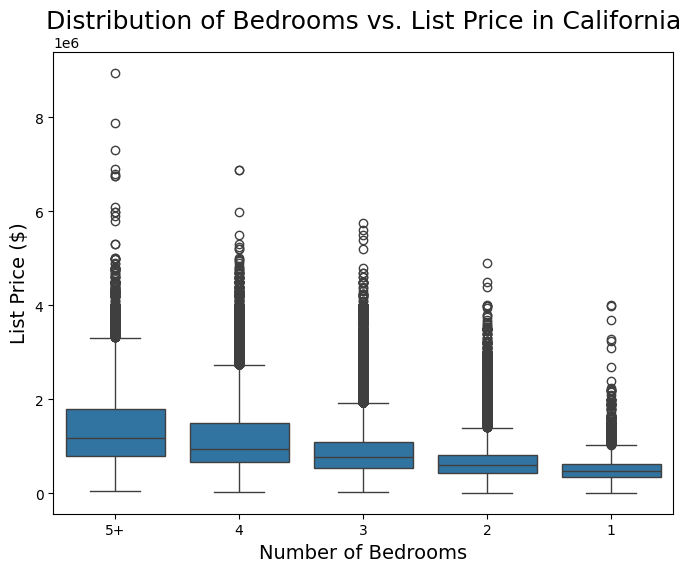

In [161]:
# boxplot distribution for bedrooms vs. close price
plt.figure(figsize=(8, 6))
sns.boxplot(x="BedroomGrouped", y="ListPrice", data=df_active, order = group_bed_price.index)
plt.title("Distribution of Bedrooms vs. List Price in California", fontsize = 18)
plt.xlabel("Number of Bedrooms", fontsize=14)
plt.ylabel("List Price ($)", fontsize= 14)
plt.show()

The distribution of listed price grouping by number of bedrooms shows:

- **The list price tends to be clear upward pattern with bedrooms count that the price tend to increase for larger bedroom properties.**

- The highest of median price is about $\$  1,169,900$ at more than and equal to 5 beds within $ \$ 1,011,912.5$ from $\$ 788,800$ ~ $\$ 1,799,912.5$. 

- The smallest median price is about $\$  469,000$ at 1 beds within $\$275,922.5$ from $\$349,000$ to $\$ 624,922.5$.

- The active listed price spread becomes wider for larger beds.

- All the bedroom groups contain many high price outliers that those high price observations could reflect differences in location, living area, or other property characteristics. Additionlly, all the distributions are right skewed due to high outliers.

- There at least one difference of IQR range such as 1 bedroom and more than and equal to 5 bedrooms, **indicating there might be association between closing price and number of bedrooms.** 

## 6. Bathrooms

Let's identify the distribution of bathrooms.

In [162]:
# show the distribution of bathrooms in percentage
prob_bath = df_active["BathroomsTotalInteger"].value_counts(normalize=True).sort_values(ascending=False)*100

prob_bath


BathroomsTotalInteger
2.0     43.613829
3.0     34.352604
1.0     11.438818
4.0      7.869746
5.0      2.143165
6.0      0.425764
7.0      0.089514
8.0      0.030986
0.0      0.021231
9.0      0.009755
10.0     0.004017
11.0     0.000574
Name: proportion, dtype: float64

In [163]:
count_bath = df_active["BathroomsTotalInteger"].value_counts().sort_values(ascending=False)

count_bath


BathroomsTotalInteger
2.0     76008
3.0     59868
1.0     19935
4.0     13715
5.0      3735
6.0       742
7.0       156
8.0        54
0.0        37
9.0        17
10.0        7
11.0        1
Name: count, dtype: int64

There are still sparse of properties that has less than 100 properties counts. The number of bathrooms of 5 has meaningful amount of properties, so we will group the counts from 5 and name it *"5+"*.

Additionally, we will exclude 0 bathroom of $84$ properties for the clear analysis with other features relationship.

In [164]:
# exclude the 0 bathrooms
df_active = df_active[df_active["BathroomsTotalInteger"]>0]

# point the rows where more than 6 bathrooms, uniform the name into 6+
df_active["BathroomGrouped"] = np.where(
    df_active["BathroomsTotalInteger"] >= 5,
    "5+",
    df_active["BathroomsTotalInteger"].astype("Int64").astype(str)
)

# show bathroom distribution
df_active["BathroomGrouped"].value_counts()


BathroomGrouped
2     76008
3     59868
1     19935
4     13715
5+     4712
Name: count, dtype: int64

In [165]:
# show bathroom distribution
df_active["BathroomGrouped"].value_counts(normalize = True) * 100

BathroomGrouped
2     43.623090
3     34.359899
1     11.441247
4      7.871417
5+     2.704347
Name: proportion, dtype: float64

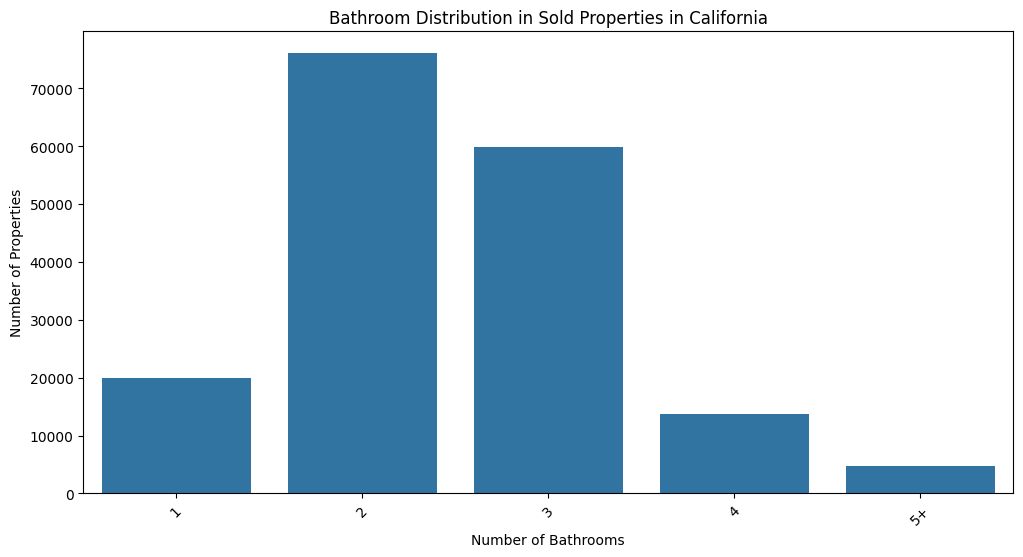

In [166]:
# bar chart distribution of bathrooms
plt.figure(figsize=(12, 6))

sns.countplot(
    x="BathroomGrouped", 
    data = df_active, 
    order = ["1", "2", "3", "4", "5+"]
)

plt.xticks(rotation=45)
plt.title('Bathroom Distribution in Sold Properties in California')
plt.xlabel('Number of Bathrooms')
plt.ylabel('Number of Properties')
plt.show()

- Out of 176365 active properties, the most of properties that were listed have 2 bathrooms about $76,618$ properties as $43.4\, \%$ to 3 bathrooms about $60,470$ properties as $34.3\, \%$. 

- Over than 4 bathrooms, there are minority of active properties that were listed, and might be potential outliers.

In [167]:
# summary of number of bathrooms and its IQR range

function_calculation_IQR(df_active, "BathroomsTotalInteger")
print()
print("Summary distribution of bathroom")
df_active['BathroomsTotalInteger'].describe()

0.25 qunatile: 2.0, and 0.75 quantile 3.0

IQR: 1.0

Summary distribution of bathroom


count    174238.000000
mean          2.475350
std           0.921594
min           1.000000
25%           2.000000
50%           2.000000
75%           3.000000
max          11.000000
Name: BathroomsTotalInteger, dtype: float64

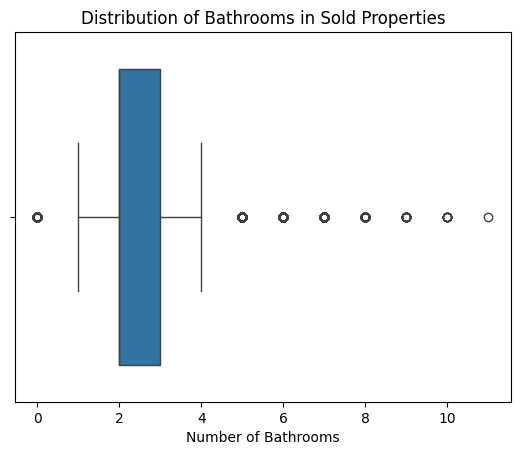

In [168]:
# show distribution boxplot of bedrooms overall
sns.boxplot(x = df_list_eda["BathroomsTotalInteger"])
plt.xlabel("Number of Bathrooms")
plt.title("Distribution of Bathrooms in Sold Properties")
plt.show()

The distribution of bathrooms in active properties listed in market shows:

- The median number of bathrooms is $2$ bathrooms within $1$ bathroom from $2$ to $3$ bathrooms.

- The maximum is 11 bathrooms which likely indicates luxury, and minimum is 1 bathroom that are rare properties

- Because of those minor potential outliers, the bathroom distribution would be right skewed.



#### 2) Bathrooms vs. List Price

In [169]:
group_bath_price =  (df_active.groupby("BathroomGrouped")["ListPrice"]
 .agg(
     count="count",
     min = "min",
     q1= lambda x:x.quantile(0.25),
     median = "median",
     q3 = lambda x:x.quantile(0.75),
     IQR = lambda x:x.quantile(0.75) - x.quantile(0.25),
     max = "max"
 )
).sort_values("median", ascending=False)

group_bath_price

,count,min,q1,median,q3,IQR,max
BathroomGrouped,,,,,,,
5+,4712,199000.0,1349950.0,1998000.0,2781250.0,1431300.0,7300000.0
4,13715,147500.0,899000.0,1299999.0,1999000.0,1100000.0,8950000.0
3,59868,45000.0,655000.0,894492.5,1349000.0,694000.0,6900000.0
2,76008,15000.0,475000.0,669900.0,949000.0,474000.0,4800000.0
1,19935,19000.0,355000.0,499900.0,699900.0,344900.0,3999888.0


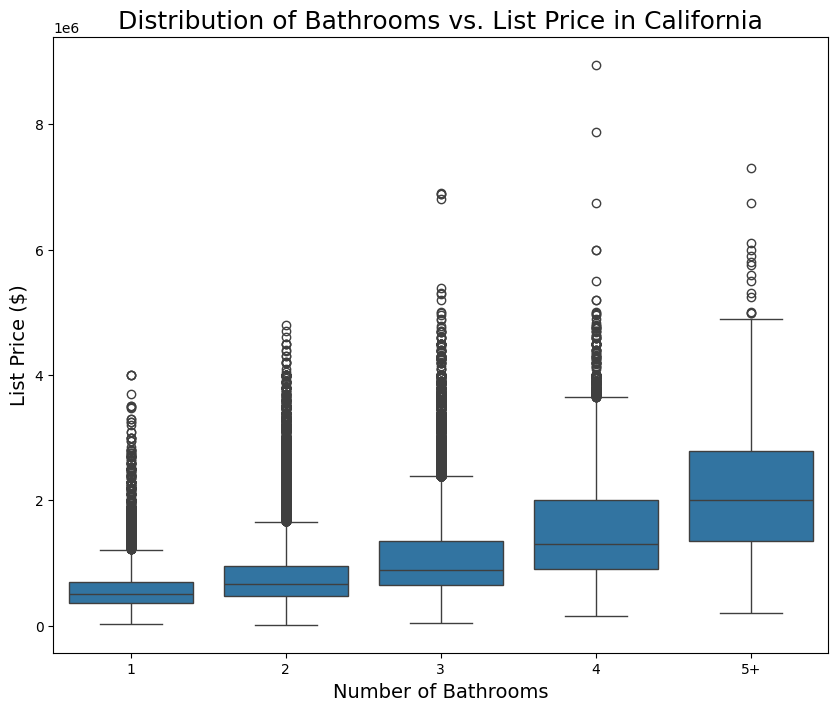

In [170]:
# boxplot distribution for bathrooms vs. close price
plt.figure(figsize=(10, 8))
sns.boxplot(x="BathroomGrouped", y="ListPrice", data=df_active, order = ["1", "2", "3", "4", "5+"])
plt.title("Distribution of Bathrooms vs. List Price in California", fontsize = 18)
plt.xlabel("Number of Bathrooms", fontsize=14)
plt.ylabel("List Price ($)", fontsize= 14)
plt.show()

The list price distribution by each number of bathrooms in active market shows:

- The highest median lsited price is $\$1,998,000$ at more than equal to 5 bathrooms within $\$1,431,300$ spread listed price from $\$1,349,950$ to $\$ 2781,250$.

- The smallest median listed price is $\$\,499,900$ ,at 1 bathrooms within $\$344,900$ spread price from $\$355,000$ to $\$699,900$.

- **The list price tends to increase as number of bathroom increase.**

- The closing price spread becomes wider as number of bathroom increase.

- All the distribution is right skewed due to high outliers pulling mean upward.

- All the number of bathroom contain high outliers of spread that it might reflect on location, living area, or other property characteristics.

- There is at least one IQR range difference, such as 1 bathroom and more than equal to 5 bathroom. **It might indicate there is association with list price and number of bathrooms.**

## 8. Days on Market

Let's identify the distribution of days on market and relationship with other features in active listed market.

In [171]:
function_calculation_IQR(df_active, "DaysOnMarket")
print()
print("Summary distribution Days on Market")
df_active["DaysOnMarket"].describe()

0.25 qunatile: 4.0, and 0.75 quantile 21.0

IQR: 17.0

Summary distribution Days on Market


count    174238.000000
mean         17.418617
std          25.589809
min           0.000000
25%           4.000000
50%          10.000000
75%          21.000000
max         583.000000
Name: DaysOnMarket, dtype: float64

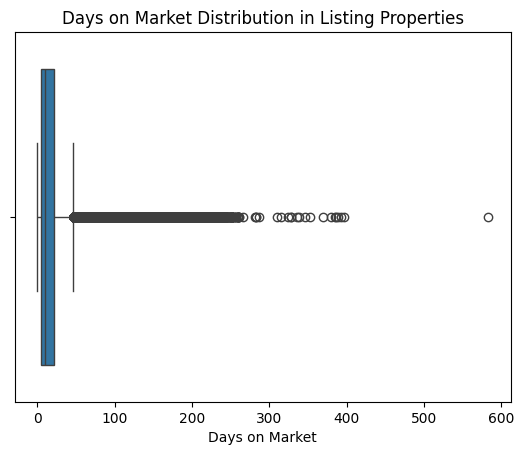

In [172]:
sns.boxplot(x=df_active["DaysOnMarket"])
plt.title("Days on Market Distribution in Listing Properties")
plt.xlabel("Days on Market")
plt.show()

In [173]:
# show the original outliers from data without filtered outliers
function_calculation_outlier(df_list_cleaned[df_list_cleaned["MlsStatus"]=="Active"], "DaysOnMarket")

0.25 quantile is 4.0, and 0.75 quantile is 21.0

lower bound is -21.5, and upper bound is 46.5


The active listed properties of days on market shows:

- The active properties tend to sitting of median 10 days within 17 days spread from 4 days ~ 21 days.

- The maximum days was 583 days and minimum days was 0 days that were sold within that day.

- The originally days in the market outlier was about between 46 days and 47 days, which there are many properties sold later than 46 days or 47 days in the market. These active properties have remained in the market longer than the typical days of 46.5 without yet reaching a completed sale or moving out of Active status. 

- The properties has long term listed in the market might present weak demand, overpricing, property-condition issues, or low buyer interest.




Let's divide the days on market in each terms of days.



In [174]:
def dom_split(days):
    if days <=30:
        return "In a month"
    
    elif days>30 and days <=90:
        return "1-3 months"
    
    elif days >90: 
        return "+3 months"

# add new features in df_active and df_subtype_analysis

df_active["Group_DOM"] = df_active["DaysOnMarket"].apply(dom_split)

df_subtype_analysis["Group_DOM"] = df_subtype_analysis["DaysOnMarket"].apply(dom_split)

In [175]:
df_active["Group_DOM"].value_counts()

Group_DOM
In a month    152773
1-3 months     16585
+3 months       4880
Name: count, dtype: int64

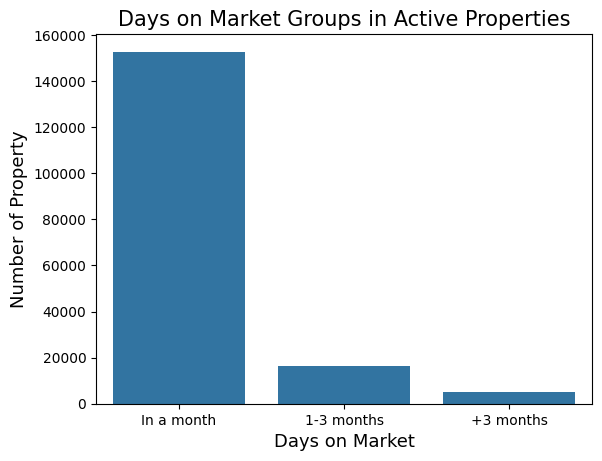

In [176]:
sns.countplot(x="Group_DOM",data= df_active)

plt.title("Days on Market Groups in Active Properties", fontsize = 15)
plt.xlabel("Days on Market", fontsize = 13)
plt.ylabel("Number of Property", fontsize = 13)
plt.show()

- Most of the properties were sold in a month about $152,773$ properties, then 1 to 3 months about $16,585$ properties, the last term of more than 3 months was $4,880$ listed as active in market. 

- Most of the properties sold within a month.

### 1) Days on Market vs. List Price

Let's explore the relationship between days on market and listed price in active properties that checking how active listed price tends to remain on the market. 

In [177]:
group_daysmarket_price =  function_grouped_summary(df_active, "Group_DOM", "ListPrice")

group_daysmarket_price

,count,min,q1,median,q3,IQR,max
Group_DOM,,,,,,,
In a month,152773,17500.0,548000.0,775000.0,1195000.0,647000.0,8950000.0
1-3 months,16585,15000.0,539000.0,763100.0,1195000.0,656000.0,6750000.0
+3 months,4880,55000.0,459000.0,650000.0,988916.0,529916.0,5750000.0


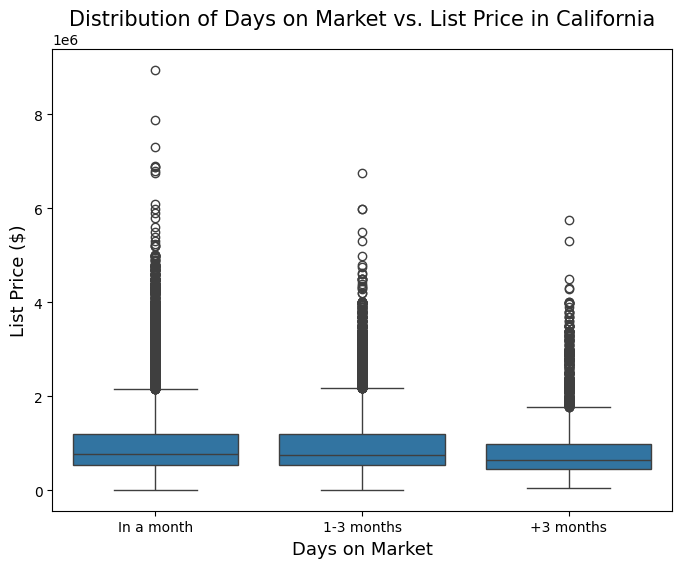

In [178]:
# boxplot distribution for days on market vs. close price
plt.figure(figsize=(8, 6))
sns.boxplot(x="Group_DOM", y="ListPrice", data=df_active)
plt.title("Distribution of Days on Market vs. List Price in California", fontsize = 15)
plt.xlabel("Days on Market", fontsize=13)
plt.ylabel("List Price ($)", fontsize= 13)
plt.show()

- The highest median list price is $\$775,000$ that were listed active in a month, within $\$647,000$ spread price from $\$548,000$ to	$\$1,195,000$.

- The smallest median price was sitting in the market in more than or equal to 3 months of $\$650,000$ within $\$529,916$ spread price from $\$459,000$ ~ $\$988,916$.

- The median list price clearly downward as the time goes past in active days on the market. 

- All the distribution contain many outliers in each terms, which those spread may reflect other impacts from different features.

- There are negative trend of list price as the days increase, however, each boxplot of IQR overlap that relationship appears likely weak association.

Double checking the association, we will use statistical test.

In [179]:
groups = [
    group["ListPrice"]
    for name, group in df_active.groupby("Group_DOM", observed=True)
]

h, p = kruskal(*groups)

print(f"Kruskal-Wallis H: {h:.3f}")
print(f"p-value: {p:.3g}")


Kruskal-Wallis H: 349.039
p-value: 1.61e-76


The null hypothesis is **"All the distribution of close price is same across different terms of days on market."** and the alternative hypothesis is **"At least one days on market term has different distribution of close price."**

- The p-value about 0 is less than 0.05 of signficance level, we reject null hypothesis.

- There is signficant evidence to suggest at least on days on maket term has different distribution of list price. 

- There is significant association between ListPrice and Group_DOM clearly by Krskal Wallis, but due to overlap visualization above, the association is difficult to explain only by days on market.

### 2) Days on Market vs. Ratio (List Price / Living Area)

We will explore the relationship between days on market and ratio of list price per living area. **This will answer of properties that remain on market longer sell for lower or higher prices relative to their living area size.**


First we will show the relationship with living area and days on market, if larger living area takes long term to sell in the market.

In [180]:
group_daysmarket_livingarea = function_grouped_summary(df_active, "Group_DOM", "LivingArea")
group_daysmarket_livingarea

,count,min,q1,median,q3,IQR,max
Group_DOM,,,,,,,
1-3 months,16585,224.0,1264.00,1698.0,2255.0,991.00,5035.0
+3 months,4880,240.0,1210.75,1639.0,2166.0,955.25,4386.0
In a month,152773,120.0,1238.00,1635.0,2170.0,932.00,6038.0


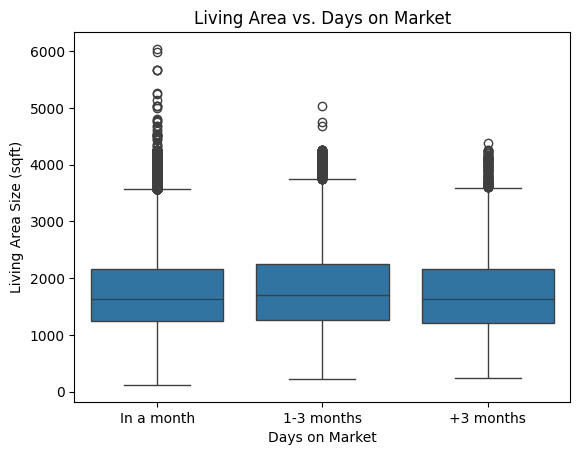

In [181]:
sns.boxplot(
    data=df_active,
    x="Group_DOM",
    y="LivingArea",
)

plt.xlabel("Days on Market")
plt.ylabel("Living Area Size (sqft)")
plt.title("Living Area vs. Days on Market")
plt.show()

- The highest median living area were listed between 1 and 3months $1,698 \,sqft$ within $991 \, sqft$ spread IQR from $1,264\, sqft$ ~ $2,255 \, sqft$. 

- The lowest median sqft is listed more than and equal to 3 months $1,635 \,sqft$ within $932\, sqft$ spread area from $1,238 \,sqft$ ~ $2,170 \,sqft$.

- **There is no direct pattern in this relaitonship.**

- There are many outliers of living area size in all distributions of days on market terms.

- There is weak association between days on market and living area just by looking at this visualization. There is pattern of upward, but there is substantial overlap among groups of IQR range.



Let's make sure using statistical test of Krskal Wallis.

In [182]:
groups = [
    group["LivingArea"]
    for name, group in df_active.groupby("Group_DOM", observed=True)
]

h, p = kruskal(*groups)

print(f"Kruskal-Wallis H: {h:.3f}")
print(f"p-value: {p:.3g}")


Kruskal-Wallis H: 68.171
p-value: 1.57e-15


The null hypothesis is **"All the distribution of living area is same across different terms of days on market."** and the alternative hypothesis is **"At least one days on market term has different distribution of living area."**

- The p-value almost 0 is less than 0.05 of signficance level, we reject null hypothesis.

- **There is signficant evidence to suggest at least on days on maket term has different distribution of living area.**

- There is significant association between **LivingArea** and **Group_DOM** clearly by Krskal Wallis, but due to overlap of IQR range from visualization above, DOM is not enough to explain living area.

Let's check the relationship on ratio of list price per living area considering the results above.

In [183]:
group_daysmarket_price_livingarea = function_grouped_summary(df_active, "Group_DOM", "ListPerSqft")

group_daysmarket_price_livingarea

,count,min,q1,median,q3,IQR,max
Group_DOM,,,,,,,
In a month,152773,11.660448,337.205567,506.221719,705.882353,368.676785,7400.000000
1-3 months,16585,10.845987,325.027086,484.682501,694.736842,369.709757,5964.673913
+3 months,4880,36.111111,287.860962,417.784874,618.056888,330.195925,4001.610306


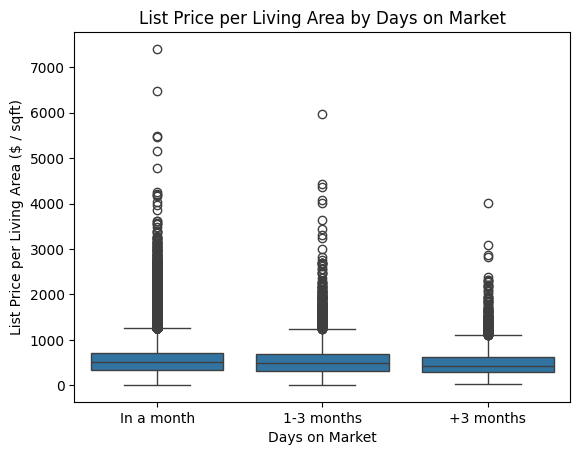

In [184]:
sns.boxplot(
    data=df_active,
    x="Group_DOM",
    y="ListPerSqft",
)

plt.xlabel("Days on Market")
plt.ylabel("List Price per Living Area ($ / sqft)")
plt.title("List Price per Living Area by Days on Market")
plt.show()

- The highest median list price per sqft is about $506 \, \$ \, / \, sqft$ sold in a month, within $369 \, \$ \, / \, sqft$ spread IQR from $337 \, \$ \, / \, sqft$ ~ $706 \, \$ \, / \, sqft$. 

- The smallest median list price per sqft is about $418 \, \$ \, / \, sqft$ at sold later than and equal to 3 months, within $330 \, \$ \, / \, sqft$ spread IQR from $288 \, \$ \, / \, sqft$ ~ $618 \, \$ \, / \, sqft$.

- **There is negative pattern that properties stays on market longer, the ratio of list price per living area decrease.**

- There are many outliers of list price per sqft distribution across all days on market terms.

- There is pattern in the visualization, however, there is overlap across IQR range across days on market terms. There is likely weak association with days on market and list price per sqft just by looking at boxplots.
 

Let's check if the statistical test if there is association between days on market and close price per sqft.

In [185]:
groups = [
    group["ListPerSqft"]
    for name, group in df_active.groupby("Group_DOM", observed=True)
]

h, p = kruskal(*groups)

print(f"Kruskal-Wallis H: {h:.3f}")
print(f"p-value: {p:.3g}")


Kruskal-Wallis H: 429.402
p-value: 5.71e-94


The null hypothesis is "All the distribution of close price per living area size is same across days on market terms", and alernative hypothesis is "At least one distribution of close price per living area size is different across days on market term."

- The p-value of 0 is less than 0.05 of significance level, we reject null hypothesis.

- There is significant evidence to suggest at least one distribution of ratio is different across days on market.

- There is significant association between days on market and price per sqft in Kruskal Wallis test, but due to overlap IQR across days on market, it could not explain itself of list price per living area.

### 3) Days on Market vs. Ratio (List Price / Original List Price)


Let's identify the relationship between days on market and ratio of list price per original listed price in active market. This will answer **whether active properties that sitting in the market longer, evevtually listed further below or above comapre to original price.**

In [186]:
# summary of distribution close price per list price by days on market
group_daysmarket_closeprice_listprice = function_grouped_summary(df_active, "Group_DOM", "RatioOriginalList")

group_daysmarket_closeprice_listprice

,count,min,q1,median,q3,IQR,max
Group_DOM,,,,,,,
In a month,152773,0.500525,1.000000,1.000000,1.0,0.000000,2.000000
1-3 months,16585,0.587940,0.959375,0.986665,1.0,0.040625,1.999500
+3 months,4880,0.533333,0.929349,0.964267,1.0,0.070651,1.767032


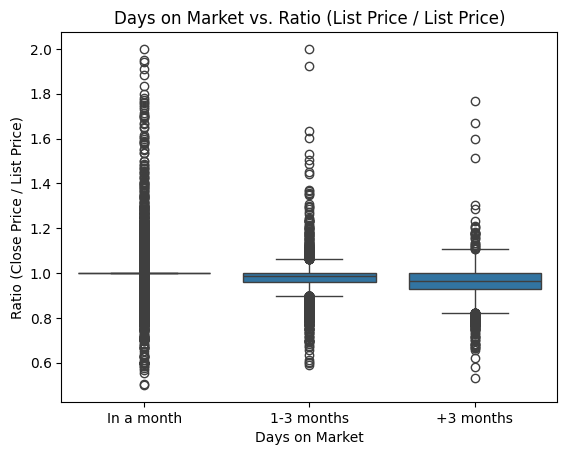

In [187]:
# boxplot
sns.boxplot(x = "Group_DOM", y = "RatioOriginalList", data = df_active)
plt.title("Days on Market vs. Ratio (List Price / List Price)")
plt.xlabel("Days on Market")
plt.ylabel("Ratio (Close Price / List Price)")
plt.show()

- The highest median list price per original price is remained in a month about 1 ratio, within no IQR spread. **This indicates that properties sitting within a month and yet left Active status, tends to be same listed price with original listed price.**

- The smallest median list price per original price is remained later than 3 months and still active, approximately 0.987 within 0.041 spread from 0.0.96 to 1. 

- **The properties remained more than a month and still active, tends to be low its price compared to original listed price.**

- **The ratio declines as days on market increases as downward pattern.**

- There are distributions overlap with downward patterns, indicating there is weak association between days on market and ratio of list price per list price.

Let's check statistical test since visualization is difficult to suggest the assoication.

In [188]:
groups = [
    group["RatioOriginalList"]
    for name, group in df_active.groupby("Group_DOM", observed=True)
]

h, p = kruskal(*groups)

print(f"Kruskal-Wallis H: {h:.3f}")
print(f"p-value: {p:.3g}")


Kruskal-Wallis H: 23173.432
p-value: 0


The null hypothesis is "All the distribution of list price per oritinal price size is same across days on market terms", and alernative hypothesis is "At least one distribution of list price per orignal price size is different across days on market term."

- The p-value of 0 is less than 0.05 of significance level, we reject null hypothesis.

- There is significant evidence to suggest at least one distribution of ratio is different across days on market.

- There is significant association between days on market and ratio in Kruskal Wallis test, however, due to the overlap IQR range in visualizatio above, days on market is not enough to fully explain the ratio. 

### 4) Days on Market vs. Property Subtype

Let's identify the relationship between days on market and property subtype. This would answer if **the active properties are lasting in the market differed by property subtype?**

In [189]:
# summary of median days by property subtypes
group_subtype_daysmarket = function_grouped_summary(df_subtype_analysis, "PropertySubType", "DaysOnMarket")

group_subtype_daysmarket

,count,min,q1,median,q3,IQR,max
PropertySubType,,,,,,,
Townhouse,8231,0,5.0,12.0,22.0,17.0,583
Condominium,29892,0,5.0,11.0,22.0,17.0,335
SingleFamilyResidence,129870,0,3.0,10.0,21.0,18.0,397


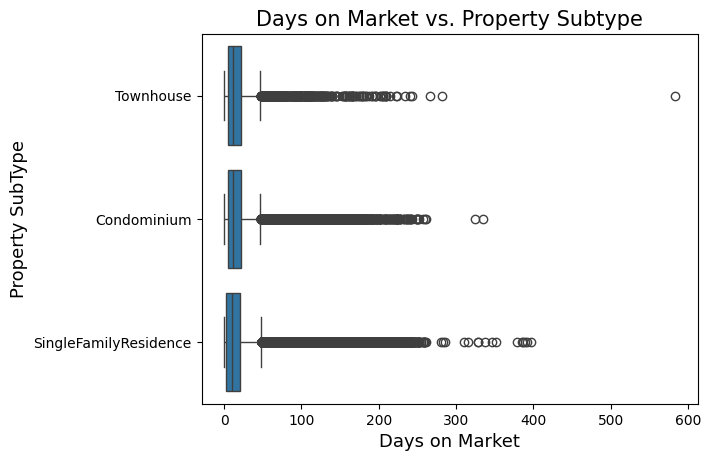

In [190]:
# boxplot distribution of summary between days on market and property subtype
sns.boxplot(x = "DaysOnMarket", y = "PropertySubType", data = df_subtype_analysis, order = group_subtype_daysmarket.index)
plt.title("Days on Market vs. Property Subtype", fontsize = 15)
plt.xlabel("Days on Market", fontsize = 13)
plt.ylabel("Property SubType", fontsize= 13)
plt.show()

- The most short term staying in the markt overall is Single Family Residence median $10$ IQR days within 18 days spread from $3$ days ~ $21$ days. Then, Condominium stays median $11$ days within $18$ IQR days spread from $5$ days ~ $22$ days.

- The most longer term sold overall is Townhouse median $12$ days within $17$ days spread from $5$ days ~ $22$ days.

-  There are overlap of IQR range for days on market across property subtypes. It may likely weak association between days on market and property subtype for active listed properties.

Let's check statistical test.

In [191]:
groups = [
    group["DaysOnMarket"]
    for name, group in df_active.groupby("PropertySubType", observed=True)
]

h, p = kruskal(*groups)

print(f"Kruskal-Wallis H: {h:.3f}")
print(f"p-value: {p:.3g}")


Kruskal-Wallis H: 741.094
p-value: 1.59e-146


The null hypothesis is "All the distribution of days on market is same across property subtypes", and alernative hypothesis is "At least one distribution of days on market size is different across property subtypes."

- The p-value of 0 is less than 0.05 of significance level, we reject null hypothesis.

- There is significant evidence to suggest at least one distribution of ratio is different across days on market.

- There is significant association between days on market and property subtype in Kruskal Wallis test, however, due to the overlap IQR range in visualizatio above, property subtype is not enough to fully explain the days on market. 

### 5) Days Market in 1 Month vs. Property Subtype

In [192]:
# make new feature called sold within 30 days
df_active["Sold30Days"] = df_active["DaysOnMarket"]<=31

In [193]:
# summary of distribution of sold 30 days
df_active["Sold30Days"].value_counts()

Sold30Days
True     154183
False     20055
Name: count, dtype: int64

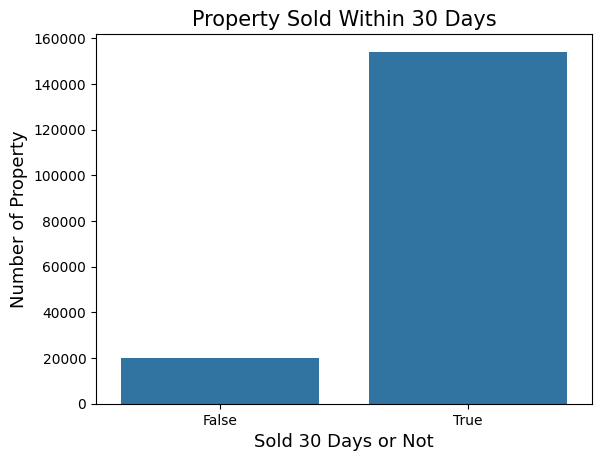

In [194]:
# bar binary distribution of 30 days sold
sns.countplot(x="Sold30Days",data= df_active)
plt.title("Property Sold Within 30 Days", fontsize = 15)
plt.xlabel("Sold 30 Days or Not", fontsize = 13)
plt.ylabel("Number of Property", fontsize = 13)
plt.show()



## 8. Year Built

Let's explore the age of properties that were active listed in California. 

In [195]:
df_active["PropertyAge"].describe()

count    174238.000000
mean         46.275370
std          27.291161
min           0.000000
25%          24.000000
50%          46.000000
75%          65.000000
max         178.000000
Name: PropertyAge, dtype: float64

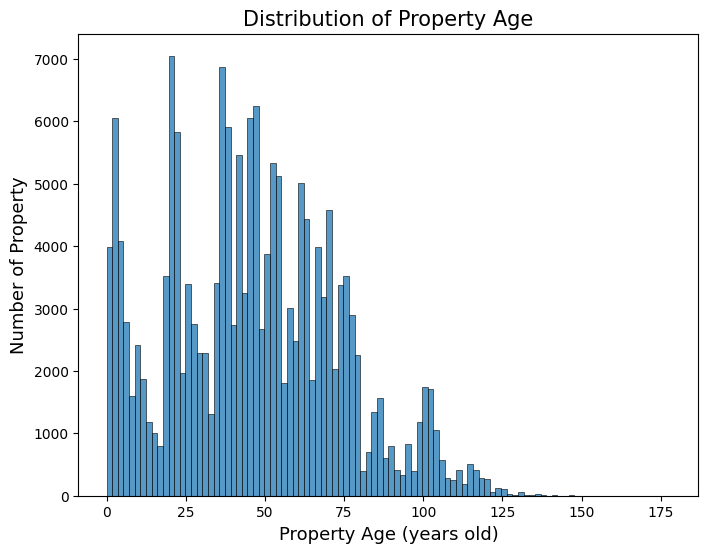

In [196]:
plt.figure(figsize = (8,6))
sns.histplot(x = df_active["PropertyAge"], bins = 100)
plt.title("Distribution of Property Age", fontsize = 15)
plt.ylabel("Number of Property", fontsize = 13)
plt.xlabel("Property Age (years old)", fontsize = 13)
plt.show()

In [197]:
function_calculation_IQR(df_active, "PropertyAge")
print()
function_calculation_outlier(df_list_cleaned[df_list_cleaned["MlsStatus"]=="Active"], "PropertyAge")

0.25 qunatile: 24.0, and 0.75 quantile 65.0

IQR: 41.0

0.25 quantile is 23.0, and 0.75 quantile is 64.0

lower bound is -38.5, and upper bound is 125.5


The property age distribution that were active listed:

- The active properties listed median aged $46$ years old within $41$ years old spread IQR from $24$ years old ~ $65$ years old.

- Very new active properties were built this year 2026 listed over $4,000$ properties.

- Age above $125$ old is extremely rare old were not sold yet count as potential outliers. (Before we handled outliers above)

Let's group the age properties to make easier understanding.

In [198]:
# function for split the age into groups
def age_split(ages):
    if ages<=5:
        return "0-5"
    
    elif ages > 5 and ages<=10:
        return "6-10"
    
    elif ages>10 and ages <=20:
        return "11-20"
    
    elif ages>20 and ages<=40:
        return "21-40"
    
    elif ages>40 and ages<=70:
        return "41-70"
    
    elif ages>70:
        return "70+"

# make new feature for grouping age 
df_subtype_analysis["Group_PropertyAge"] = df_subtype_analysis["PropertyAge"].apply(age_split)

df_active["Group_PropertyAge"] = df_active["PropertyAge"].apply(age_split)

In [199]:
print(df_active["Group_PropertyAge"].value_counts(normalize = True) * 100)

df_active["Group_PropertyAge"].value_counts()


Group_PropertyAge
41-70    37.804038
21-40    24.309852
70+      19.079076
0-5       8.104432
11-20     6.805634
6-10      3.896969
Name: proportion, dtype: float64


Group_PropertyAge
41-70    65869
21-40    42357
70+      33243
0-5      14121
11-20    11858
6-10      6790
Name: count, dtype: int64

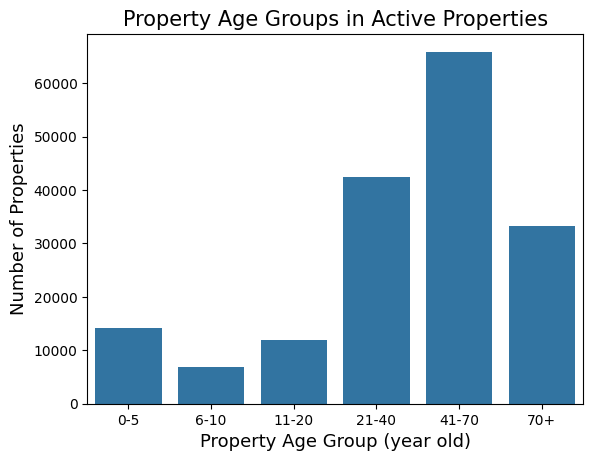

In [200]:
age_order = ["0-5", "6-10", "11-20", "21-40", "41-70", "70+"]

sns.countplot(x="Group_PropertyAge", data = df_active, order = age_order)
plt.title("Property Age Groups in Active Properties", fontsize = 15)
plt.xlabel("Property Age Group (year old)", fontsize = 13)
plt.ylabel("Number of Properties", fontsize = 13)
plt.show()

- The largest group were active listed was **41 ~ 70** years old with about **65,869** properties with roughly **38%** listed active properties. 

- The next largest group is **21 ~ 40** years old, with about **42,357** properties with about $24\%$, followed by the **70+** group, with about **33,243** properties about $19\%$.

- **Overall, the chart suggests that most of active listed properties are built over than 20 years old constructions, rather than earlist years old.

#### 1) Built Age vs. List Price

Let's explore the relationship between active property age and list price. This would answer

- **How does active property age relate to list price?**

- **Do newer and older properties hae different median listed prices?**

- **Which property age groups tend to have higher or lower listed price?**

In [201]:
group_age_price =  function_grouped_summary(df_active, "Group_PropertyAge", "ListPrice")

group_age_price

,count,min,q1,median,q3,IQR,max
Group_PropertyAge,,,,,,,
70+,33243,25000.0,669900.0,925000.0,1449900.0,780000.0,7875000.0
6-10,6790,122999.0,659000.0,849900.0,1259275.0,600275.0,5750000.0
41-70,65869,15000.0,489900.0,749999.0,1189000.0,699100.0,8950000.0
11-20,11858,55000.0,550000.0,729999.5,1049000.0,499000.0,5200000.0
0-5,14121,110000.0,569900.0,711658.0,1004880.0,434980.0,4830000.0
21-40,42357,19000.0,519950.0,699000.0,999900.0,479950.0,7300000.0


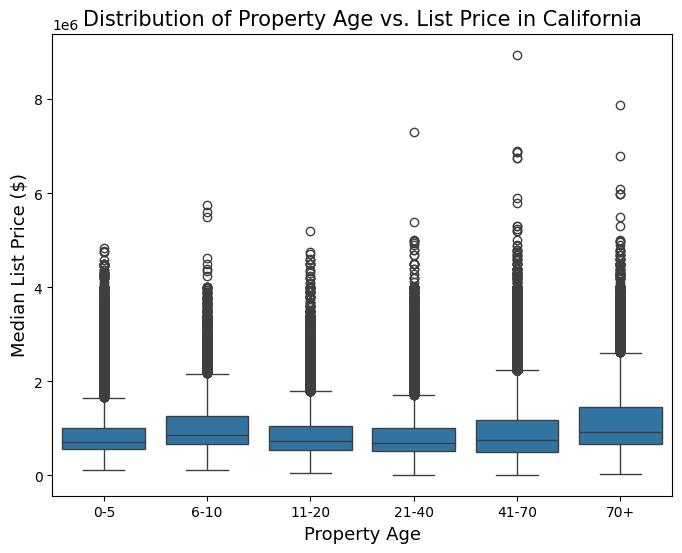

In [202]:
# boxplot distribution for age group vs. close price
plt.figure(figsize=(8, 6))
sns.boxplot(x="Group_PropertyAge", y="ListPrice", data=df_active, order = age_order)
plt.title("Distribution of Property Age vs. List Price in California", fontsize = 15)
plt.xlabel("Property Age", fontsize=13)
plt.ylabel("Median List Price ($)", fontsize= 13)
plt.show()

The listed price distribution by active property age group shows:

- The highest median listed price across active properties is more than 70 years old $\$925,000$ within $\$780,000$ spread IQR price from $\$669,900$ ~ $\$1,449,900$.
 
- The lowest median lsited price is active of newest properties built within 21 to 40 years sold $\$699,000$ within $\$479,950$ spred price from $\$519,950$ ~ $\$999,900$.

- There is no straight pattern between property age and listed price

- There are outliers of listed price across all age groups. 

- It is difficult to identify the association between age group and listed price just looking at the visualization, because there are overalp of box IQR across age groups.

In [203]:
groups = [
    group["ListPrice"]
    for name, group in df_active.groupby("Group_PropertyAge", observed=True)
]

h, p = kruskal(*groups)

print(f"Kruskal-Wallis H: {h:.3f}")
print(f"p-value: {p:.3g}")


Kruskal-Wallis H: 5137.807
p-value: 0


The null hypothesis is "All the distribution of list price is same across age groups", and alernative hypothesis is "At least one distribution of list price is different across age groups."

- The p-value of 0 is less than 0.05 of significance level, we reject null hypothesis.

- There is significant evidence to suggest at least one distribution of list price is different across age groups.

- There is significant association between list price and age groups in Kruskal Wallis test, but due to overlap IQR range across ages group, the age group is not enough to explain list price itself.

As we found there is no pattern we can identify between list price and age group, we will not check ratio of list price per living area ratio and property age relationship.

### 2) Built Age vs. Days on Market

Let's explore the relationship between property age group and days on market that would answer :

- **Do properties of different ages tend to sell different selling time?**

**Yes, selling time differs by property age. Newer properties tend to remain on the market longer, while older properties generally sell more quickly.** 


In [204]:
#distribution property age and days market
group_age_daysmarket = function_grouped_summary(df_active, "Group_PropertyAge", "DaysOnMarket")

group_age_daysmarket

,count,min,q1,median,q3,IQR,max
Group_PropertyAge,,,,,,,
6-10,6790,0,5.0,12.0,23.0,18.0,385
0-5,14121,0,3.0,11.0,23.0,20.0,328
11-20,11858,0,3.0,10.0,21.0,18.0,352
21-40,42357,0,3.0,10.0,21.0,18.0,392
41-70,65869,0,4.0,10.0,21.0,17.0,583
70+,33243,0,4.0,10.0,21.0,17.0,346


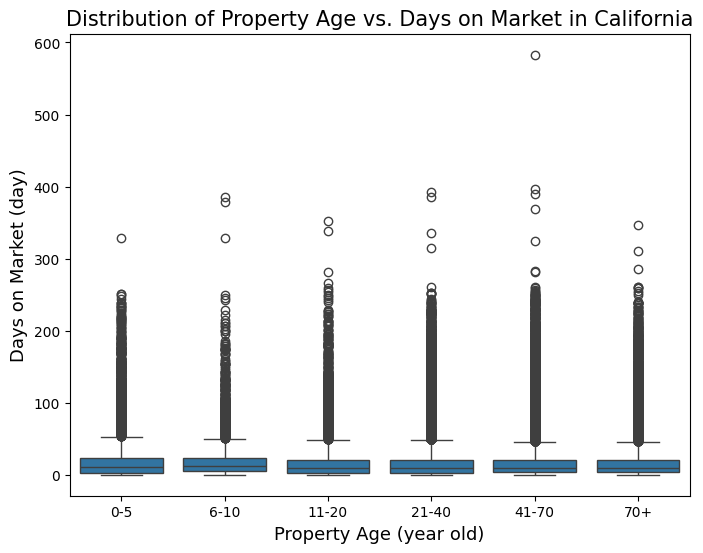

In [205]:
# boxplot distribution for age group vs. days on market
plt.figure(figsize=(8, 6))
sns.boxplot(x="Group_PropertyAge", y="DaysOnMarket", data=df_active, order = age_order)
plt.title("Distribution of Property Age vs. Days on Market in California", fontsize = 15)
plt.xlabel("Property Age (year old)", fontsize=13)
plt.ylabel("Days on Market (day)", fontsize= 13)
plt.show()

- The shortest median days in market listed active was over than **70 years old** of median $10$ days within $17$ days spread from $4$ days ~ $21$ days.

- The longest median days in market listed was new properties in **6 ~ 10 years** old of median $12$ days within $18$ days spread from $5$ days ~ $23$ days.

- **The less days listed active in the market, the less uncertainty of days spread have in that property age.**

- **All ages tend to be stay active less 1 month in California from 2024 to May 2026.**

- **The old properties tend to sold faster then newest properties.**

- Just looking at the visualization, it is difficult to see the association between days on market and property age due to overlap IQR boxes.

In [206]:
groups = [
    group["DaysOnMarket"]
    for name, group in df_active.groupby("Group_PropertyAge", observed=True)
]

h, p = kruskal(*groups)

print(f"Kruskal-Wallis H: {h:.3f}")
print(f"p-value: {p:.3g}")


Kruskal-Wallis H: 104.970
p-value: 4.73e-21


The null hypothesis is "All the distribution of days on market is same across property age groups.", and the alternative hypothesis is "At least one distribution of days in market is different across property age groups"

- The p-value is about 0 less than 0.05 of significant level, we reject null hypothesis.

- There is significant evidence to suggest at least one distribution of days in market is different across property age group.

- **There is significant association between days in market and property age group due to Kruskal Wallis test**.

In [207]:
# distribution of grouped age and grouped days market
group_age_daysmarket3 = pd.crosstab(
    df_active["Group_PropertyAge"],
    df_active["Group_DOM"],
    normalize = "index"
) * 100

age_order = [
    "0-5",
    "6-10",
    "11-20",
    "21-40",
    "41-70",
    "70+"
]

group_age_daysmarket3 = group_age_daysmarket3[["In a month", "1-3 months", "+3 months"]].reindex(age_order)
group_age_daysmarket3


Group_DOM,In a month,1-3 months,+3 months
Group_PropertyAge,,,
0-5,84.696551,11.932583,3.370866
6-10,86.892489,10.544919,2.562592
11-20,87.426210,9.655928,2.917861
21-40,87.706873,9.360908,2.932219
41-70,87.892635,9.339750,2.767615
70+,88.746503,8.789820,2.463677


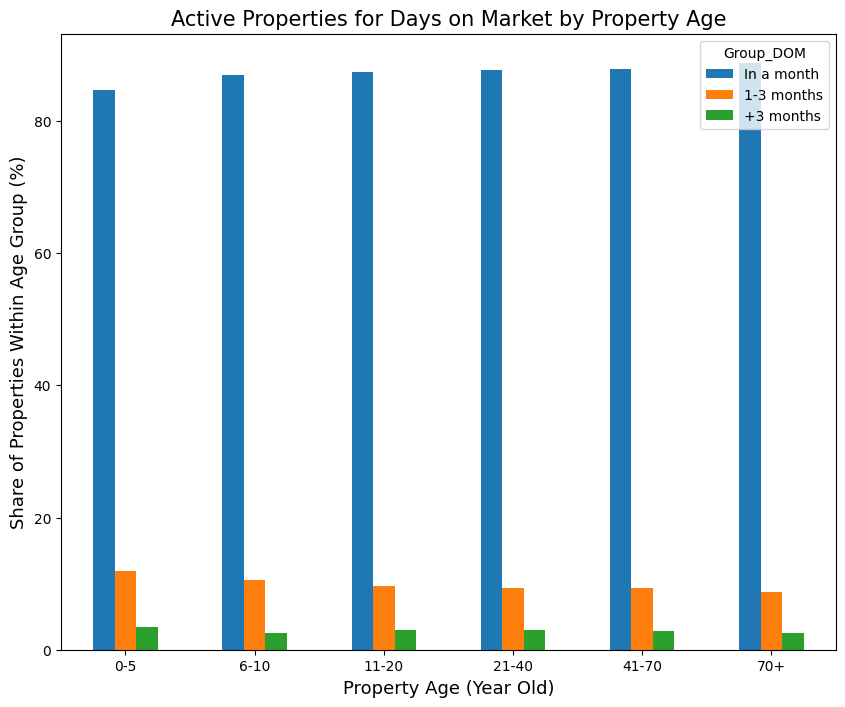

In [208]:
# bar chart distribution 
group_age_daysmarket3.plot(
    kind = "bar",
    figsize = (10, 8),
)
plt.title("Active Properties for Days on Market by Property Age", fontsize = 15)
plt.xlabel("Property Age (Year Old)", fontsize = 13)
plt.ylabel("Share of Properties Within Age Group (%)", fontsize = 13)
plt.xticks(rotation = 0)
plt.show()

Among the active properties in California from 2024 to May 2026 in each group of age property:

- The properties active in a month had the most of properties stayed in the market across all ages.

- The active properties stayed later than 3 months had the lowest properties in the market as active across all ages. 

- **The longer property ages are slightly larger share of active listing within the first month and lightly smaller share in longer days on market, compared newer active properties.**

## 9. Location

### 1) County

Let's identify the distribution of the county that properties were active listed in California from 2024 to May 2026.

In [209]:
# distribution of counties in California
county_count = df_active["CountyOrParish"].value_counts()

county_count

CountyOrParish
Los Angeles        50221
Riverside          30627
San Bernardino     20526
San Diego          14611
Orange             14278
                   ...  
Foreign Country        6
Del Norte              5
Other State            5
Other County           4
Alpine                 1
Name: count, Length: 61, dtype: int64

There are suspicious named called Other State, Other Couty, Other that has less than 10 properties and unrelated to California area. We will drop those values for improving data quality.

In [210]:
# set the suspicious county
invalid_county_labels = county_count[county_count <= 10].index

# take out those invalid county
df = df_list_eda[
    ~df_list_eda["CountyOrParish"].isin(invalid_county_labels)
]

df_active = df_active[
    ~df_active["CountyOrParish"].isin(invalid_county_labels)
]

In [211]:

county_count = df_active["CountyOrParish"].value_counts()

county_count

CountyOrParish
Los Angeles        50221
Riverside          30627
San Bernardino     20526
San Diego          14611
Orange             14278
Alameda             6459
Contra Costa        6267
Santa Clara         5271
Ventura             4807
Kern                2488
Butte               1997
San Luis Obispo     1997
San Mateo           1796
Lake                1386
Santa Cruz          1259
Monterey            1189
Merced              1176
San Joaquin         1013
Madera               833
Fresno               684
Santa Barbara        647
Solano               632
Sacramento           443
San Benito           383
San Francisco        297
Stanislaus           295
Tehama               294
Mendocino            284
Mariposa             276
Imperial             210
Tulare               206
Tuolumne             131
Glenn                130
Kings                115
Calaveras            103
Placer               101
Yuba                  95
Sonoma                85
Shasta                73
El Dorado 

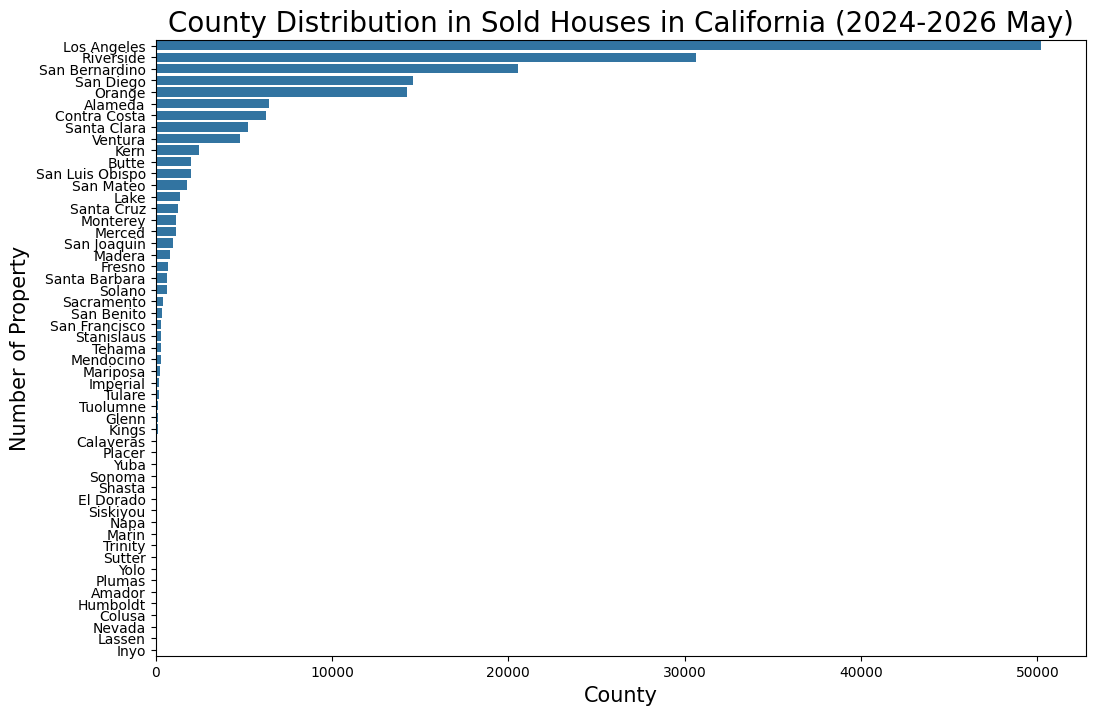

In [212]:
# Barplot distribution for county
plt.figure(figsize=(12,8))
sns.countplot(y="CountyOrParish", data = df_active, order = county_count.index )
plt.title("County Distribution in Sold Houses in California (2024-2026 May)", fontsize=20)
plt.xlabel("County",fontsize = 15)
plt.ylabel("Number of Property", fontsize = 15)
plt.show()

There are many counties that are less properties were listed as sparse data. We will extract into major counties that were listed in **sold_analysis** python file, which 
- Los Angels
    
- Riverside

- Orange

- San Bernardino

- San Diego

- Alameda

- Contra Costa

- Santa Clara

- Ventura

We will assign this analysis in **df_county_analysis** that were over than 4000 properties were listed as active.

In [213]:
# extract only the major county that has over 4000 properties listed 
county_count_top = county_count[county_count >= 4000].index

df_county_subtype_analysis = df_subtype_analysis[df_subtype_analysis["CountyOrParish"].isin(county_count_top)]

df_county_analysis = df_active[df_active["CountyOrParish"].isin(county_count_top)]

# show the distribution of major county properites
major_county = df_county_analysis["CountyOrParish"].value_counts()

major_county

CountyOrParish
Los Angeles       50221
Riverside         30627
San Bernardino    20526
San Diego         14611
Orange            14278
Alameda            6459
Contra Costa       6267
Santa Clara        5271
Ventura            4807
Name: count, dtype: int64

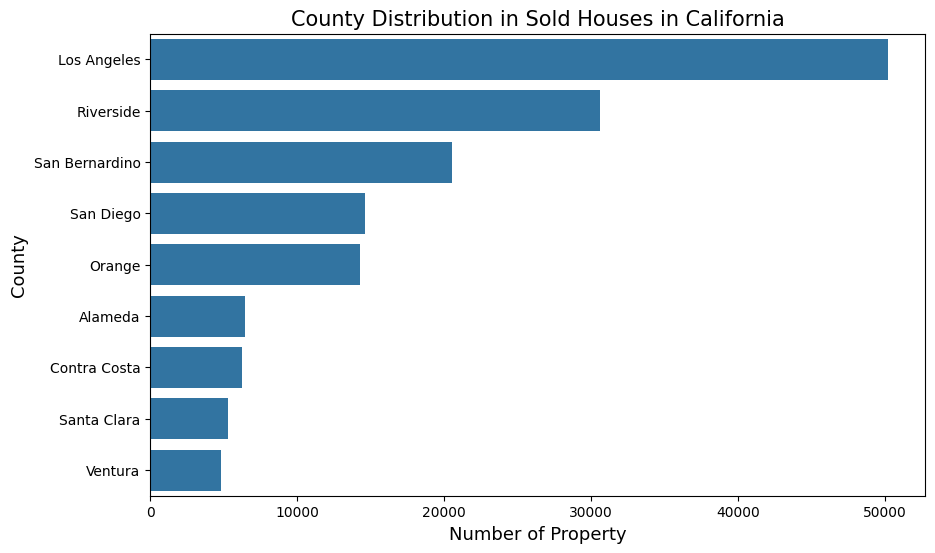

In [214]:
# Barplot distribution for county
plt.figure(figsize=(10,6))
sns.countplot(y="CountyOrParish", data = df_county_analysis, order = county_count_top )
plt.title("County Distribution in Sold Houses in California", fontsize= 15)
plt.xlabel("Number of Property",fontsize = 13)
plt.ylabel("County", fontsize = 13)
plt.show()

The county that properties were sold in California shows:

- The **Los Angeles** were the most top active listed in California with $50,221$ properties.

- Then **Riverside** were top second sold with $30,627$ properties.

- The **Santa Clara** of $5,271$ and **Ventura** of $4,807$ were least active properties in California.

#### 1-a) County vs. Close Price

Let's identify the relationship between county and list price that properties were active in California. This would explore **how much properties were remained in the market typically across different counties.**



In [215]:
group_county_price = function_grouped_summary(df_county_analysis, "CountyOrParish", "ListPrice")

group_county_price

,count,min,q1,median,q3,IQR,max
CountyOrParish,,,,,,,
Santa Clara,5271,348888.0,1100000.0,1549000.0,1999999.0,899999.0,4880000.0
Orange,14278,34500.0,887250.0,1285000.0,1799000.0,911750.0,7875000.0
Alameda,6459,99800.0,679000.0,945888.0,1350000.0,671000.0,2768880.0
Los Angeles,50221,45000.0,689990.0,930000.0,1399000.0,709010.0,3500000.0
San Diego,14611,55000.0,689000.0,900000.0,1285000.0,596000.0,3295000.0
Ventura,4807,162500.0,738944.0,899900.0,1249000.0,510056.0,4175000.0
Contra Costa,6267,140000.0,595000.0,774900.0,1099000.0,504000.0,2950000.0
Riverside,30627,15000.0,482000.0,599999.0,749999.0,267999.0,1600000.0
San Bernardino,20526,19000.0,404500.0,525000.0,675000.0,270500.0,1500000.0


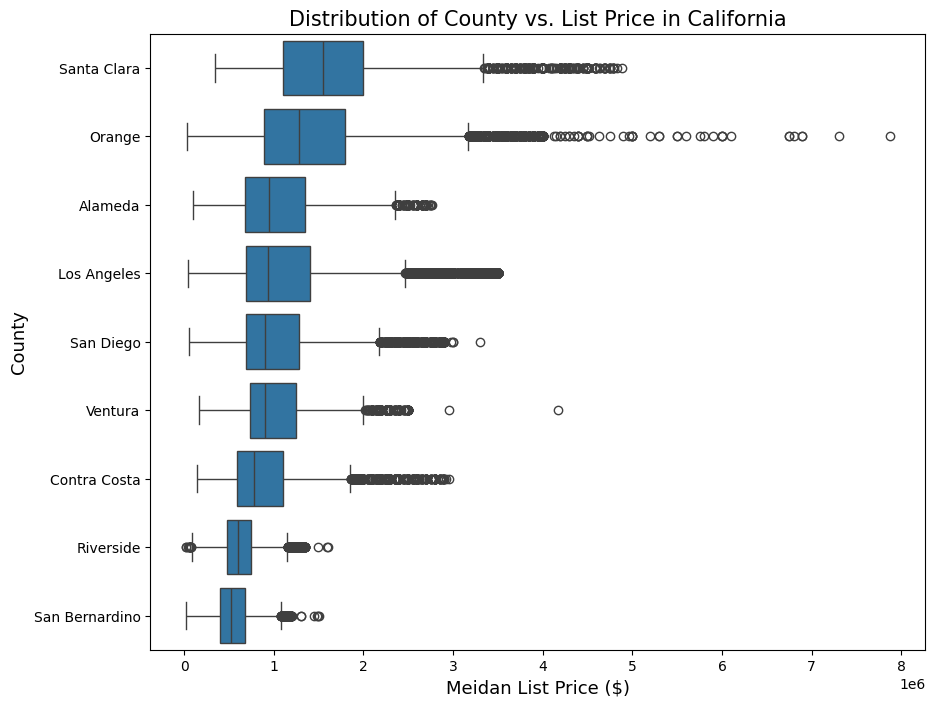

In [216]:
# boxplot distribution for county vs. close price
plt.figure(figsize=(10, 8))

sns.boxplot(x="ListPrice", y="CountyOrParish", data=df_county_analysis, order = group_county_price.index)

plt.title("Distribution of County vs. List Price in California", fontsize = 15)
plt.xlabel("Meidan List Price ($)", fontsize=13)
plt.ylabel("County", fontsize= 13)
plt.show()

The distribution of list price by county of properties that were remained active in California shows:

- The highest median list price was **Santa Clara** $\$1,549,000$ within $\$899,999$ spread of price from $1,100,000\$$ ~ $1,999,999\$$, where least sold from the top 10 county list.

- The least median list price was **San Bernardino** $\$525,000$ within $\$270,500$ spread of price from $\$404,500$ ~ $\$675,000$.

- There is significant association between list price and county due to at least one IQR range different from other county distribution, such as **San Bernardino** and **Santa Clara**.

#### 1-b) County vs. Days On Market

Let's explore **how active properties remained long or short days depends on the county location in the market inventory.**

In [217]:
# summary of days on market distribution by county
group_county_price = function_grouped_summary(df_county_analysis, "CountyOrParish", "DaysOnMarket")

group_county_price

,count,min,q1,median,q3,IQR,max
CountyOrParish,,,,,,,
Santa Clara,5271,0,7.0,14.0,23.0,16.0,397
Alameda,6459,0,7.0,11.0,21.0,14.0,244
Contra Costa,6267,0,7.0,11.0,21.0,14.0,238
Orange,14278,0,4.0,11.0,21.0,17.0,253
Los Angeles,50221,0,5.0,11.0,22.0,17.0,261
Riverside,30627,0,3.0,10.0,23.0,20.0,260
Ventura,4807,0,3.0,10.0,21.0,18.0,227
San Bernardino,20526,0,2.0,8.0,21.0,19.0,257
San Diego,14611,0,1.0,7.0,18.0,17.0,392


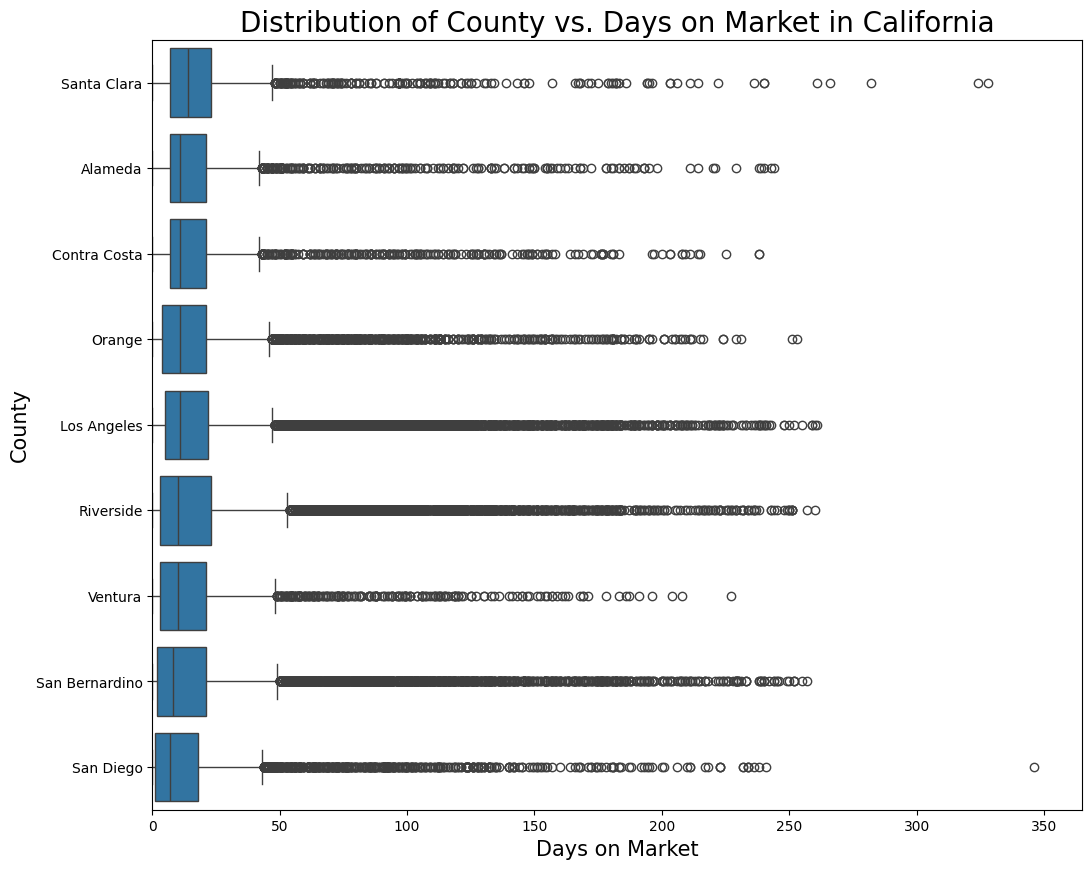

In [218]:
# boxplot distribution for county vs. days on market
plt.figure(figsize=(12, 10))

sns.boxplot(x="DaysOnMarket", y="CountyOrParish", data=df_county_analysis, order = group_county_price.index)

plt.title("Distribution of County vs. Days on Market in California", fontsize = 20)
plt.xlabel("Days on Market", fontsize=15)
plt.xlim(0, 365)
plt.ylabel("County", fontsize= 15)
plt.show()

The days on market distribution by county shows:

- The longest median days on market was **Santa Clara** $14$ days within $16$ days spread from $7$ to $23$ days.

- The shortest median days on market was **San Diego** $7$ days within $17$ days spread from $1$ to $18$ days.

- There is likely weak association between days on market and county just looking at the visualization boxplot. 

- **Santa Clara** properties were remained longest days in the inventory with expensive listed price. However, it tended to be sold faster then other counties from **sold_analysis**, and this indicates that popular or good condition properties were sold fast and unpopular properties were remained in the market.  

- **San Diego** properties tended to be shortest remained in the inventory, and it tended to be sold second fast in sold_analysis. This indicates that San Diego likely sold fast with entering new properties in the inventory.

Let's test the Kruskal Wallis test to check if there is evidence of association.

In [219]:
groups = [
    group["DaysOnMarket"]
    for name, group in df_county_analysis.groupby("CountyOrParish", observed=True)
]

h, p = kruskal(*groups)

print(f"Kruskal-Wallis H: {h:.3f}")
print(f"p-value: {p:.3g}")


Kruskal-Wallis H: 2299.314
p-value: 0


The null hypothesis is "All the distribution of days on market is same across different counties.", and alternative hypotheiss is "At least one distribution of days on market is different across different counties.".

- The p-value of 0 is less than 0.05 of significance level, we reject null hypothesis.

- There is significant evidence to suggest at least one distribution of days on market is different across differecnt counties.

- There is significant association between county and days on market by Kruskal Wallis test, however, due to overlap of days on market IQR range across counties, counties is not enough to explain days on market itself.

#### 1-c) County vs. Price per Living Area

Let's explore the relationship between county and living area, identifying **how ratio of list price per living area perform differ across location of counties.**

We already explored the distribution of list price by county above. It is good to identify how the living area and list price are differ across county first before checking the ratio to understand whole picture.

In [220]:
# summary of distribution of living area by county
group_county_closeprice_sqft = function_grouped_summary(df_county_analysis, "CountyOrParish", "LivingArea")

group_county_closeprice_sqft

,count,min,q1,median,q3,IQR,max
CountyOrParish,,,,,,,
Riverside,30627,400.0,1426.0,1835.0,2357.50,931.50,4259.0
Orange,14278,400.0,1270.0,1739.0,2368.75,1098.75,4520.0
Ventura,4807,400.0,1292.0,1725.0,2268.00,976.00,5246.0
Contra Costa,6267,287.0,1200.0,1682.0,2325.00,1125.00,4257.0
Santa Clara,5271,318.0,1298.0,1637.0,2091.00,793.00,4250.0
San Bernardino,20526,192.0,1205.0,1586.0,2057.00,852.00,4600.0
Los Angeles,50221,162.0,1179.0,1574.0,2114.00,935.00,5984.0
San Diego,14611,311.0,1135.0,1534.0,2118.50,983.50,5035.0
Alameda,6459,406.0,1107.0,1464.0,1935.00,828.00,4259.0


In [221]:
# summary of distribution of list price  by county
group_county_closeprice_sqft = function_grouped_summary(df_county_analysis, "CountyOrParish", "ListPrice")

group_county_closeprice_sqft

,count,min,q1,median,q3,IQR,max
CountyOrParish,,,,,,,
Santa Clara,5271,348888.0,1100000.0,1549000.0,1999999.0,899999.0,4880000.0
Orange,14278,34500.0,887250.0,1285000.0,1799000.0,911750.0,7875000.0
Alameda,6459,99800.0,679000.0,945888.0,1350000.0,671000.0,2768880.0
Los Angeles,50221,45000.0,689990.0,930000.0,1399000.0,709010.0,3500000.0
San Diego,14611,55000.0,689000.0,900000.0,1285000.0,596000.0,3295000.0
Ventura,4807,162500.0,738944.0,899900.0,1249000.0,510056.0,4175000.0
Contra Costa,6267,140000.0,595000.0,774900.0,1099000.0,504000.0,2950000.0
Riverside,30627,15000.0,482000.0,599999.0,749999.0,267999.0,1600000.0
San Bernardino,20526,19000.0,404500.0,525000.0,675000.0,270500.0,1500000.0


- **Orange** county shows median large living area and high meidan listed price in active market inventory. 

- **Alameda** county shows median small living area and high meidan listed price, this indicates that properties tends to be expensive listed considering living area space.

- **Riverside** county shows large living area and low median listed price, this indicates that those properties tends to be not expensive listed considering living area space.



Now let's check the ratio of list price per living area.

In [222]:
# summary of distribution of ratio by county
group_county_PriceSqft = function_grouped_summary(df_county_analysis, "CountyOrParish", "ListPerSqft")

group_county_PriceSqft

,count,min,q1,median,q3,IQR,max
CountyOrParish,,,,,,,
Santa Clara,5271,274.305556,727.203960,933.056872,1179.226311,452.022351,3221.198157
Orange,14278,55.200000,601.492048,706.149797,857.142857,255.650809,5495.185695
Alameda,6459,44.553571,530.210131,640.696609,784.813963,254.603832,2038.043478
Los Angeles,50221,17.509728,499.178307,630.623686,808.213194,309.034886,6475.308642
San Diego,14611,50.925926,483.432145,598.501873,744.790022,261.357876,3488.372093
Ventura,4807,109.501348,460.908991,530.864198,631.836606,170.927615,2393.333333
Contra Costa,6267,129.427083,374.927129,483.319076,628.313847,253.386718,2052.264808
San Bernardino,20526,11.660448,261.622482,333.839299,416.270718,154.648236,1428.428571
Riverside,30627,10.845987,270.672052,321.397757,388.864148,118.192096,1339.285714


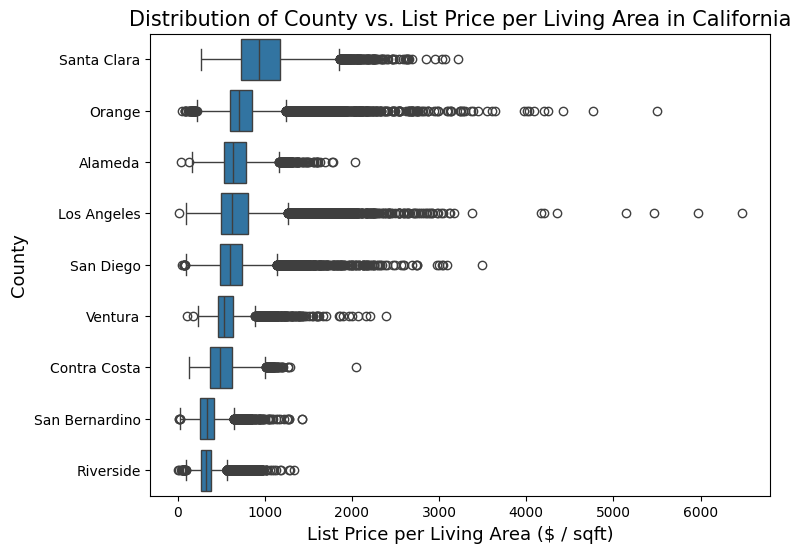

In [223]:
# boxplot distribution for ratio on market
plt.figure(figsize=(8, 6))
sns.boxplot(x="ListPerSqft", y="CountyOrParish", data=df_county_analysis, order = group_county_PriceSqft.index)
plt.title("Distribution of County vs. List Price per Living Area in California", fontsize = 15)
plt.xlabel("List Price per Living Area ($ / sqft)", fontsize=13)
plt.ylabel("County", fontsize= 13)
plt.show()

The distribution of ratio across major counties shows:

- The highest of median ratio was **Santa Clara** $933 \,\$\,/\,sqft$ within $452\, \$ \, / \, sqft$ spread of IQR ratio from approximately $727\, \$ \, / \, sqft$ ~ $1,179\, \$ \, / \, sqft$. 

- The lowest of median ratio was **Riverside** about $321\, \$ \, / \, sqft$ within $118\, \$ \, / \, sqft$ spread of ratio from $270\, \$ \, / \, sqft$ ~ $388\, \$ \, / \, sqft$.

- The **Santa Clara** tend to have listed in active market with decent living area space and expensive compared to other counties, and it has highest ratio of price per living area.

- The **Orange** tends to have high ratio of price per sqft with high price and large living space.

- The **Riverside** tends to be low ratio price per sqft with low price and large living area space.

- The **Alameda** tens to have high ratio of price per sqft with small living space and high price. 

- There is significant association between county and list price per living area that there is at least one difference of IQR range, such as **Riverside** and **Santa Clara**

#### 1-d) County vs. Property Age

 This would show the insight of how property ages perform across different counties. Since many properties sold more than 20 years old, older ages tend to sold fast and expensive, Let's identify the **relationship between county and property age how property ages sell differently across counties.**

In [224]:
group_county_age = function_grouped_summary(df_county_analysis, "CountyOrParish", "PropertyAge")

group_county_age

,count,min,q1,median,q3,IQR,max
CountyOrParish,,,,,,,
Los Angeles,50221,0.0,38.0,61.0,77.0,39.0,146.0
Alameda,6459,0.0,36.0,58.0,84.0,48.0,146.0
Santa Clara,5271,0.0,29.0,53.0,67.0,38.0,154.0
Orange,14278,0.0,30.0,48.0,61.0,31.0,114.0
Contra Costa,6267,0.0,29.0,46.0,61.0,32.0,128.0
Ventura,4807,0.0,32.0,46.0,59.0,27.0,126.0
San Diego,14611,0.0,30.0,46.0,57.0,27.0,116.0
San Bernardino,20526,0.0,21.0,41.0,60.0,39.0,125.0
Riverside,30627,0.0,19.0,27.0,45.0,26.0,128.0


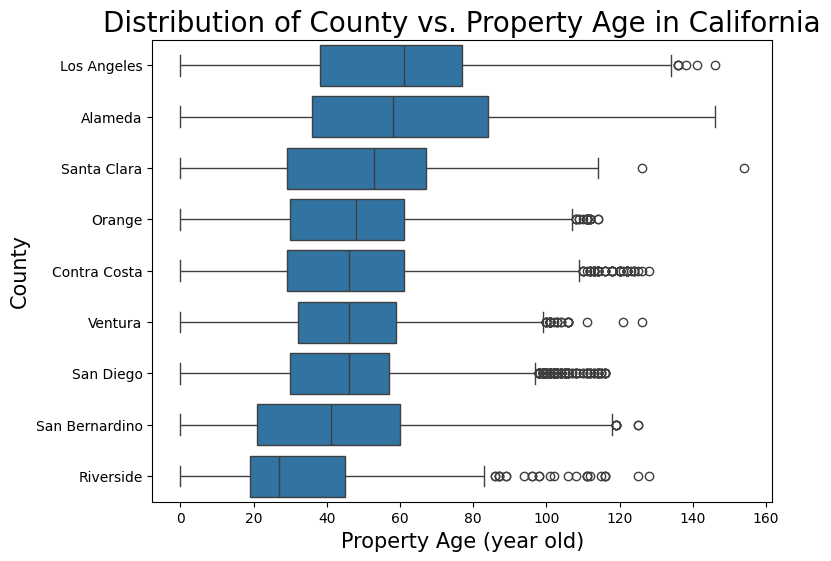

In [225]:
# boxplot distribution for county vs. days on market
plt.figure(figsize=(8, 6))
sns.boxplot(x="PropertyAge", y="CountyOrParish", data=df_county_analysis, order = group_county_age.index)
plt.title("Distribution of County vs. Property Age in California", fontsize = 20)
plt.ylabel("County", fontsize=15)
plt.xlabel("Property Age (year old)", fontsize= 15)
plt.show()

The distribution of property age across different active counties shows:

- Across all major counties tend to have active properties between 27 and 61 years old.

- The **Los Angeles** have likely listed highest median ages of 61 years old within 39 years old spread IQR from 38 years old ~ 77 years old

- The **Riverside** have likely listed on newest of median ages 27 years old within 26 years old spread IQR from 19 years old ~ 45 years old.

- There is moderate association betweeen property age and county that there is at least one difference of IQR range, such as **Riverside** and **Los Angeles**

#### 1-e) County vs. Property Subtypes

Let's identify how property subtypes are sold differ across different counties. 

Let's extract the major subtypes from major counties into Condominium, Duplex, Manufactured on Land, Single Family Residence, Stock Cooperative, and Town House.

**We will compare subtypes were sold in each county indenpendently.**

In [226]:
pd.crosstab(
    df_county_subtype_analysis["CountyOrParish"],
    df_county_subtype_analysis["PropertySubType"],

) 

PropertySubType,Condominium,SingleFamilyResidence,Townhouse
CountyOrParish,,,
Alameda,1438,4420,586
Contra Costa,1176,4543,545
Los Angeles,12125,33679,3159
Orange,3438,9422,832
Riverside,4589,24608,183
San Bernardino,1618,17503,299
San Diego,3195,9968,857
Santa Clara,609,3817,838
Ventura,551,3656,505


In [227]:
# extract the major subpytes in major county analysis
df_county_subtype_analysis = df_county_analysis[df_county_analysis["PropertySubType"].isin(subtype_count_index)]

# compare subtypes in each county as shared 
county_subtype = pd.crosstab(
    df_county_subtype_analysis["CountyOrParish"],
    df_county_subtype_analysis["PropertySubType"],
    normalize= "index"
) * 100

county_subtype

PropertySubType,Condominium,SingleFamilyResidence,Townhouse
CountyOrParish,,,
Alameda,22.315332,68.590937,9.093731
Contra Costa,18.773946,72.525543,8.700511
Los Angeles,24.764103,68.783955,6.451942
Orange,25.115056,68.807071,6.077873
Riverside,15.620532,83.756553,0.622915
San Bernardino,8.333333,90.126700,1.539967
San Diego,22.783365,71.103502,6.113132
Santa Clara,11.569149,72.511398,15.919453
Ventura,11.696031,77.584377,10.719592


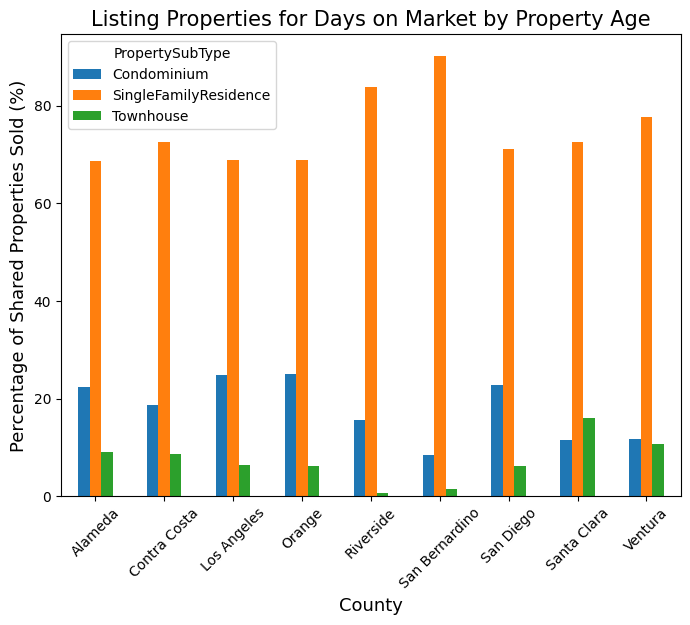

In [228]:
# bar chart distribution 
county_subtype.plot(kind = "bar", figsize = (8, 6))
plt.title("Listing Properties for Days on Market by Property Age", fontsize = 15)
plt.xlabel("County", fontsize = 13)
plt.ylabel("Percentage of Shared Properties Sold (%)", fontsize = 13)
plt.xticks(rotation = 45)
plt.show()

If we look at counties independently to compare sold subtypes:

- Across each counties, the single family residence properties are dominant over $68\%$ in active inventory market. Then, the condonminium and town house follows by next.

- **Orange, Los Angeles, and San Diego** have relatively higher condominium shares, **Santa Clara** has a larger town house share, and **Riverside** and **San Bernardino** have comparatively more manufactured homes.

- The **Riverside** contains the highest number of Single Family Residence listed in active market.

- The **Los Angeles** contains the highest number of Townhouse and Condiminiums in active market.


## 10. Mortgage Rate

Mortgage rates were included as a macroeconomic factor because changes in borrowing costs affect monthly housing payments and buyer purchasing power. Higher rates may reduce affordability and weaken buyer demand, which could influence transaction volume, market speed, and home prices. Therefore, mortgage-rate trends were compared with key CRMLS market indicators to examine whether changes in financing conditions were associated with housing-market performance.

Let's bring the data related to mortgage rate 

In [229]:
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=MORTGAGE30US"
mortgage = pd.read_csv(url, parse_dates=['observation_date'])
mortgage.head()

,observation_date,MORTGAGE30US
0,1971-04-02,7.33
1,1971-04-09,7.31
2,1971-04-16,7.31
3,1971-04-23,7.31
4,1971-04-30,7.29


We will aggregate the mortgage information using the year month of close date.

In [230]:
mortgage.columns = ['date', 'MortgageRate30Fixed']

mortgage['year_month'] = mortgage['date'].dt.to_period('M')
mortgage.head()

,date,MortgageRate30Fixed,year_month
0,1971-04-02,7.33,1971-04
1,1971-04-09,7.31,1971-04
2,1971-04-16,7.31,1971-04
3,1971-04-23,7.31,1971-04
4,1971-04-30,7.29,1971-04


We will group the year month terms with measuring mean of mortgage rate in each monthly term.

In [231]:
mortgage_monthly = (
    mortgage.groupby('year_month')['MortgageRate30Fixed']
    .mean()
    .reset_index()
)

mortgage_monthly.head()

,year_month,MortgageRate30Fixed
0,1971-04,7.3100
1,1971-05,7.4250
2,1971-06,7.5300
3,1971-07,7.6040
4,1971-08,7.6975


Let's merge the data on **df_list_eda** and **df_active** separately

In [232]:
df_list_eda['year_month'] = pd.to_datetime(df_list_eda['ListingContractDate']).dt.to_period('M')

df_list_eda = df_list_eda.merge(mortgage_monthly, on='year_month', how='left')

df_list_eda["MortgageRate30Fixed"].head()

0    6.6425
1    6.6425
2    6.6425
3    6.6425
4    6.6425
Name: MortgageRate30Fixed, dtype: float64

In [233]:
df_active['year_month'] = pd.to_datetime(df_active['ListingContractDate']).dt.to_period('M')

df_active = df_active.merge(mortgage_monthly, on='year_month', how='left')

df_active["MortgageRate30Fixed"].head()

0    6.6425
1    6.6425
2    6.6425
3    6.6425
4    6.6425
Name: MortgageRate30Fixed, dtype: float64

Let's check if there is missing values.

In [234]:
df_list_eda['MortgageRate30Fixed'].isnull().sum()

np.int64(0)

In [235]:
df_active['MortgageRate30Fixed'].isnull().sum()

np.int64(0)

#### 1) Mortgage Rate vs. New Listing Volumne

Let's identify if fewer or more properties enter the market during higher rate periods.

In [236]:
# gourp summary montly mortgage rate by listing key
mortgage_vol = (
    df_list_eda
    .groupby("ListYearMonth")
    .agg(
        MortgageRate = ("MortgageRate30Fixed", "median"),
        NewListingCount = ("ListingKey", "count")
    ).reset_index()

)


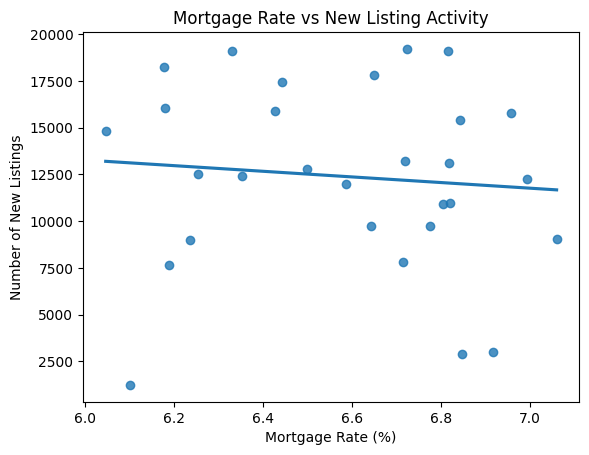

In [237]:
sns.regplot(
    data=mortgage_vol,
    x="MortgageRate",
    y="NewListingCount",
    ci=None
)

plt.xlabel("Mortgage Rate (%)")
plt.ylabel("Number of New Listings")
plt.title("Mortgage Rate vs New Listing Activity")
plt.show()

In [238]:
mortgage_vol[["MortgageRate", "NewListingCount"]].corr()

,MortgageRate,NewListingCount
MortgageRate,1.00000,-0.09233
NewListingCount,-0.09233,1.00000


The relationship between mortgage rate and number of properties entered in the market shows negative weak association with -0.09 correlation.

The higher mortgage rates were not tend to be associated with newer new listings.

#### 2) Mortgage Rate vs. Days on Market

Let's identify if there is relationship between monthly mortgage rate and days on market that if high mortgage affect the sellong properties staying in market.

In [239]:
mortgage_active = (
    df_active
    .groupby("ListYearMonth")
    .agg(
        MortgageRate=("MortgageRate30Fixed", "median"),
        MedianDOM=("DaysOnMarket", "median")
    )
    .reset_index()
)

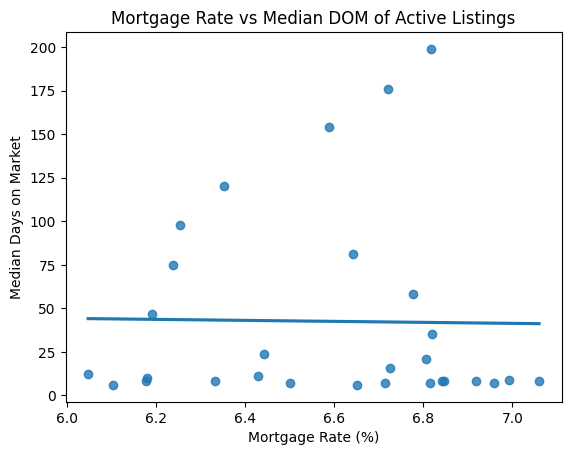

In [240]:
sns.regplot(
    data=mortgage_active,
    x="MortgageRate",
    y="MedianDOM",
    ci=None
)

plt.xlabel("Mortgage Rate (%)")
plt.ylabel("Median Days on Market")
plt.title("Mortgage Rate vs Median DOM of Active Listings")
plt.show()

In [241]:
mortgage_active[["MortgageRate", "MedianDOM"]].corr()

,MortgageRate,MedianDOM
MortgageRate,1.000000,-0.015282
MedianDOM,-0.015282,1.000000


There is almost no linear association between mortgage rate and days on market for active listings with -0.015 correlation.

#### 3) Mortgage Rate vs. List Price

Let's explore if there is mortgage rate and list price relationship if the high mortgage rate has impact on properties are listed in market inventroy.

In [242]:
mortgage_listprice = (
    df_list_eda
    .groupby("ListYearMonth")
    .agg(
        MortgageRate=("MortgageRate30Fixed", "median"),
        MedianListPrice=("ListPrice", "median"),
        MedianListPPSF=("ListPerSqft", "median")
    )
    .reset_index()
)

<Axes: xlabel='MortgageRate', ylabel='MedianListPrice'>

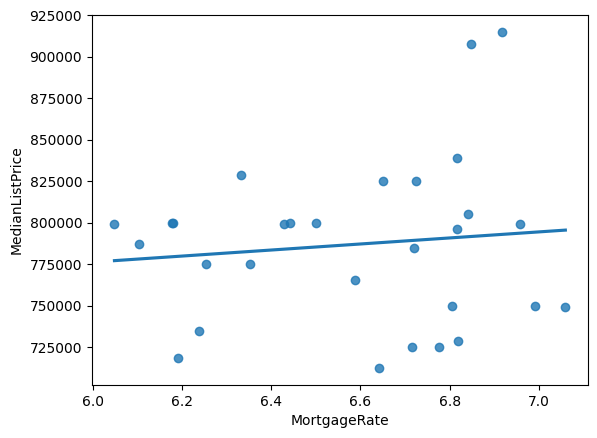

In [243]:
sns.regplot(
    data=mortgage_listprice,
    x="MortgageRate",
    y="MedianListPrice",
    ci=None
)

In [244]:
mortgage_listprice[["MortgageRate", "MedianListPrice"]].corr()

,MortgageRate,MedianListPrice
MortgageRate,1.000000,0.109456
MedianListPrice,0.109456,1.000000


There is weak positive association between mortgage rate and list price with approximetly 0.11 correlation. It does not likely appear to explain if monthly mortgage has impact on listed price for entered properties. 

## 9. Contract Date

In previous preprocessing, there was contract date features of ***ListContractDate*** changed to ***ListYearMonth*** as proper date type, and ***ContractStatusChangeDate***. We will use ListYearMonth to identify the historical transaction of  the overall residential properties where it entered the makert from ***df_list_eda*** dataset. 


### 1) Number of Properties Entering Over Time
Let's count how many entered properties did entered the market in each monthly term using listing key, and track the market performance. 

Additionally, we will enter the df_active dataset to check the current inventory of residential properties in the listing market. this would help us understand differences between overall listing activity and distribution of currently Active listings

- ***df_list_eda***: Used to analyze the properties entered the market during each listing term, regardless of recorded MLS status.

- ***df_actvie***: Used to analyze the current properties are listed in the market as Active.

The question would be:

- **How many of the number of new residential properties changed over time?**

- **Are there patterns or trend in new listing activeity?**

- **How does the monthely distribution of currently Active listings differ from overall new listing activity?**




In [245]:
# convert the listing contract date into time stamp
df_list_eda["ListYearMonth"] = (
    df_list_eda["ListYearMonth"].dt.to_timestamp()
)

# count listed properites using listing key
monthly_new_listings = (
    df_list_eda
    .groupby("ListYearMonth")
    .agg(NewListings=("ListingKey", "count"))
    .reset_index()
)

# convert the listing contract date into time stamp
df_active["ListYearMonth"] = (
    df_active["ListYearMonth"].dt.to_timestamp()
)

# count listed active proeprties
monthly_new_listings_active = (
    df_active
    .groupby("ListYearMonth")
    .agg(NewListings=("ListingKey", "count"))
    .reset_index()
)


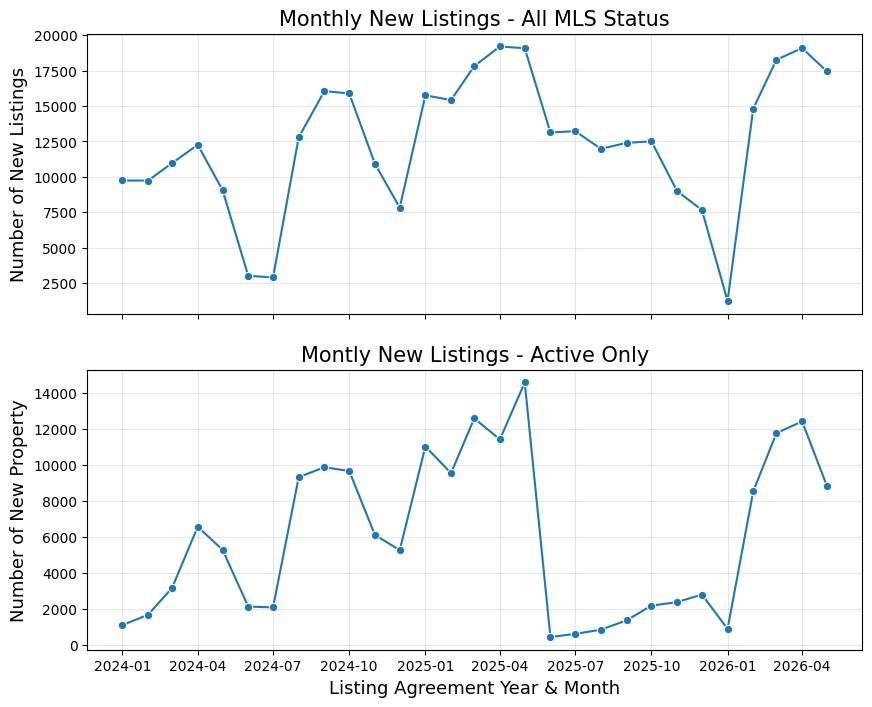

In [246]:
fig, axes = plt.subplots(2, 1, figsize = (10, 8), sharex=True)

# first graph: Overall MLS status
sns.lineplot(
    data = monthly_new_listings,
    x = "ListYearMonth",
    y = "NewListings",
    marker = "o",
    ax = axes[0]
)

axes[0].set_title("Monthly New Listings - All MLS Status", fontsize = 15)
axes[0].set_xlabel("Listing Year & Month", fontsize = 13)
axes[0].set_ylabel("Number of New Listings", fontsize = 13)
axes[0].grid(alpha = 0.3)

# second graph: Active MLS status
sns.lineplot(
    data = monthly_new_listings_active,
    x = "ListYearMonth",
    y = "NewListings",
    marker = "o",
    ax = axes[1]
)

axes[1].set_title("Montly New Listings - Active Only", fontsize = 15)
axes[1].set_xlabel("Listing Agreement Year & Month", fontsize = 13)
axes[1].set_ylabel("Number of New Property", fontsize = 13)
axes[1].grid(alpha = 0.3)

plt.show()


1. All MLS status new listings:

- The number of new listings ranged from approximately 1,300 to 19,200 properties, showing monthly listing fluctuations.

- The highest peak of listing property volume occured around April and May 2025 reaching about 19,000 listings. Similary, listing activity increased from January till April 2026.

- Listing properties decreased around May and June in both 2024 and 2025, also around November and December 2024 and 2025.


2. Active status new listings:

- The number of new listings ranged from approximately 1,300 to 14,500 properties, showing monthly listing fluctuations.

- There are increased listing properties from January till April in each year, and flucuation increasement from December 2024 till around May 2025.

- isting properties decreased from April till around June in each year.

- **Both status are showing potential seasonal pattern that listing properties increase January till April, and decline from April till around June in each year. However, the unusual shapr fluctuations prevent from confidently identifying a consistent seasonal pattern.**

- **There are some terms that are different between overall MLS status and Active status, especially around May 2025 till January 2026. This might indicate that many properties changed their status from Active to others, while many properties from overall mls status are gradually declined, and new Active properties are coming into the inventory.**

### 2) List Price & Original List Pice Over Time

Let's identify how did list price and original list price recorded over time and see the difference changed over time as well

- **How did asking prices of overall residential properties changed over time before sold, was there asking price adjustment?** 


In [247]:
# MLS overall listing contract with price
contract_price = (
    df_list_eda.groupby("ListYearMonth")
    .agg(
        MedianListPrice=("ListPrice", "median"),
        MedianOriginalPrice=("OriginalListPrice", "median"),
        ContractCount=("ListPrice", "size")
    )
    .reset_index()
)

# Active listing contract with price
contract_price_active = (
    df_active.groupby("ListYearMonth")
    .agg(
        MedianListPrice=("ListPrice", "median"),
        MedianOriginalPrice=("OriginalListPrice", "median"),
        ContractCount=("ListPrice", "size")
    )
    .reset_index()
)

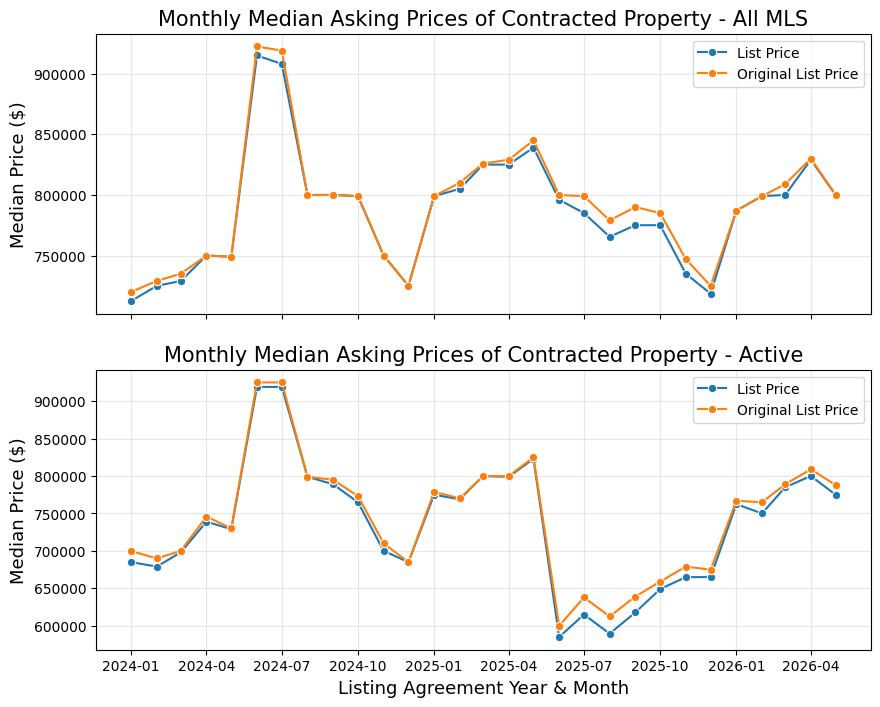

In [248]:
# first graph: MLS overall listing price
fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex = True)

sns.lineplot(
    data=contract_price,
    x="ListYearMonth",
    y="MedianListPrice",
    marker="o",
    label="List Price",
    ax = axes[0]
)

sns.lineplot(
    data=contract_price,
    x="ListYearMonth",
    y="MedianOriginalPrice",
    marker="o",
    label="Original List Price",
    ax = axes[0]
)

axes[0].set_title("Monthly Median Asking Prices of Contracted Property - All MLS", fontsize = 15)
axes[0].set_xlabel("Listing Agreement Year & Month", fontsize = 13)
axes[0].set_ylabel("Median Price ($)", fontsize = 13)
axes[0].grid(alpha=0.3)

# second graph: Active listing price
sns.lineplot(
    data=contract_price_active,
    x="ListYearMonth",
    y="MedianListPrice",
    marker="o",
    label="List Price",
    ax = axes[1]
)

sns.lineplot(
    data=contract_price_active,
    x="ListYearMonth",
    y="MedianOriginalPrice",
    marker="o",
    label="Original List Price",
    ax = axes[1]

)

axes[1].set_title("Monthly Median Asking Prices of Contracted Property - Active", fontsize = 15)
axes[1].set_xlabel("Listing Agreement Year & Month", fontsize = 13)
axes[1].set_ylabel("Median Price ($)", fontsize = 13)
axes[1].grid(alpha=0.3)
plt.show()


- **The original list price and list price tend to follow similarily, but list prices are slightly greater than original list prices about $\$10,000$ difference from only June through December 2025.**

- ***All MLS Status***

    - The properties that listed were gradually increase from January to April 2024, then sharply increased until June and maintained July, then gradually declined till December 2024. 

    - In 2025, the median listed price gradually increased till May, then gradually declined till December. Then it increased in 2026 till April.

    - **There are potential pattern for listed price that it tends to increase from January till May, then it starts to decrease gradually July till Decemeber in each year.**
    

- ***Active Status (Current inventory)***

    - In 2024, listed median price on current inventory gradually increased till April, then sharply increased June and July, then gradually declined till December

    - In 2025, median price gradually increased from Janaury till May, then it sharply declined lowest price June, then it gradually increased till next year April 2026.

    - **There are not clear pattern in Active status properties that were remained in current inventory in each term.**


### 3) Timeline Number of Listing Property by MLS Status

After we explored the transaction records on both overall MLS status and Active, we found that 2025 had many fluctuation that Active listed properties had changed their MLS status. We will check what happened on those inventory transactions. 

Additionally, we want to identify how listed properties had changed thier status overall in 2024 through May 2026 as well.

- **How does the number of residential listings vary across MLS statuses by listing month?**

- **How has the proportion of each recorded MLS status varied among properties listed between January 2024 and May 2026?**

- **What explains the substantial difference between overall and Active listing counts observed?**

It is not necessary to investigate "***ComingSoon***"  in MLS status variable in this stage. We will temporatroy exclude it from ***df_list_eda***.

We will measure the count of listing properties and median list price to check  how properties are distributed in the inventory across MLS status, and how asking price changes. 

In [249]:
# exclude ComingSoon value
df_mls = df_list_eda[df_list_eda["MlsStatus"] != "ComingSoon"]

# group by time and mls status on listing count and median list price
group_mls = (
    df_mls
    .groupby(["ListYearMonth", "MlsStatus"])
    .agg(
        ListingCount = ("ListYearMonth", "count"),
        MedianListPrice = ("ListPrice", "median")
    ).reset_index()
)

# show the distribution of mls status and chart
print("MLS Status counts")
print(df_mls["MlsStatus"].value_counts())
print("--" * 20)
print("Grouped Contract by MLS Status")
group_mls




MLS Status counts
MlsStatus
Active                 174303
Closed                  99125
Pending                 57909
ActiveUnderContract     26732
Name: count, dtype: int64
----------------------------------------
Grouped Contract by MLS Status


,ListYearMonth,MlsStatus,ListingCount,MedianListPrice
0,2024-01-01,Active,1094,682250.0
1,2024-01-01,ActiveUnderContract,225,650000.0
2,2024-01-01,Closed,7850,729900.0
3,2024-01-01,Pending,575,605000.0
4,2024-02-01,Active,1662,678500.0
...,...,...,...,...
111,2026-04-01,Pending,3816,850000.0
112,2026-05-01,Active,8830,775000.0
113,2026-05-01,ActiveUnderContract,1588,799000.0
114,2026-05-01,Closed,3437,900000.0


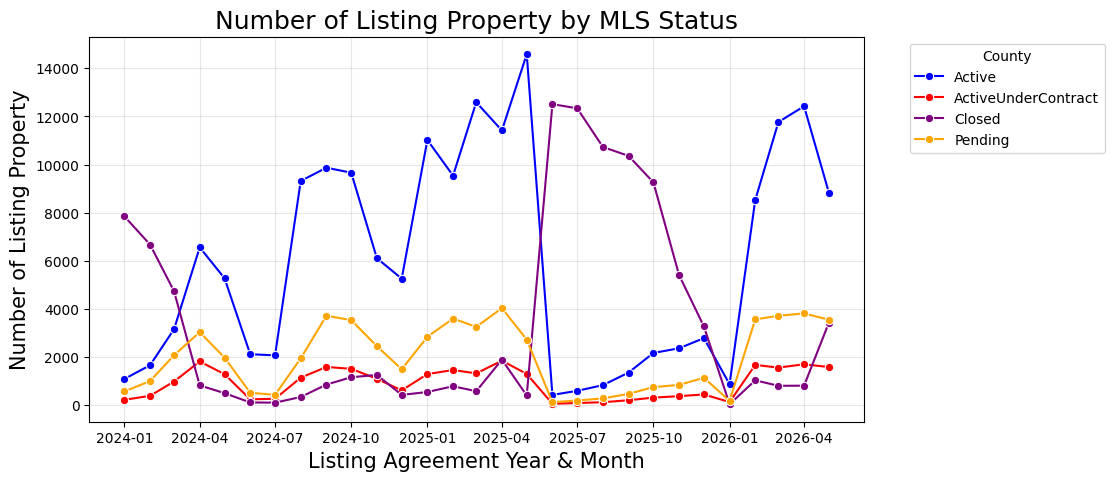

In [250]:
# assign the color by mls status
color = {
    "Active": "blue",
    "Closed": "purple",
    "Pending": 'orange',
    'ActiveUnderContract': 'red'
}

# shwo the graph timeline
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=group_mls,
    x="ListYearMonth",
    y="ListingCount",
    hue="MlsStatus",
    palette = color,
    marker="o"
)

plt.title("Number of Listing Property by MLS Status", fontsize = 18)
plt.xlabel("Listing Agreement Year & Month", fontsize = 15)
plt.ylabel("Number of Listing Property", fontsize = 15)


plt.legend(
    title="County",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)
plt.show()

- ***Active Status (Current Inventory)***

    - Active properties sharpely declined from around 14,500 to 1,300 properties on May 2025, and increasing sharpely again early 2026 around to 12,500 listing properties.

    - There was many new listing agreement properties in 2025 compare to 2024 and 2026.

- ***Closed Status***

    - Number of properties declined substantually during Spring 2024 and remained relativelylow through early 2025.

    - There was sharpely increased in June 2025 to approximately 12,500 properties, then it remained until July, then declined and low listings through April 2026.


- ***Pending and Active Under Contract Status***

    - Pending counts increased during several periods of 2024 and early 2025, with another noticeable increase in spring 2026.

    - ActiveUnderContract listings generally remained below approximately 2,000 properties per month.

    - Both statuses showed relatively low counts during June to December 2025 compared with their earlier peaks.


- **The most interesting part is January 2026 that all the MLS status properties had declined into lowest number of new listing properties agreement.**

    - The potential reason might be the real estate listing agreements were shaped by updated California Association of REALTORS standard forms and new sate laws and Department of Real Estate exclusive right-to-sell listing agreement, these updates added stricter marketing, disclosure, and representation rules. 

    - https://www.pwr.net/blog/new-c-a-r-forms-for-2026-key-updates-realtors-must-know-tri 

### 4) Timeline Number of Listing Property by County 

Let's explore how overall listed properties act differently across Califorina counties in terms of number of properties through January 2024 through May 2026. This analysis will help us determine whether fluctuations in location listing activity are consistent across counties. 

- How has monthly number of new residential listings changed and behaved across California counties? 

In previous analysis from county, we only made the dataset on ***Active*** status data extracting only comparable major counties. We will do same process on overall status in ***list_data_eda***.

In [251]:
# view all the counties 
county_count_all = df_list_eda["CountyOrParish"].value_counts()

county_count_all

CountyOrParish
Los Angeles        101911
Riverside           54747
San Bernardino      38521
Orange              35219
San Diego           33740
                    ...  
Foreign Country         6
Other County            5
Alpine                  1
Sierra                  1
Clark                   1
Name: count, Length: 63, dtype: int64

In [252]:
# extract only the major county that has over 4000 properties listed 
county_count_top = county_count_all[county_count_all >= 10000].index

df_county_analysis_all = df_list_eda[df_list_eda["CountyOrParish"].isin(county_count_top)]

# show the distribution of major county properites
df_county_analysis_all["CountyOrParish"].value_counts()



CountyOrParish
Los Angeles       101911
Riverside          54747
San Bernardino     38521
Orange             35219
San Diego          33740
Alameda            15451
Contra Costa       14802
Santa Clara        12691
Ventura            10109
Name: count, dtype: int64

Let's group with listing contract date, then group with major counties measuring listing count and median list price for later analysis. 

In [253]:
# group contract date and county measuring count properties and median listed price
contract_county = (
    df_county_analysis_all
    .groupby(["ListYearMonth", "CountyOrParish"])
    .agg(
        ListingCount = ("ListYearMonth", "count"),
        MedianListPrice = ("ListPrice", "median")
    ).reset_index()
)


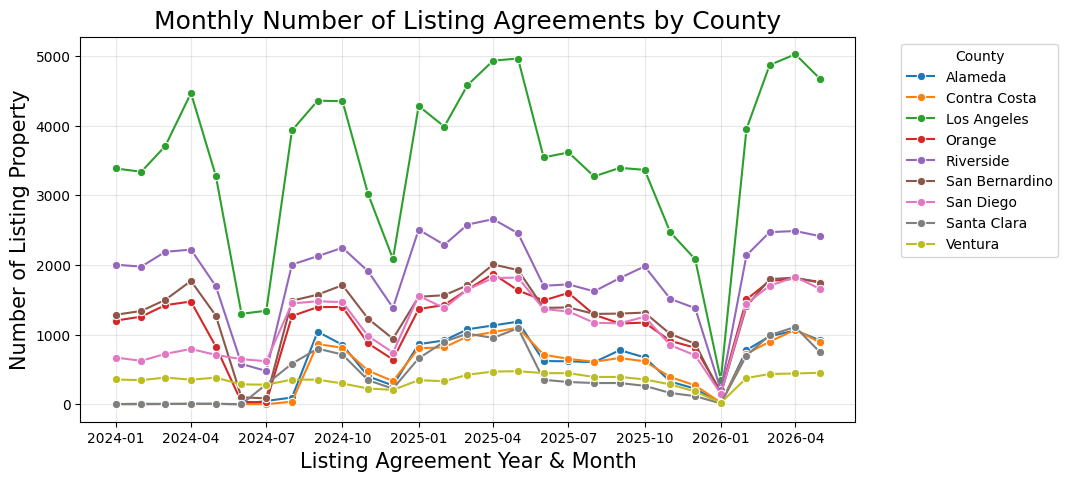

In [254]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=contract_county,
    x="ListYearMonth",
    y="ListingCount",
    hue="CountyOrParish",
    marker="o"
)

plt.title("Monthly Number of Listing Agreements by County", fontsize = 18)
plt.xlabel("Listing Agreement Year & Month", fontsize = 15)
plt.ylabel("Number of Listing Property", fontsize = 15)

plt.legend(
    title="County",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.grid(alpha=0.3)
plt.show()

Overall, there are some major counties behave similarily across timeline, however, it is difficult to analyze in details. We will split into two graph to analyze that has similar performance. 

In [255]:
# divide counties into two groups
counties_group1 = [
    "Alameda",
    "Ventura",
    "Santa Clara",
    "Contra Costa",
    "San Diego",
]

counties_group2 = [

    "Riverside",
    "San Bernardino",
    "Los Angeles",
    "Orange",

]

# filter data group county 1
county_price_group1 = df_county_analysis_all[
    df_county_analysis_all["CountyOrParish"].isin(counties_group1)
]

# filter data group county 2
county_price_group2 = df_county_analysis_all[
    df_county_analysis_all["CountyOrParish"].isin(counties_group2)
]

# group the contract time and county in each group of counties
contract_county1 = (
    county_price_group1
    .groupby(["ListYearMonth", "CountyOrParish"])
    .agg(
        ListingCount = ("ListYearMonth", "count"),
        MedianListPrice = ("ListPrice", "median")
    ).reset_index()
)

contract_county2 = (
    county_price_group2
    .groupby(["ListYearMonth", "CountyOrParish"])
    .agg(
        ListingCount = ("ListYearMonth", "count"),
        MedianListPrice = ("ListPrice", "median")
    ).reset_index()
)

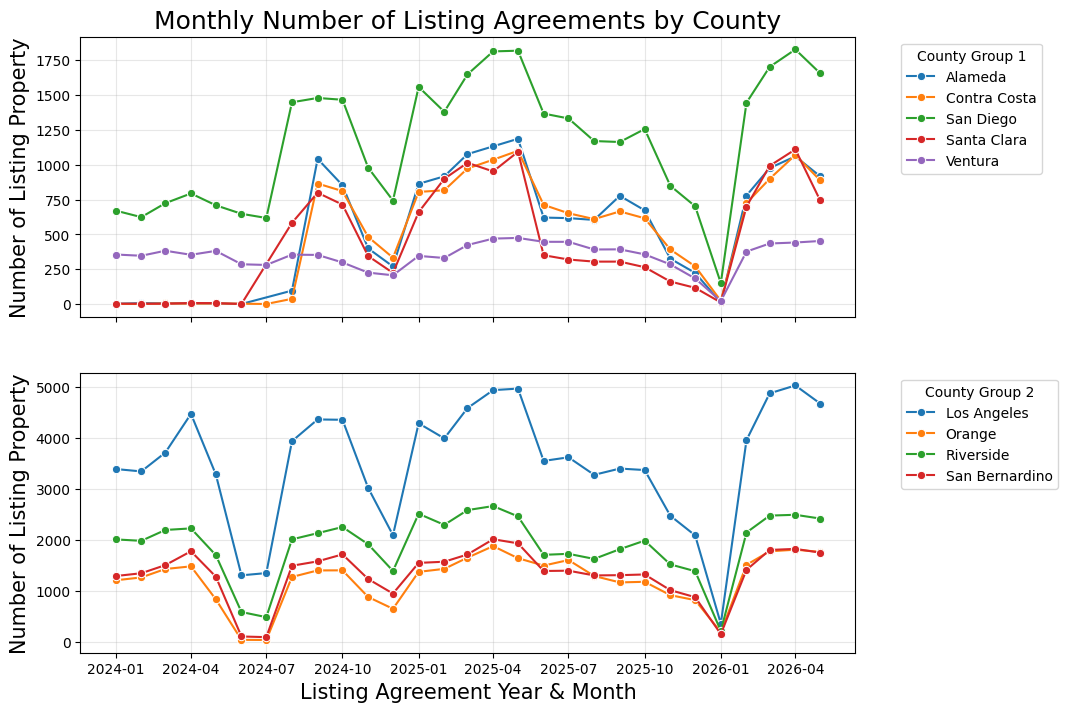

In [256]:
# assign the graph location and settings
fig, axes = plt.subplots(2,1, figsize=(10, 8), sharex = True)

# first graph of group of county 1
sns.lineplot(
    data = contract_county1,
    x = "ListYearMonth",
    y = "ListingCount",
    hue = "CountyOrParish",
    marker = "o",
    ax = axes[0]
)

axes[0].set_title("Monthly Number of Listing Agreements by County", fontsize = 18)
axes[0].set_ylabel("Number of Listing Property", fontsize = 15)
axes[0].grid(alpha=0.3)

axes[0].legend(
    title="County Group 1",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)


# second graph for gourp county 2
sns.lineplot(
    data = contract_county2,
    x = "ListYearMonth",
    y = "ListingCount",
    hue = "CountyOrParish",
    marker = "o",
    ax = axes[1]    
)

axes[1].set_xlabel("Listing Agreement Year & Month", fontsize = 15)
axes[1].set_ylabel("Number of Listing Property", fontsize = 15)
axes[1].grid(alpha=0.3)

axes[1].legend(
    title="County Group 2",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.show()

- ***Group 1***
    - ***Alameda*** and ***Contra Costa*** behaves similarily on number of properties listed in the market. They have fluctuation in the range of 0 to 1,000 properties through timeline.

    - ***Santa Clara, Contra Consta***, and ***Alameda*** didn't have new listing properties from Janaury till June 2024. 

    - ***San Diego, Santa Clara, Contra Consta***, and ***Alameda*** have similar movement. Their number of new listing properties increased from around June or July till September or October, then it declined till December in 2024. In 2025, it gradually recovered till May, then it gradually declined again till next year 2026.

    - ***Ventura*** has stable movement comparing to other major counties in the range between about 0 to 500 properties listed new agreements through this timeline.

    - All the group 1 major counties had low functuation of number of new listing properties during January till around June or July in 2024.

- ***Group 2***

    - ***Los Angeles*** has the highest amount of new properties listed in the market among all the major counties.

    - All the group 2 had the similar movement of number of new listing properties in the market through this timeline. The only differnece is the amount of properties they were came into the inventory.

    - They gradaully increased from January till April, then declined till July, then recovered till October, then declined again till December in 2024. In 2025, they gradually increased till April as peak of number of new listings, then gradually declined next year January 2026. Then they recovred for early 2026.

    - There are potential seasonal pattern that early term from January till April have increased the number of new listings agreements, then it declines until random month of its year. 

 
- Group 1 and Group 2 have their each similar behavior.

### Timeline Listing Price by County

We have eplored the timeline on number of new listings properties across California counties. We will explore the price across the counties through the timeline. We use list price instead of original price that those performed similary in previous analysis. 

We have alreday made the dataset of ***contract_county*** that grouped within listing contract date and counties measuring median list price above. We will use that data to produce the timeline chart for the analysis.

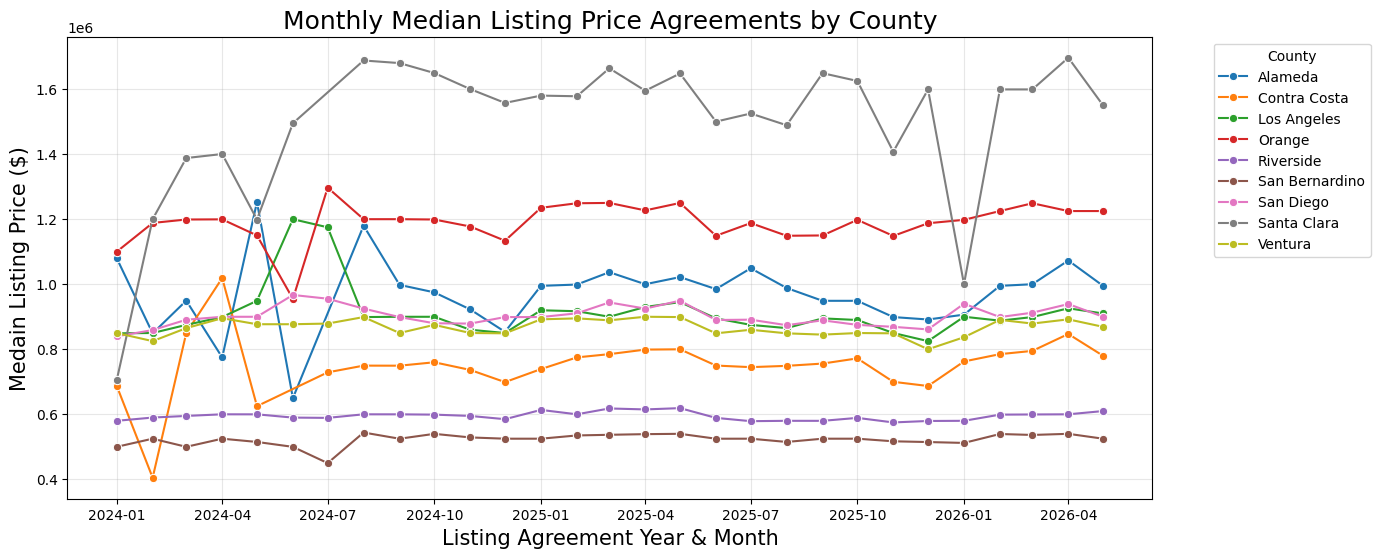

In [257]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=contract_county,
    x="ListYearMonth",
    y="MedianListPrice",
    hue="CountyOrParish",
    marker="o"
)

plt.legend(
    title="County",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.title("Monthly Median Listing Price Agreements by County", fontsize = 18)
plt.xlabel("Listing Agreement Year & Month", fontsize = 15)
plt.ylabel("Medain Listing Price ($)", fontsize = 15)
plt.grid(alpha=0.3)
plt.show()

This is overall of distribution on median listed price across counties. Let's divide into two different group of counties for easier analysis.

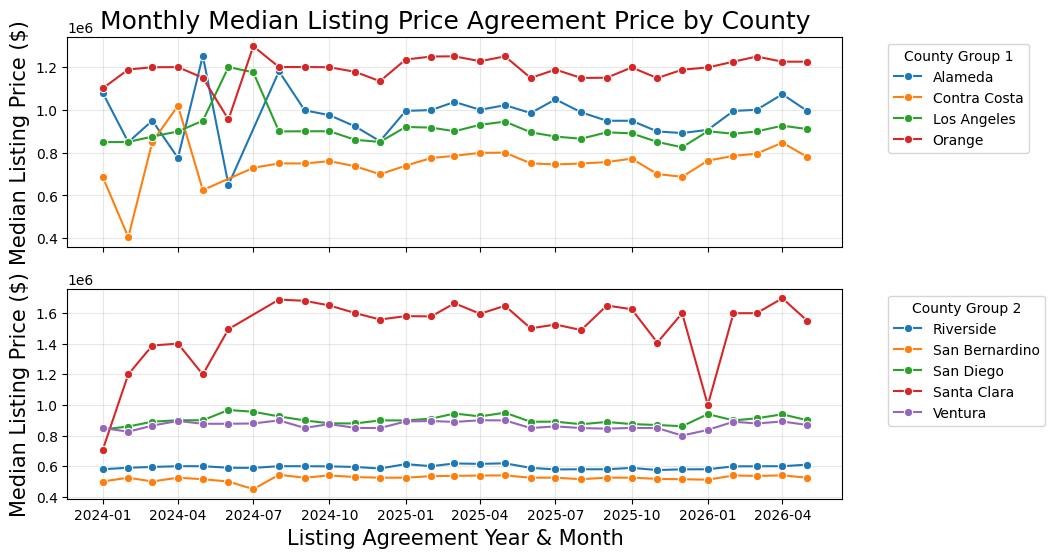

In [258]:
# divide counties into two groups
counties_group1 = [
    "Alameda",
    "Contra Costa",
    "Los Angeles",
    "Orange",

]

counties_group2 = [

    "Riverside",
    "San Bernardino",
    "San Diego",
    "Ventura",
    "Santa Clara",
]


# filter data group county 1
county_price_group1 = df_county_analysis_all[
    df_county_analysis_all["CountyOrParish"].isin(counties_group1)
]

# filter data group county 2
county_price_group2 = df_county_analysis_all[
    df_county_analysis_all["CountyOrParish"].isin(counties_group2)
]

contract_county1_price = (
    county_price_group1
    .groupby(["ListYearMonth", "CountyOrParish"])
    .agg(
        Count = ("ListingKey", "count"),
        MedianListPrice = ("ListPrice", "median")
    ).reset_index()
)

contract_county2_price = (
    county_price_group2
    .groupby(["ListYearMonth", "CountyOrParish"])
    .agg(
        Count = ("ListingKey", "count"),
        MedianListPrice = ("ListPrice", "median")
    ).reset_index()
)

# graph: first county group with listing price 
fig, axes = plt.subplots(2,1, figsize=(10, 6), sharex = True)

sns.lineplot(
    data = contract_county1_price,
    x = "ListYearMonth",
    y = "MedianListPrice",
    hue = "CountyOrParish",
    marker = "o",
    ax = axes[0]
)

axes[0].set_title("Monthly Median Listing Price Agreement Price by County", fontsize = 18)
axes[0].set_ylabel("Median Listing Price ($)", fontsize = 15)
axes[0].grid(alpha=0.3)

axes[0].legend(
    title="County Group 1",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

# graph: second county group with listing price 
sns.lineplot(
    data = contract_county2_price,
    x = "ListYearMonth",
    y = "MedianListPrice",
    hue = "CountyOrParish",
    marker = "o",
    ax = axes[1]    
)

axes[1].set_xlabel("Listing Agreement Year & Month", fontsize = 15)
axes[1].set_ylabel("Median Listing Price ($)", fontsize = 15)
axes[1].grid(alpha=0.3)

axes[1].legend(
    title="County Group 2",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.show()


- ***Group 1***

    - ***Alameda*** had strong fluctuation on listed median price from January till August in 2024, then it stables movement in the range between about $\$700,0000$ ~ $\$1,500,000$ till May 2026. 

    - ***Constra Costa*** had declined median listed price January till February, then it increased till April, then it declined on May in 2024. After, it mostly behaved stabled through May 2026 in the range of bewteen around $\$600,000$ ~ $\$850,000$.

    - ***Los Angeles*** had stabled movement of median listed price throughout this timeline in the range between around $\$850,000$ ~ $\$950,000$, except it had increased on May till July 2024 around $\$1,200,000$, then it declined on August. 

    - ***Orange*** had stabled movement of median listed price throughout this timeline in the range bewteen around $\$1,500,000$ ~$\$1,250,000$, except it had declined around 95,000 on June, then it recovered around $\$135,000$ on July 2024.


- ***Group 2***

    - ***Santa Clara*** of median listed price had increased from January till August 2024 from $\$700,000$ till $\$1,700,000$, then stabled in the range of berween around $\$1,400,000$ ~ $\$1,700,000$ untill December 2025. Then it declined around $\$1,000,000$ on January 2026, then it recovered $\$1,600,000$ on next month, then it moved in the stabled range.

    - ***San Bernardino*** in the range bewteen around $\$450,000$ ~ $\$550,000$, ***San Diego*** in the range bewteen around $\$850,000$ ~ $\$950,000$, ***Riverside*** in the range bewteen around $\$550,000$ ~ $\$650,000$, and ***Ventura*** in the range bewteen around $\$800,000$ ~ $\$900,000$, had strong stabled movement through this timeline. 

## Multivariate Listing Market Analysis

In [259]:
county_multi = (
    df_county_analysis
    .groupby("CountyOrParish")
    .agg(
        MedianListPPSF=("ListPerSqft", "median"),
        MedianDOM=("DaysOnMarket", "median"),
        ActiveCount=("ListingKey", "count")
    )
    .reset_index()
)

county_multi

,CountyOrParish,MedianListPPSF,MedianDOM,ActiveCount
0,Alameda,640.696609,11.0,6459
1,Contra Costa,483.319076,11.0,6267
2,Los Angeles,630.623686,11.0,50221
3,Orange,706.149797,11.0,14278
4,Riverside,321.397757,10.0,30627
5,San Bernardino,333.839299,8.0,20526
6,San Diego,598.501873,7.0,14611
7,Santa Clara,933.056872,14.0,5271
8,Ventura,530.864198,10.0,4807


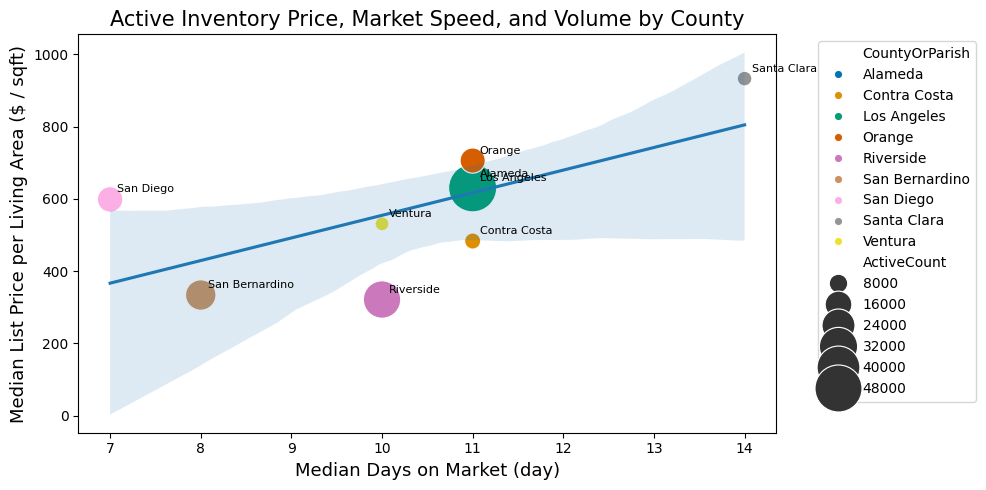

In [293]:
plt.figure(figsize=(10, 5))

# Bubble scatter plot
sns.scatterplot(
    data=county_multi,
    x="MedianDOM",
    y="MedianListPPSF",
    size="ActiveCount",
    sizes=(100, 1200),
    hue="CountyOrParish",
    palette="colorblind",
    legend="brief"
)

# Add county labels
for _, row in county_multi.iterrows():
    plt.annotate(
        row["CountyOrParish"],
        (row["MedianDOM"], row["MedianListPPSF"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

# Add linear trend line
sns.regplot(
    data=county_multi,
    x="MedianDOM",
    y="MedianListPPSF",
    scatter=False,
    ci=95
)
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xlabel("Median Days on Market (day)", fontsize = 13)
plt.ylabel("Median List Price per Living Area ($ / sqft)", fontsize = 13)
plt.title("Active Inventory Price, Market Speed, and Volume by County", fontsize = 15)

plt.tight_layout()
plt.show()

- ***Los Angeles*** remains the largest market, with $50,221$ active listing properties and a median list price of about $631 \,\$ / sqft$.

- Higher value coastal markets such as ***Santa Clara*** ($993 \,\$ / sqft$), ***Orange*** ($706 \,\$ / sqft$), ***Alameda*** ($641 \,\$ / sqft$), and ***San Diego*** ($559 \,\$ / sqft$) continue to command substantially higher asking prices than inland markets such as ***Riverside*** ($321 \,\$ / sqft$) and ***San Bernardino*** ($334 \,\$ / sqft$).

- Current market exposure, however, does not follow price level perfectly. ***Santa Clara*** has the highest asking price per square foot but also the longest median active DOM at $14$ days, while **San Diego** combines a relatively high asking price with the shortest median DOM at $7$ days. This suggests that local demand and inventory conditions vary substantially across counties and that price alone does not determine how quickly active inventory moves.



#### 2. Property Age x Days on Market x List Price 

In [261]:
county_age = (
    df_county_analysis
    .groupby(["CountyOrParish", "Group_PropertyAge"])
    .agg(
        MedianDOM=("DaysOnMarket", "median"),
        Count=("ListingKey", "count")
    )
    .reset_index()
)

county_age

,CountyOrParish,Group_PropertyAge,MedianDOM,Count
0,Alameda,0-5,13.0,185
1,Alameda,11-20,10.5,382
2,Alameda,21-40,11.0,1117
3,Alameda,41-70,12.0,2159
4,Alameda,6-10,12.0,286
5,Alameda,70+,11.0,2330
6,Contra Costa,0-5,13.0,230
7,Contra Costa,11-20,12.0,399
8,Contra Costa,21-40,11.0,1818
9,Contra Costa,41-70,11.0,2664


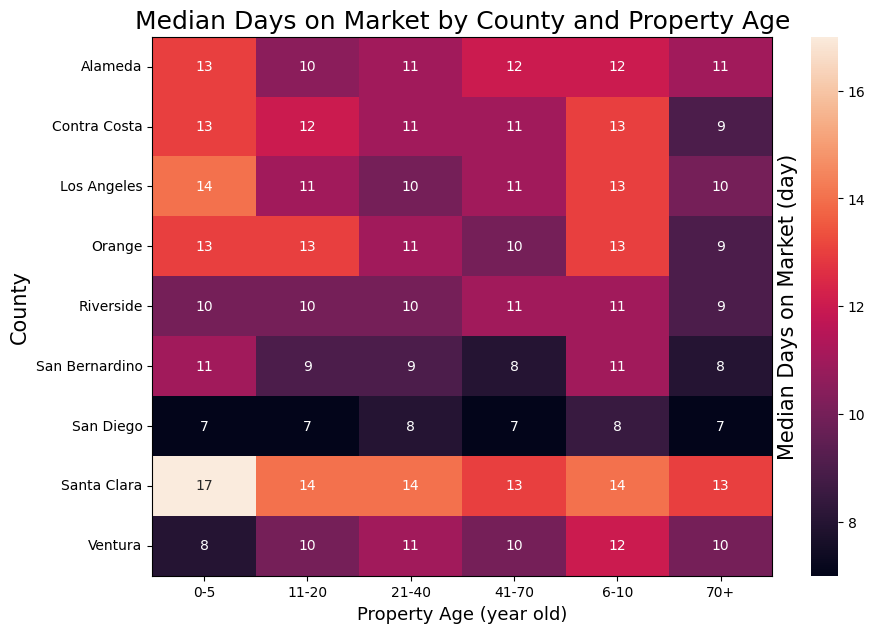

In [282]:
fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    heat,
    annot=True,
    fmt=".0f",
    ax=ax
)

ax.set_ylabel("County", fontsize=15)
ax.set_xlabel("Property Age (year old)", fontsize  = 13)
ax.set_title("Median Days on Market by County and Property Age", fontsize = 18)
ax2 = ax.twinx()
ax2.set_ylabel("Median Days on Market (day)", fontsize=15)
ax2.set_yticks([])

plt.show()

- County appears to matter more than property age for listing days on market. ***San Diego*** has the lowest median DOM across nearly all age groups at about $7$ ~ $8$ days, while ***Santa Clara*** is the highest at about $13$ ~ $17$ days

- Within some counties, older homes have lower DOM. For example, ***Los Angeles*** drops from $14$ days for $0$ ~ $5$ year old homes to 10 days for $70+$ homes, and ***Orange*** drops from $13$ days to $9$ days.

- But the age pattern is not consistent everywhere. ***Riverside*** stays fairly stable around $9$ ~ $11$ days, while ***Ventura*** varies from $8$ to $12$ days without a clear age trend.

- Listing speed differs more clearly by county than by property age. Property age may matter in some counties, but its relationship with DOM is not consistent across all markets.

#### 3. Mortgage Rate × New Listings × Days On Market over time

In [263]:
monthly_market = (
    df_list_eda
    .groupby("ListYearMonth")
    .agg(
        MortgageRate=("MortgageRate30Fixed", "median"),
        NewListingCount=("ListingKey", "count"),
        MedianDOM=("DaysOnMarket", "median")
    )
    .reset_index()
)

monthly_market

,ListYearMonth,MortgageRate,NewListingCount,MedianDOM
0,2024-01-01,6.6425,9744,16.0
1,2024-02-01,6.7760,9736,14.0
2,2024-03-01,6.8200,10969,14.0
3,2024-04-01,6.9925,12262,8.0
4,2024-05-01,7.0600,9065,8.0
5,2024-06-01,6.9175,3014,8.0
6,2024-07-01,6.8475,2901,8.0
7,2024-08-01,6.5000,12794,7.0
8,2024-09-01,6.1800,16054,10.0
9,2024-10-01,6.4280,15889,10.0


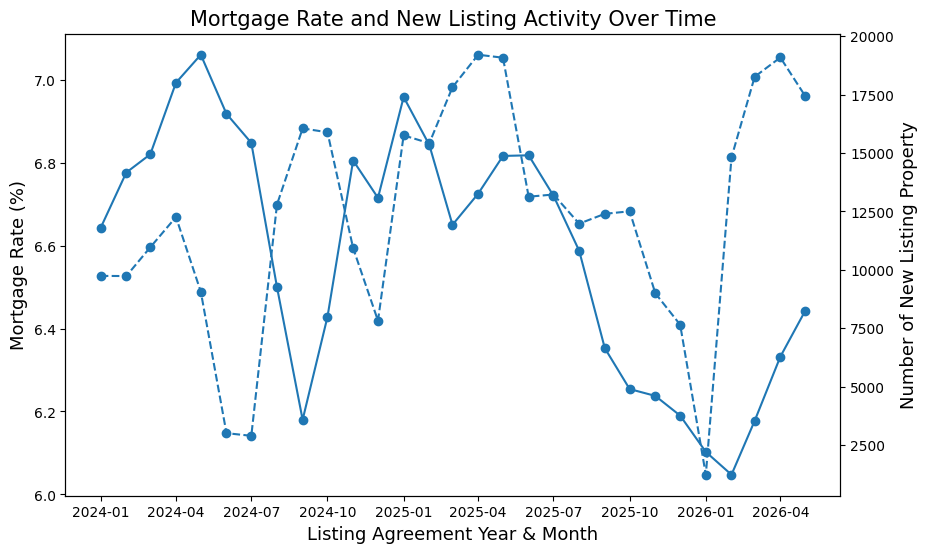

In [292]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Mortgage Rate
ax1.plot(
    monthly_market["ListYearMonth"],
    monthly_market["MortgageRate"],
    marker="o",
    label="Mortgage Rate"
)

ax1.set_xlabel("Listing Agreement Year & Month", fontsize = 13)
ax1.set_ylabel("Mortgage Rate (%)", fontsize = 13)

# New Listings
ax2 = ax1.twinx()

ax2.plot(
    monthly_market["ListYearMonth"],
    monthly_market["NewListingCount"],
    marker="o",
    linestyle="--",
    label="New Listings"
)

ax2.set_ylabel("Number of New Listing Property", fontsize = 13)

plt.title("Mortgage Rate and New Listing Activity Over Time", fontsize = 15)
plt.show()

new listing activity does not move consistently with mortgage rates

- In April till May 2024, mortgage rates were very high, around $6.99\%$ $7.06\%$, but new listings were still around 12,262 in April and 9,065 in May. In Sep–Oct 2024, rates fell to about 6.18–6.43%, while new listings increased to roughly 16,054–15,889.

- In March till May 2025, listings were especially high, around $17,817$ ~ $19,207$, even though mortgage rates were still around $6.65\%$ ~ $6.82\%$.

- In February till April 2026, rates were lower, about $6.05\%$ ~ $6.33\%$, and new listings were again high at roughly $14,811$ till $19,089$.

- Monthly new listing volume showed no clear one-to-one relationship with mortgage rates. Listing activity appears to be influenced strongly by seasonality and other market factors, with higher listing counts often occurring in spring even when mortgage rates remained elevated.

# Summary

## 1. Key Findings

- The analysis of California residential listing records from January 2024 through May 2026 revealed substantial differences in asking prices, property characteristics, market exposure, and geographic listing activity.

    - Among 174,303 Active listings, the median list price was approximately $770,000, with an interquartile range (IQR) from $540,000 to $1,190,000. The median original list price was approximately $775,000, suggesting that the overall typical recorded asking price was slightly lower than the initial asking price.

    - Single-family residences dominated the Active listing dataset, accounting for approximately 74.5% of properties, followed by condominiums (17.1%) and townhouses (4.7%). This indicates that overall listing-market statistics are strongly influenced by single-family residences.

- Property characteristics were associated with differences in asking prices, particularly living area, bedrooms, bathrooms, and property subtype.

    - Living area showed a moderate positive Spearman correlation with list price (ρ ≈ 0.512), suggesting that larger properties generally had higher asking prices. However, substantial price variation remained among properties of similar sizes, indicating that living area alone cannot fully explain differences in asking prices.

    - Single-family residences had the highest median asking price among the three major property subtypes at approximately $835,000, followed by townhouses ($778,000) and condominiums ($615,000).

    - However, the pattern differed when comparing price per square foot. Condominiums had the highest median asking price per square foot at approximately $560, followed by townhouses ($543) and single-family residences ($485). This suggests that smaller attached housing types may carry relatively higher asking prices per unit of living space despite having lower total asking prices.

    - Kruskal–Wallis tests identified statistically significant differences in asking-price distributions across property subtypes. However, substantial overlap between their distributions suggests that property subtype should not be considered an independent explanation of price differences.

- The Active listing dataset had a median Days on Market (DOM) of approximately 10 days, with an IQR from 4 to 21 days.

    - Among Active properties, approximately 152,773 had recorded DOM of 30 days or fewer, while 16,585 had DOM between 31 and 90 days, and 4,880 had remained on the market for more than 90 days.

    - A downward pattern was observed between market exposure and asking prices. Active properties with DOM of 30 days or fewer had a median list price of approximately $775,000, compared with $650,000 for those with DOM greater than 90 days.

    - A similar pattern appeared in asking price per square foot, declining from approximately $506 for shorter-exposure listings to $418 for listings with longer exposure.

    - Furthermore, the median ratio of ListPrice to OriginalListPrice declined from approximately 1.00 among properties with shorter market exposure to 0.987 among those remaining Active for more than 90 days.

    - These findings suggest that longer-exposure Active properties are associated with lower asking-price levels and a greater degree of asking-price adjustment relative to their original prices.

    - However, these relationships do not establish that price reductions cause properties to remain on the market longer. Differences in location, property condition, initial pricing, and other characteristics may contribute to the observed patterns.

- County level analysis revealed substantial differences in asking prices, price per square foot, and market exposure across California.

    - Santa Clara had the highest median Active list price among the major counties at approximately $1,549,000, while San Bernardino had the lowest at approximately $525,000.

    - Santa Clara: approximately 933 $/sqft

    - Orange: approximately 706 $/sqft

    - Alameda: approximately 641 $/sqft

    - Los Angeles: approximately 631 $/sqft

    - San Diego: approximately 599 $/sqft

    - San Bernardino: approximately 334 $/sqft

    - Riverside: approximately 321 $/sqft

    - These results highlight substantial differences between higher-priced coastal markets and comparatively lower-priced inland markets. However, higher asking prices did not consistently correspond to shorter market exposure.

    - Santa Clara had the highest median asking price per square foot but also the longest median Active DOM among the major counties at 14 days. In contrast, San Diego had a median asking price of approximately $599/sqft and the shortest median Active DOM at 7 days.

    - This indicates that asking-price levels and market exposure vary differently across counties. Therefore, listing prices and market conditions should be evaluated within individual geographic markets rather than relying solely on statewide averages.


- Property age showed some relationship with asking prices and Active DOM, although the patterns were not consistent across all counties.

    - For example, properties older than 70 years had a median Active list price of approximately $925,000, compared with $699,000 for properties aged 21 ~ 40 years. This does not necessarily indicate that older properties command higher prices because of age, since older housing stock may be concentrated in more expensive locations.

    - Similarly, property age groups showed relatively small differences in median Active DOM, generally around 10 ~ 12 days.

    - The multivariate county by age analysis showed that geographic differences were more pronounced than age differences. San Diego consistently showed relatively low median Active DOM across most age groups, while Santa Clara generally showed longer market exposure.

    - These findings suggest that geographic context is important when evaluating the relationship between property age and listing performance.

- The number of listing properties of all MLS status and Active status follows the similar behavrior from January 2024 till May 2025, which it indicates that there are still many active properties in the inventory across Califronia, and difference shows the number of properties that are not active in the market as pending, under contract, or closed. 

    - However,  the properties new listed from June 2025 till January 2026, both all MLS and Active status faced different behavior which it shows that there were many properties that were not active than active properties in the market. Many properties where new listed that term had been processed to closed.
    
- The original list price and list price tend to follow similarily, but list prices are slightly greater than original list prices about $\$10,000$ difference from only June through December 2025.

    - There are potential pattern for listed price that it tends to increase from January till May, then it starts to decrease gradually July till Decemeber in each year. Additionally, there are not clear pattern in Active status properties that were remained in current inventory in each term.

- Across the major counties in California, the number of new listed properties showed fluctuation performance on similar group of (Los Angeles, Orange, Riverside, San Bernardino),  and (Alameda, Constra Costa, San Diego, Santa Clara). However, the Ventrua had stable movement alone through this timeline stage. 

    - Alameda, Contra Costa, Los Angeles, and Orange had fluctuation of median listed price  from January till July and August 2024, then it relatively stabled through May 2026. Riverside, San Bernardino, San Diego, and Ventura had stabled listing price throughout this timeline. 

- Monthly mortgage rates were compared with new listing counts, median Active DOM, and median list prices.

    - The results showed relatively weak linear associations:

        - Mortgage rate vs. new listing count: r ≈ −0.092

        - Mortgage rate vs. median Active DOM: r ≈ −0.015

        - Mortgage rate vs. median list price: r ≈ 0.109

    - These results indicate that mortgage rates alone did not show a strong contemporaneous linear relationship with the selected monthly listing-market indicators during the study period.

    - While borrowing costs are relevant to housing affordability and purchasing decisions, the findings suggest that listing activity and asking-price patterns also reflect other market characteristics.


## 2. Limitation

- Most analyses of asking prices, property characteristics, and DOM focused on properties classified as Active. These records describe the asking prices and recorded market exposure of properties that remained available, rather than completed transactions. Therefore, Active DOM cannot be interpreted as time required to sell a property. Similarly, lower asking prices among longer-exposure Active listings do not demonstrate that those properties eventually sold for lower prices.

- January 2026 that all the MLS status properties had declined into lowest number of new listing properties agreement.  The potential reason might be the real estate listing agreements were shaped by updated California Association of REALTORS standard forms and new sate laws and Department of Real Estate exclusive right-to-sell listing agreement, these updates added stricter marketing, disclosure, and representation rules. https://www.pwr.net/blog/new-c-a-r-forms-for-2026-key-updates-realtors-must-know-tri 

- Several statistical tests identified significant differences across property subtypes, counties, property-age groups, and DOM categories. However, the large sample size can produce statistically significant results even when the practical differences between groups are relatively small .Moreover, the analysis is primarily descriptive and does not simultaneously control for location, living area, property condition, subtype, and other potentially influential variables.Therefore, observed associations should not be interpreted as causal relationships.

- The mortgage-rate analysis used aggregated monthly data and simple correlations. These measurements do not account for delayed market responses, local financing conditions, seasonal effects, economic changes, or differences in buyer demographics. Consequently, the weak correlations should not be interpreted as evidence that mortgage rates have no influence on housing-market conditions.




## 3. Recommendations 

- **Sellers and real estate agents: Develop locally competitive pricing strategies**

    - Sellers and real estate agents should develop competitive listing-price strategies by comparing properties within similar geographic markets, property subtypes, and physical characteristics rather than relying solely on statewide asking-price averages. The analysis revealed substantial geographic differences in asking prices per square foot. For example, Santa Clara had a median asking price of approximately $933/sqft, compared with $321/sqft in Riverside and $334/sqft in San Bernardino. These differences suggest that local market conditions play an important role in establishing appropriate asking prices.

    - Additionally, property characteristics should be considered when determining an initial asking price. Living area showed a moderate positive correlation with list price (ρ ≈ 0.512), while single-family residences had higher median total asking prices than condominiums and townhouses. However, condominiums had the highest median asking price per square foot among the three major property subtypes.

    - Furthermore, sellers and agents should regularly monitor properties with extended market exposure and reassess their pricing strategies when necessary. Active properties with DOM greater than 90 days had a median list price of approximately $650,000, compared with $775,000 among properties with DOM of 30 days or fewer. The median ListPrice-to-OriginalListPrice ratio also declined from approximately 1.00 to 0.987 across these groups.

    - These findings suggest that longer-exposure listings are associated with lower asking prices and greater price adjustments. Therefore, sellers and agents should consider reviewing asking prices, property conditions, marketing strategies, and comparable listings when properties remain on the market longer than expected.

- **Buyers: Compare Asking Prices, Property Characteristics, and Market Exposure Before Making Offers**

    - Buyers should evaluate available residential properties using local asking-price comparisons, property characteristics, and recorded market exposure to identify suitable purchasing opportunities.The substantial differences in median asking prices per square foot across California counties suggest that buyers should consider geographic affordability when selecting properties. For example, Riverside and San Bernardino showed considerably lower median asking prices per square foot than Santa Clara and Orange, indicating different acquisition-price environments.

    - Buyers should also compare properties within the same subtype and similar living-area ranges rather than relying exclusively on total asking prices. Although single-family residences had the highest median total asking prices, condominiums had relatively higher median asking prices per square foot.

    - Additionally, properties with longer market exposure or reductions from their original asking prices may be worth further investigation when considering potential negotiation opportunities. However, longer Active DOM does not necessarily indicate that a seller is willing to accept a lower offer.

- **Real Estate Investors: Evaluate Property Investment Opportunities Using Geographic and Property-Level Comparisons**

    - Real estate investors should consider geographic asking-price differences, property subtypes, living area, and property age when evaluating potential investment opportunities. The analysis identified substantial differences in asking prices between coastal and inland California counties. Lower median asking prices per square foot in Riverside and San Bernardino may provide different acquisition-cost opportunities compared with higher-priced markets such as Santa Clara and Orange.

    - Additionally, investors should consider property characteristics and local market conditions together. For example, properties older than 70 years had higher median asking prices than properties aged 21–40 years. However, these differences may reflect the concentration of older properties in more expensive geographic markets rather than an independent relationship between building age and property value.

    - Nevertheless, lower asking prices or longer market exposure do not automatically indicate profitable investment opportunities. Additional analysis of completed sales, rental income, operating expenses, property condition, and potential returns would be required before making investment decisions.


    

# Export Data

We will export the ***df_list_eda*** where we improved data quality with cleaning missing values and filtering suspicous outliers. This data will use it on the **Tableau** for data visualization dashboard and showing its analysis with **data_list_eda** data.

In [ ]:
df_list_eda.to_csv("df_list_eda_tab.csv", index=False)